# Exploratory Data Analysis – NLR PEM Electrolyzer Dataset

**Project:** Uncertainty-Aware Explainable Digital Twin for Resilient Green Hydrogen Production

**Dataset:** NLR 1.25-MW PEM Electrolyzer – Simulated Wind Experiments

**Objective:** Explore data quality, operating conditions, hydrogen production, electrical performance, pressure, temperature, and relationships between variables before preprocessing and modelling.

In [ ]:
# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:
# Cell 2: Upload NLR dataset

uploaded = files.upload()

Saving combined_wind_experiments.csv to combined_wind_experiments (2).csv


In [ ]:
# Cell 3: Load the NLR dataset

file_path = "combined_wind_experiments.csv"

df = pd.read_csv(file_path)

print("NLR dataset loaded successfully!")
print("Dataset shape:", df.shape)

NLR dataset loaded successfully!
Dataset shape: (61285, 32)


In [ ]:
# Cell 4: Initial dataset structure

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("FIRST 5 OBSERVATIONS")
print("=" * 60)

display(df.head())

print("\n" + "=" * 60)
print("COLUMN NAMES")
print("=" * 60)

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61285 entries, 0 to 61284
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Unnamed: 0                          61285 non-null  object 
 1   Wind Turbine Power (kW)             43285 non-null  float64
 2   H2E_f_NLR_CurrentCmd (A)            61285 non-null  float64
 3   IVAL_f_FM011_Flow                   61284 non-null  float64
 4   Efficiency (kWh/kg)                 61284 non-null  float64
 5   Power Supply Average Voltage (Vdc)  61285 non-null  float64
 6   H2E_f_NLR_CurrentCmd                61285 non-null  float64
 7   H2E_n_PSU_A_Power                   61285 non-null  int64  
 8   H2E_f_PSU_A_Current                 61285 non-null  int64  
 9   H2E_f_Elec_CalcProdRate             61285 non-null  float64
 10  H2E_f_CG220_LFLPer                  61285 non-null  float64
 11  H2E_f_DPS340_DPdegC  

,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Experiment,Unnamed: 31
0,6/4/2025 10:32,350.14,995.024,7.305,47.638604,346.100,33.167,348,993,7.423,0.123,-52.222,-45.451,2.276,60.823,29.549,2.836,28.967,25.669,4.331,6.377,13.699,58.333,59.028,13.447,16.742,17.4,7.2,10.1,15.2,windIEA3.4-7ms-C_1-200.csv,NaN
1,6/4/2025 10:32,585.70,1604.360,7.276,47.965915,346.433,53.479,349,997,8.024,0.119,-52.292,-45.451,2.276,60.829,29.549,2.827,28.966,25.668,4.332,6.381,13.889,58.333,59.028,13.442,16.747,17.3,7.2,10.0,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
2,6/4/2025 10:32,778.30,2067.155,7.251,58.198869,352.200,68.905,422,1181,9.377,0.119,-52.292,-45.451,2.276,60.832,29.549,2.846,28.967,25.668,4.334,6.383,13.889,58.333,59.028,13.442,16.753,17.4,7.3,10.1,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
3,6/4/2025 10:32,903.86,2523.305,7.166,68.936645,357.700,84.110,494,1359,10.786,0.119,-52.222,-45.451,2.275,60.835,29.555,2.855,28.981,25.668,4.336,6.384,13.889,58.333,59.028,13.437,16.758,17.3,7.2,10.1,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
4,6/4/2025 10:32,982.63,2608.763,7.405,77.245105,363.333,86.959,572,1550,12.051,0.119,-52.292,-45.451,2.273,60.830,29.547,2.853,29.010,25.668,4.336,6.395,13.699,58.102,59.028,13.437,16.758,17.3,7.2,10.1,15.4,windIEA3.4-7ms-C_1-200.csv,NaN



COLUMN NAMES
01. Unnamed: 0
02. Wind Turbine Power (kW)
03. H2E_f_NLR_CurrentCmd (A)
04. IVAL_f_FM011_Flow
05. Efficiency (kWh/kg)
06. Power Supply Average Voltage (Vdc)
07. H2E_f_NLR_CurrentCmd
08. H2E_n_PSU_A_Power
09. H2E_f_PSU_A_Current
10. H2E_f_Elec_CalcProdRate
11. H2E_f_CG220_LFLPer
12. H2E_f_DPS340_DPdegC
13. H2E_f_DPS341_DPdegC
14. H2E_f_DPS341_DPppmV
15. H2E_f_LS201_H2OLevel
16. H2E_f_LS301_H2OLevel
17. H2E_f_PT264_Pressure
18. H2E_f_PT307_Pressure
19. H2E_f_PT312_Pressure
20. H2E_f_PT604_Pressure
21. H2E_f_RS209_Resistivity
22. H2E_f_RS507_Resistivity
23. H2E_f_TE218_Temp
24. H2E_f_TE219_Temp
25. H2E_f_TE338_Temp
26. H2E_f_TE601_Temp
27. H2E_f_TT641_Temp
28. H2E_f_TT645_Temp
29. H2E_f_TT646_Temp
30. H2E_f_TT647_Temp
31. Experiment
32. Unnamed: 31


In [ ]:
# Cell 5: Missing Value Analysis

missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_analysis = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage,
    "Available Values": df.notnull().sum()
})

missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_analysis.round(3))

print("\nTotal missing cells:", missing_count.sum())
print("Total dataset cells:", df.size)
print(
    "Overall missing percentage:",
    round((missing_count.sum() / df.size) * 100, 3),
    "%"
)

,Missing Values,Missing Percentage (%),Available Values
Unnamed: 31,46972,76.645,14313
Wind Turbine Power (kW),18000,29.371,43285
H2E_f_TT641_Temp,14313,23.355,46972
IVAL_f_FM011_Flow,1,0.002,61284
Efficiency (kWh/kg),1,0.002,61284
Power Supply Average Voltage (Vdc),0,0.000,61285
H2E_f_NLR_CurrentCmd (A),0,0.000,61285
Unnamed: 0,0,0.000,61285
H2E_f_PSU_A_Current,0,0.000,61285
H2E_f_Elec_CalcProdRate,0,0.000,61285



Total missing cells: 79287
Total dataset cells: 1961120
Overall missing percentage: 4.043 %


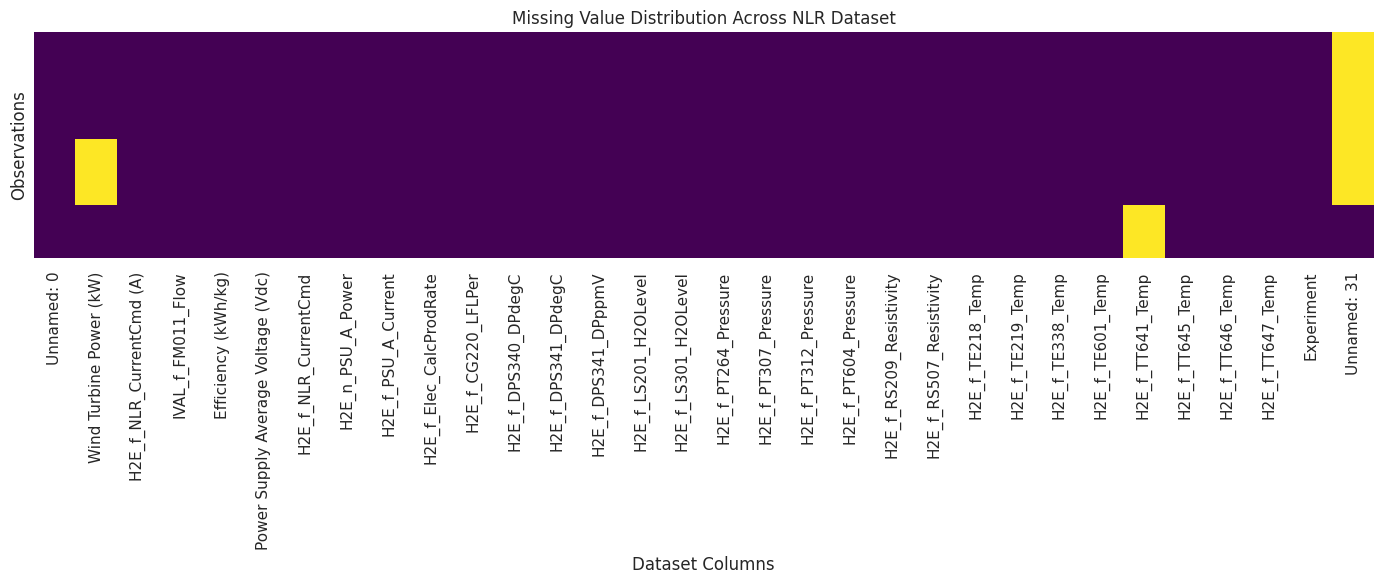

In [ ]:
# Cell 6: Visualize missing-value patterns

plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Value Distribution Across NLR Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Observations")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
missing_by_experiment["missing_wind_power"] = (
    df.groupby("Experiment")["Wind Turbine Power (kW)"].apply(lambda x: x.isna().sum())
)

display(missing_by_experiment)

,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Unnamed: 31,missing_wind_power
Experiment,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
characterization_200.csv,0,18000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,18000,18000
windIEA3.4-5ms-A_2-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652,0
windIEA3.4-5ms-A_2-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652,0
windIEA3.4-5ms-C_2-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652,0
windIEA3.4-5ms-C_2-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652,0
windIEA3.4-7ms-A_1-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591,0
windIEA3.4-7ms-A_1-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591,0
windIEA3.4-7ms-C_1-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591,0
windIEA3.4-7ms-C_1-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591,0


In [ ]:
# Cell 9: Descriptive statistics of numerical variables

numerical_columns = df.select_dtypes(include=np.number).columns

descriptive_stats = df[numerical_columns].describe().T

descriptive_stats["missing_values"] = df[numerical_columns].isnull().sum()

display(descriptive_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,missing_values
Wind Turbine Power (kW),43285.0,668.415,284.642,20.560,437.610,657.400,887.460,1629.800,18000
H2E_f_NLR_CurrentCmd (A),61285.0,1733.457,738.793,300.000,1185.281,1774.056,2372.221,3000.000,0
IVAL_f_FM011_Flow,61284.0,12.675,5.777,0.005,8.328,12.901,17.486,33.339,1
Efficiency (kWh/kg),61284.0,115.773,956.487,21.113,47.790,51.663,55.789,40400.000,1
Power Supply Average Voltage (Vdc),61285.0,369.113,23.284,320.367,352.233,371.100,388.733,410.200,0
H2E_f_NLR_CurrentCmd,61285.0,57.782,24.626,10.000,39.509,59.135,79.074,100.000,0
H2E_n_PSU_A_Power,61285.0,668.341,319.012,97.000,423.000,668.000,939.000,1261.000,0
H2E_f_PSU_A_Current,61285.0,1731.253,737.996,295.000,1183.000,1771.000,2367.000,3003.000,0
H2E_f_Elec_CalcProdRate,61285.0,12.916,5.506,1.119,8.829,13.210,17.661,22.380,0
H2E_f_CG220_LFLPer,61285.0,0.258,0.673,0.119,0.123,0.123,0.123,4.348,0


In [ ]:
# Cell 10: Inspect the highest efficiency observations

efficiency_check = df.nlargest(
    10,
    "Efficiency (kWh/kg)"
)

columns_to_inspect = [
    "Experiment",
    "Efficiency (kWh/kg)",
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "H2E_n_PSU_A_Power",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)"
]

display(efficiency_check[columns_to_inspect])

,Experiment,Efficiency (kWh/kg),IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_n_PSU_A_Power,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc)
23510,windIEA3.4-5ms-C_2-400.csv,40400.00000,0.005,4.479,202,617.845,599,333.467
21029,windIEA3.4-5ms-A_2-400.csv,39857.14286,0.007,6.015,279,799.526,807,340.633
19360,windIEA3.4-5ms-A_2-400.csv,38142.85714,0.007,5.958,267,798.331,777,339.633
21028,windIEA3.4-5ms-A_2-400.csv,37142.85714,0.007,5.960,260,806.235,757,339.100
21024,windIEA3.4-5ms-A_2-400.csv,35857.14286,0.007,5.384,251,721.774,730,338.300
21027,windIEA3.4-5ms-A_2-400.csv,35285.71429,0.007,5.397,247,756.064,722,338.233
19352,windIEA3.4-5ms-A_2-400.csv,35166.66667,0.006,4.588,211,614.771,623,334.267
19355,windIEA3.4-5ms-A_2-400.csv,35000.00000,0.006,4.631,210,641.318,621,334.300
19356,windIEA3.4-5ms-A_2-400.csv,35000.00000,0.006,4.631,210,641.318,621,334.300
19353,windIEA3.4-5ms-A_2-400.csv,34666.66667,0.006,4.633,208,621.051,615,334.167


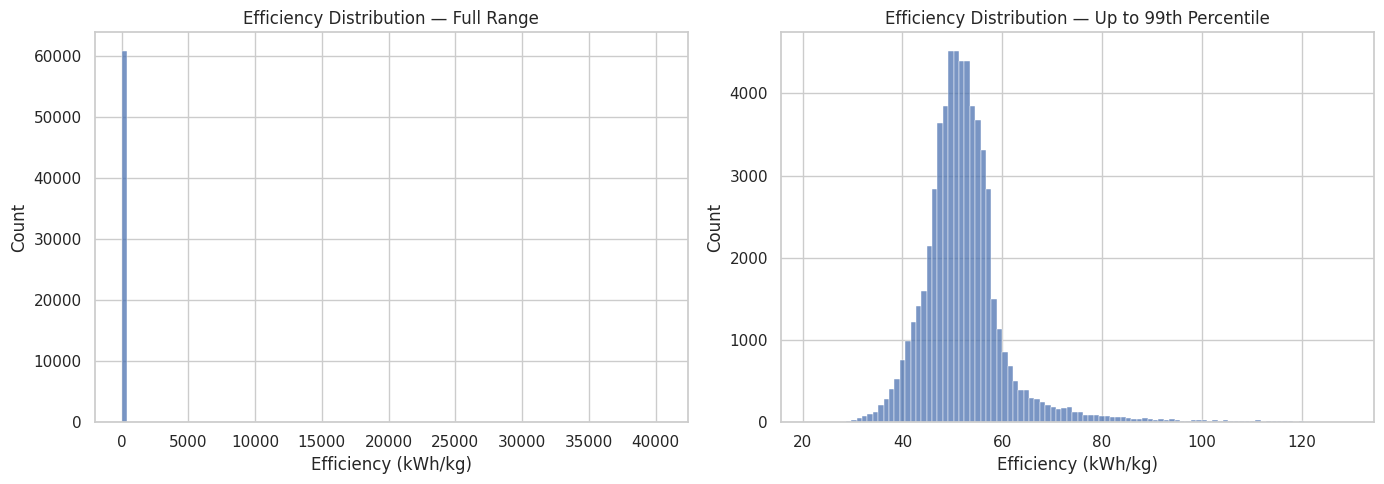

99th percentile: 129.385


In [ ]:
# Cell 11: Visualize efficiency distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full distribution
sns.histplot(
    data=df,
    x="Efficiency (kWh/kg)",
    bins=100,
    ax=axes[0]
)
axes[0].set_title("Efficiency Distribution — Full Range")
axes[0].set_xlabel("Efficiency (kWh/kg)")

# Zoomed distribution: up to the 99th percentile
efficiency_99 = df["Efficiency (kWh/kg)"].quantile(0.99)

sns.histplot(
    data=df[df["Efficiency (kWh/kg)"] <= efficiency_99],
    x="Efficiency (kWh/kg)",
    bins=100,
    ax=axes[1]
)
axes[1].set_title("Efficiency Distribution — Up to 99th Percentile")
axes[1].set_xlabel("Efficiency (kWh/kg)")

plt.tight_layout()
plt.show()

print("99th percentile:", round(efficiency_99, 3))

HYDROGEN FLOW — DESCRIPTIVE STATISTICS


,IVAL_f_FM011_Flow
count,61284.0000
mean,12.6751
std,5.7773
min,0.0050
1%,1.7997
5%,3.1662
10%,4.4260
25%,8.3280
50%,12.9010
75%,17.4860



OBSERVATIONS BELOW SELECTED FLOW LEVELS
Flow <= 0.01: 127 observations (0.207%)
Flow <= 0.05: 310 observations (0.506%)
Flow <= 0.1: 393 observations (0.641%)
Flow <= 0.5: 523 observations (0.853%)
Flow <= 1: 557 observations (0.909%)
Flow <= 2: 714 observations (1.165%)
Flow <= 5: 7360 observations (12.009%)


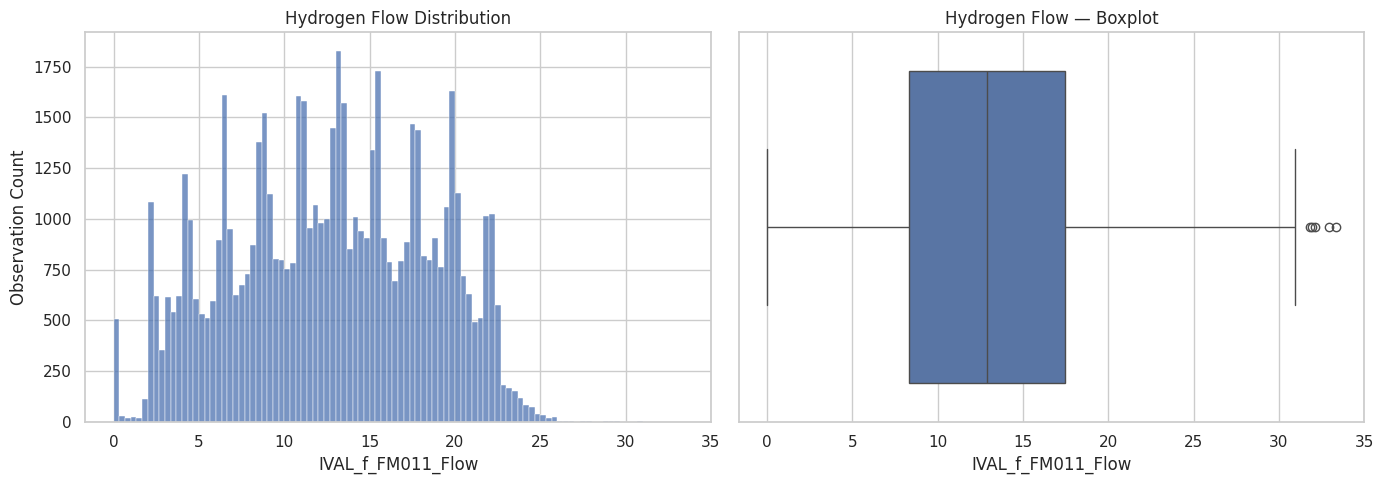

In [ ]:

# Cell 12 — Hydrogen Flow Distribution Analysis

flow_column = "IVAL_f_FM011_Flow"

# Descriptive statistics
flow_stats = df[flow_column].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("HYDROGEN FLOW — DESCRIPTIVE STATISTICS")
display(flow_stats.to_frame().round(4))

# Count observations at selected flow levels
flow_thresholds = [0.01, 0.05, 0.1, 0.5, 1, 2, 5]

print("\nOBSERVATIONS BELOW SELECTED FLOW LEVELS")

for threshold in flow_thresholds:
    count = (df[flow_column] <= threshold).sum()
    percentage = count / len(df) * 100

    print(
        f"Flow <= {threshold}: "
        f"{count} observations ({percentage:.3f}%)"
    )

# Visualize distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x=flow_column,
    bins=100,
    ax=axes[0]
)

axes[0].set_title("Hydrogen Flow Distribution")
axes[0].set_xlabel("IVAL_f_FM011_Flow")
axes[0].set_ylabel("Observation Count")

sns.boxplot(
    data=df,
    x=flow_column,
    ax=axes[1]
)

axes[1].set_title("Hydrogen Flow — Boxplot")
axes[1].set_xlabel("IVAL_f_FM011_Flow")

plt.tight_layout()
plt.show()


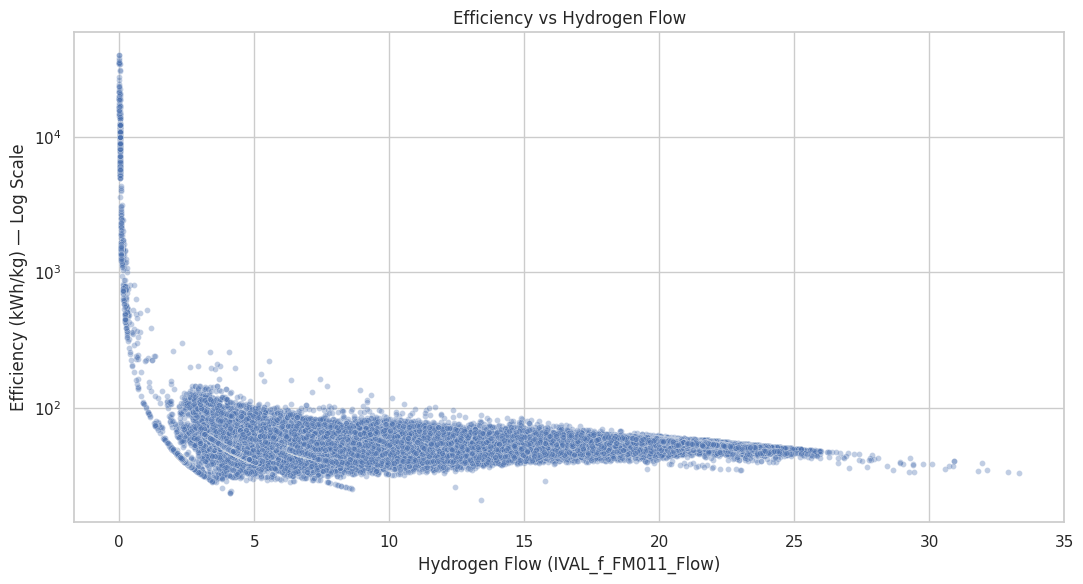

Pearson correlation:
-0.1446125982450214

Spearman correlation:
0.23967250971160017


In [ ]:

# Cell 13 — Relationship Between Efficiency and Hydrogen Flow

efficiency_column = "Efficiency (kWh/kg)"
flow_column = "IVAL_f_FM011_Flow"

# Select only the two required columns for visualization.
# Original dataframe remains unchanged.
efficiency_flow = df[
    [flow_column, efficiency_column]
].dropna()

# Scatter plot
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=efficiency_flow,
    x=flow_column,
    y=efficiency_column,
    alpha=0.35,
    s=18
)

plt.yscale("log")

plt.title("Efficiency vs Hydrogen Flow")
plt.xlabel("Hydrogen Flow (IVAL_f_FM011_Flow)")
plt.ylabel("Efficiency (kWh/kg) — Log Scale")

plt.tight_layout()
plt.show()

# Correlation analysis
print("Pearson correlation:")
print(
    efficiency_flow[flow_column].corr(
        efficiency_flow[efficiency_column],
        method="pearson"
    )
)

print("\nSpearman correlation:")
print(
    efficiency_flow[flow_column].corr(
        efficiency_flow[efficiency_column],
        method="spearman"
    )
)


MEASURED FLOW vs CALCULATED PRODUCTION RATE


,count,mean,std,min,25%,50%,75%,max
IVAL_f_FM011_Flow,61284.0,12.6751,5.7773,0.005,8.328,12.901,17.486,33.339
H2E_f_Elec_CalcProdRate,61284.0,12.9156,5.5059,1.119,8.829,13.210,17.661,22.380



Pearson correlation:
0.9677489111492246

Spearman correlation:
0.9698093874279671


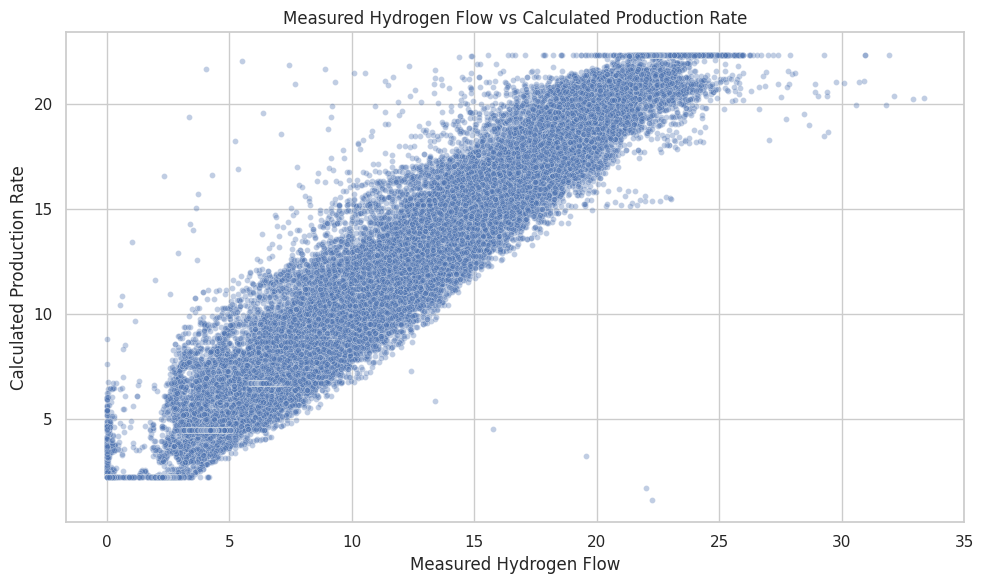

In [ ]:

# Cell 14 — Measured Flow vs Calculated Production Rate

flow_column = "IVAL_f_FM011_Flow"
rate_column = "H2E_f_Elec_CalcProdRate"

# Select required columns without modifying the original dataframe
production_check = df[
    [flow_column, rate_column]
].dropna()

# Descriptive statistics
print("MEASURED FLOW vs CALCULATED PRODUCTION RATE")
display(production_check.describe().T.round(4))

# Correlation analysis
print("\nPearson correlation:")
print(
    production_check[flow_column].corr(
        production_check[rate_column],
        method="pearson"
    )
)

print("\nSpearman correlation:")
print(
    production_check[flow_column].corr(
        production_check[rate_column],
        method="spearman"
    )
)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=production_check,
    x=flow_column,
    y=rate_column,
    alpha=0.35,
    s=18
)

plt.title("Measured Hydrogen Flow vs Calculated Production Rate")
plt.xlabel("Measured Hydrogen Flow")
plt.ylabel("Calculated Production Rate")

plt.tight_layout()
plt.show()


In [ ]:

# Cell 15 — Investigate Lowest Hydrogen Flow Observations

flow_column = "IVAL_f_FM011_Flow"

investigation_columns = [
    "Experiment",
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_NLR_CurrentCmd (A)",
    "Power Supply Average Voltage (Vdc)"
]

# Select the 20 observations with the lowest measured flow
lowest_flow_observations = (
    df.nsmallest(20, flow_column)
    [investigation_columns]
)

print("20 OBSERVATIONS WITH THE LOWEST MEASURED HYDROGEN FLOW")

display(
    lowest_flow_observations.round(4)
)


20 OBSERVATIONS WITH THE LOWEST MEASURED HYDROGEN FLOW


,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,Efficiency (kWh/kg),H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_NLR_CurrentCmd (A),Power Supply Average Voltage (Vdc)
19848,windIEA3.4-5ms-A_2-400.csv,0.005,2.441,22200.0000,111,336,327.271,323.133
23510,windIEA3.4-5ms-C_2-400.csv,0.005,4.479,40400.0000,202,599,617.845,333.467
19352,windIEA3.4-5ms-A_2-400.csv,0.006,4.588,35166.6667,211,623,614.771,334.267
19353,windIEA3.4-5ms-A_2-400.csv,0.006,4.633,34666.6667,208,615,621.051,334.167
19355,windIEA3.4-5ms-A_2-400.csv,0.006,4.631,35000.0000,210,621,641.318,334.300
19356,windIEA3.4-5ms-A_2-400.csv,0.006,4.631,35000.0000,210,621,641.318,334.300
19827,windIEA3.4-5ms-A_2-400.csv,0.006,2.238,16500.0000,99,300,300.000,321.467
19853,windIEA3.4-5ms-A_2-400.csv,0.006,2.612,19333.3333,116,351,350.160,323.600
19856,windIEA3.4-5ms-A_2-400.csv,0.006,2.891,20166.6667,121,366,387.499,324.333
20011,windIEA3.4-5ms-A_2-400.csv,0.006,2.615,19333.3333,116,351,350.579,323.433


In [ ]:

# Cell 16 — Low Hydrogen Flow Analysis by Experiment

flow_column = "IVAL_f_FM011_Flow"
efficiency_column = "Efficiency (kWh/kg)"

# Create a temporary analysis dataframe
# Original df remains unchanged
low_flow_analysis = df[
    ["Experiment", flow_column, efficiency_column]
].copy()

low_flow_analysis["Low_Flow"] = (
    low_flow_analysis[flow_column] <= 0.1
)

# Calculate experiment-wise statistics
experiment_flow_summary = (
    low_flow_analysis
    .groupby("Experiment")
    .agg(
        Total_Observations=(flow_column, "size"),
        Low_Flow_Count=("Low_Flow", "sum"),
        Median_Flow=(flow_column, "median")
    )
)

# Percentage of low-flow observations within each experiment
experiment_flow_summary["Low_Flow_Percentage"] = (
    experiment_flow_summary["Low_Flow_Count"]
    / experiment_flow_summary["Total_Observations"] * 100
)

# Efficiency statistics among low-flow observations
low_flow_efficiency = (
    low_flow_analysis[low_flow_analysis["Low_Flow"]]
    .groupby("Experiment")[efficiency_column]
    .agg(["count", "median", "max"])
)

experiment_flow_summary = experiment_flow_summary.join(
    low_flow_efficiency,
    rsuffix="_LowFlow"
)

experiment_flow_summary = experiment_flow_summary.rename(
    columns={
        "count": "LowFlow_Efficiency_Count",
        "median": "LowFlow_Median_Efficiency",
        "max": "LowFlow_Max_Efficiency"
    }
)

experiment_flow_summary = (
    experiment_flow_summary.sort_values(
        "Low_Flow_Count",
        ascending=False
    )
)

print("LOW HYDROGEN FLOW BY EXPERIMENT (FLOW <= 0.1)")

display(experiment_flow_summary.round(4))

print("\nTotal low-flow observations:",
      int(low_flow_analysis["Low_Flow"].sum()))


LOW HYDROGEN FLOW BY EXPERIMENT (FLOW <= 0.1)


,Total_Observations,Low_Flow_Count,Median_Flow,Low_Flow_Percentage,LowFlow_Efficiency_Count,LowFlow_Median_Efficiency,LowFlow_Max_Efficiency
Experiment,,,,,,,
characterization_200.csv,18000,117,12.3295,0.6500,117.0,9900.0000,12375.0000
windIEA3.4-5ms-A_2-200.csv,3652,112,10.1710,3.0668,112.0,6162.2807,16352.9412
windIEA3.4-5ms-A_2-400.csv,3652,66,10.2060,1.8072,66.0,16571.4286,39857.1429
windIEA3.4-5ms-C_2-200.csv,3652,34,9.8580,0.9310,34.0,6598.0392,10058.8235
windIEA3.4-7ms-A_1-400.csv,3591,24,13.1350,0.6683,24.0,11549.1071,17200.0000
windIEA3.4-7ms-A_1-200.csv,3591,22,13.1680,0.6126,22.0,9519.7368,12950.0000
windIEA3.4-5ms-C_2-400.csv,3652,14,9.8190,0.3834,14.0,18848.2143,40400.0000
windIEA3.4-9ms-A_1-200.csv,3591,4,17.9500,0.1114,4.0,14548.2456,20666.6667
windIEA3.4-7ms-C_1-200.csv,3591,0,12.7530,0.0000,NaN,NaN,NaN



Total low-flow observations: 393


In [ ]:

# Cell 17 — Consecutive Low-Flow Run Analysis

flow_column = "IVAL_f_FM011_Flow"
efficiency_column = "Efficiency (kWh/kg)"
threshold = 0.1

low_flow_runs = []

for experiment, group in df.groupby("Experiment", sort=False):

    # Preserve original row order
    group = group.sort_index()

    low_mask = group[flow_column] <= threshold

    # Identify consecutive sequences of low-flow observations
    run_ids = (
        low_mask != low_mask.shift(fill_value=False)
    ).cumsum()

    low_rows = group[low_mask]

    for run_id, run in low_rows.groupby(run_ids[low_mask]):

        low_flow_runs.append({
            "Experiment": experiment,
            "Start_Row": run.index.min(),
            "End_Row": run.index.max(),
            "Run_Length": len(run),
            "Minimum_Flow": run[flow_column].min(),
            "Maximum_Flow": run[flow_column].max(),
            "Maximum_Efficiency": run[efficiency_column].max()
        })

# Convert results into a separate analysis dataframe
runs_df = pd.DataFrame(low_flow_runs)

print("CONSECUTIVE LOW-FLOW RUN SUMMARY")

print("\nTotal low-flow runs:", len(runs_df))
print("Total low-flow observations:", runs_df["Run_Length"].sum())

print("\nRun-length statistics:")
display(runs_df["Run_Length"].describe().to_frame().round(3))

print("\nLongest 20 low-flow runs:")

display(
    runs_df.sort_values(
        "Run_Length",
        ascending=False
    ).head(20).round(4)
)


CONSECUTIVE LOW-FLOW RUN SUMMARY

Total low-flow runs: 53
Total low-flow observations: 393

Run-length statistics:


,Run_Length
count,53.000
mean,7.415
std,7.662
min,1.000
25%,3.000
50%,6.000
75%,9.000
max,40.000



Longest 20 low-flow runs:


,Experiment,Start_Row,End_Row,Run_Length,Minimum_Flow,Maximum_Flow,Maximum_Efficiency
8,windIEA3.4-5ms-A_2-200.csv,8926,8965,40,0.017,0.087,7666.6667
14,windIEA3.4-5ms-C_2-200.csv,12579,12612,34,0.016,0.073,10058.8235
0,windIEA3.4-7ms-A_1-200.csv,5349,5370,22,0.018,0.100,12950.0000
9,windIEA3.4-5ms-A_2-200.csv,9111,9130,20,0.017,0.074,8500.0000
15,windIEA3.4-7ms-A_1-400.csv,16241,16256,16,0.014,0.071,13933.3333
26,windIEA3.4-5ms-A_2-400.csv,19846,19861,16,0.005,0.079,22200.0000
36,characterization_200.csv,45235,45247,13,0.009,0.067,11000.0000
12,windIEA3.4-5ms-A_2-200.csv,10115,10126,12,0.016,0.089,11941.1765
41,characterization_200.csv,45797,45807,11,0.008,0.068,12375.0000
44,characterization_200.csv,45978,45988,11,0.008,0.065,12375.0000


In [ ]:

# Cell 18 — Examine Longest Low-Flow Run and Its Neighbours

# Identify the longest low-flow run
longest_run = runs_df.loc[
    runs_df["Run_Length"].idxmax()
]

experiment = longest_run["Experiment"]
start_row = int(longest_run["Start_Row"])
end_row = int(longest_run["End_Row"])

# Include five observations before and after the run
context_start = max(start_row - 5, 0)
context_end = end_row + 5

columns_to_inspect = [
    "Experiment",
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_NLR_CurrentCmd (A)",
    "Power Supply Average Voltage (Vdc)"
]

# Extract observations from the same experiment
context_data = df.loc[
    (df["Experiment"] == experiment)
    & (df.index >= context_start)
    & (df.index <= context_end),
    columns_to_inspect
].copy()

# Identify observations belonging to the low-flow run
context_data["Low_Flow"] = (
    context_data["IVAL_f_FM011_Flow"] <= 0.1
)

print("LONGEST LOW-FLOW RUN")
print("Experiment:", experiment)
print("Start row:", start_row)
print("End row:", end_row)
print("Run length:", int(longest_run["Run_Length"]))

print("\nSURROUNDING OBSERVATIONS")
display(context_data.round(4))


LONGEST LOW-FLOW RUN
Experiment: windIEA3.4-5ms-A_2-200.csv
Start row: 8926
End row: 8965
Run length: 40

SURROUNDING OBSERVATIONS


,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,Efficiency (kWh/kg),H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_NLR_CurrentCmd (A),Power Supply Average Voltage (Vdc),Low_Flow
8921,windIEA3.4-5ms-A_2-200.csv,0.133,2.238,736.8421,98,300,300.000,320.700,False
8922,windIEA3.4-5ms-A_2-200.csv,0.131,2.238,755.7252,99,301,300.000,321.067,False
8923,windIEA3.4-5ms-A_2-200.csv,0.019,2.238,5157.8947,98,301,300.000,320.533,True
8924,windIEA3.4-5ms-A_2-200.csv,0.159,2.238,622.6415,99,299,300.000,320.667,False
8925,windIEA3.4-5ms-A_2-200.csv,0.158,2.238,620.2532,98,299,300.000,321.167,False
8926,windIEA3.4-5ms-A_2-200.csv,0.019,2.238,5157.8947,98,299,300.000,321.033,True
8927,windIEA3.4-5ms-A_2-200.csv,0.019,2.238,5210.5263,99,301,300.000,321.167,True
8928,windIEA3.4-5ms-A_2-200.csv,0.018,2.238,5500.0000,99,300,300.000,320.633,True
8929,windIEA3.4-5ms-A_2-200.csv,0.018,2.238,5500.0000,99,300,300.000,321.100,True
8930,windIEA3.4-5ms-A_2-200.csv,0.019,2.238,5210.5263,99,299,300.000,321.333,True


In [ ]:

# Cell 19 — Identify Timestamp Columns

timestamp_candidates = [
    col for col in df.columns
    if any(
        term in col.lower()
        for term in ["time", "date", "timestamp"]
    )
]

print("POTENTIAL TIMESTAMP COLUMNS:")
print(timestamp_candidates)

if timestamp_candidates:

    print("\nTIMESTAMP VALUES AROUND THE EVENT:")

    display(
        df.loc[
            8921:8970,
            ["Experiment"] + timestamp_candidates
        ]
    )

else:
    print(
        "\nNo explicitly named timestamp column found. "
        "We need to inspect the dataset structure further."
    )


POTENTIAL TIMESTAMP COLUMNS:
[]

No explicitly named timestamp column found. We need to inspect the dataset structure further.


In [ ]:

# Cell 20 — Complete Dataset Structure Inspection

print("DATASET SHAPE:")
print(df.shape)

print("\nALL COLUMN NAMES AND DATA TYPES:")

column_info = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Values": df.isna().sum().values,
    "Unique_Values": df.nunique().values
})

display(column_info)

print("\nFIRST 5 ROWS:")
display(df.head())

print("\nLAST 5 ROWS:")
display(df.tail())


DATASET SHAPE:
(61285, 32)

ALL COLUMN NAMES AND DATA TYPES:


,Column,Data_Type,Missing_Values,Unique_Values
0,Unnamed: 0,object,0,1034
1,Wind Turbine Power (kW),float64,18000,17503
2,H2E_f_NLR_CurrentCmd (A),float64,0,34439
3,IVAL_f_FM011_Flow,float64,1,19724
4,Efficiency (kWh/kg),float64,1,53242
5,Power Supply Average Voltage (Vdc),float64,0,2090
6,H2E_f_NLR_CurrentCmd,float64,0,28532
7,H2E_n_PSU_A_Power,int64,0,1165
8,H2E_f_PSU_A_Current,int64,0,2678
9,H2E_f_Elec_CalcProdRate,float64,0,15447



FIRST 5 ROWS:


,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Experiment,Unnamed: 31
0,6/4/2025 10:32,350.14,995.024,7.305,47.638604,346.100,33.167,348,993,7.423,0.123,-52.222,-45.451,2.276,60.823,29.549,2.836,28.967,25.669,4.331,6.377,13.699,58.333,59.028,13.447,16.742,17.4,7.2,10.1,15.2,windIEA3.4-7ms-C_1-200.csv,NaN
1,6/4/2025 10:32,585.70,1604.360,7.276,47.965915,346.433,53.479,349,997,8.024,0.119,-52.292,-45.451,2.276,60.829,29.549,2.827,28.966,25.668,4.332,6.381,13.889,58.333,59.028,13.442,16.747,17.3,7.2,10.0,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
2,6/4/2025 10:32,778.30,2067.155,7.251,58.198869,352.200,68.905,422,1181,9.377,0.119,-52.292,-45.451,2.276,60.832,29.549,2.846,28.967,25.668,4.334,6.383,13.889,58.333,59.028,13.442,16.753,17.4,7.3,10.1,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
3,6/4/2025 10:32,903.86,2523.305,7.166,68.936645,357.700,84.110,494,1359,10.786,0.119,-52.222,-45.451,2.275,60.835,29.555,2.855,28.981,25.668,4.336,6.384,13.889,58.333,59.028,13.437,16.758,17.3,7.2,10.1,15.3,windIEA3.4-7ms-C_1-200.csv,NaN
4,6/4/2025 10:32,982.63,2608.763,7.405,77.245105,363.333,86.959,572,1550,12.051,0.119,-52.292,-45.451,2.273,60.830,29.547,2.853,29.010,25.668,4.336,6.395,13.699,58.102,59.028,13.437,16.758,17.3,7.2,10.1,15.4,windIEA3.4-7ms-C_1-200.csv,NaN



LAST 5 ROWS:


,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Experiment,Unnamed: 31
61280,8/6/2025 13:52,1122.9,2627.359,16.669,62.991181,397.300,87.579,1050,2593,19.600,0.123,-58.958,-62.257,0.264,60.340,28.566,3.143,29.099,26.690,4.292,6.831,3.571,55.787,58.102,9.730,37.936,NaN,7.1,8.7,16.0,windIEA3.4-9ms-A_1-400.csv,20.1
61281,8/6/2025 13:52,1122.9,2675.545,16.723,63.804341,398.133,89.185,1067,2626,19.960,0.123,-58.958,-62.257,0.263,60.398,28.526,3.151,29.140,26.692,4.292,6.833,3.559,55.787,58.102,9.730,37.941,NaN,7.1,8.7,16.0,windIEA3.4-9ms-A_1-400.csv,20.0
61282,8/6/2025 13:52,1122.9,2704.732,17.100,63.859649,398.300,90.158,1092,2677,20.142,0.130,-58.958,-62.257,0.263,60.409,28.321,3.155,29.172,26.694,4.292,6.841,3.571,55.787,58.102,9.735,37.946,NaN,7.1,8.7,16.0,windIEA3.4-9ms-A_1-400.csv,20.1
61283,8/6/2025 13:52,1122.9,2701.842,18.098,61.001216,399.367,90.061,1104,2701,20.156,0.123,-58.958,-62.257,0.262,60.365,28.246,3.161,29.229,26.702,4.293,6.840,3.546,55.787,58.102,9.740,37.952,NaN,7.1,8.7,15.9,windIEA3.4-9ms-A_1-400.csv,20.0
61284,8/6/2025 13:52,1122.9,2707.980,20.687,53.656886,400.633,90.266,1110,2707,20.202,0.123,-58.958,-62.222,0.265,60.312,27.898,3.168,29.024,26.748,4.295,6.847,3.559,55.787,57.870,9.714,38.084,NaN,7.1,8.7,16.0,windIEA3.4-9ms-A_1-400.csv,20.1


In [ ]:
# Cell 21 — Investigate Unnamed Columns

print("UNNAMED: 0 — SAMPLE VALUES")
display(df["Unnamed: 0"].head(15))

print("\nUNNAMED: 0 — UNIQUE VALUE COUNT")
print(df["Unnamed: 0"].nunique())

print("\nUNNAMED: 0 — SAMPLE VALUES FROM DIFFERENT EXPERIMENTS")
display(
    df.groupby("Experiment")["Unnamed: 0"]
      .agg(["first", "last", "count"])
)

print("\nUNNAMED: 31 — NON-MISSING VALUE STATISTICS")
display(df["Unnamed: 31"].describe())

print("\nUNNAMED: 31 — SAMPLE NON-MISSING VALUES")
display(df.loc[df["Unnamed: 31"].notna(),
               ["Unnamed: 31", "Experiment"]].head(20))

print("\nUNNAMED: 31 — NON-MISSING VALUES BY EXPERIMENT")
display(
    df.groupby("Experiment")["Unnamed: 31"]
      .agg(["count", "min", "median", "max"])
)

UNNAMED: 0 — SAMPLE VALUES


,Unnamed: 0
0,6/4/2025 10:32
1,6/4/2025 10:32
2,6/4/2025 10:32
3,6/4/2025 10:32
4,6/4/2025 10:32
5,6/4/2025 10:32
6,6/4/2025 10:32
7,6/4/2025 10:33
8,6/4/2025 10:33
9,6/4/2025 10:33



UNNAMED: 0 — UNIQUE VALUE COUNT
1034

UNNAMED: 0 — SAMPLE VALUES FROM DIFFERENT EXPERIMENTS


,first,last,count
Experiment,,,
characterization_200.csv,7/11/2025 10:44,7/11/2025 15:44,18000
windIEA3.4-5ms-A_2-200.csv,6/4/2025 12:58,6/4/2025 13:59,3652
windIEA3.4-5ms-A_2-400.csv,6/10/2025 12:45,6/10/2025 13:46,3652
windIEA3.4-5ms-C_2-200.csv,6/4/2025 14:07,6/4/2025 15:08,3652
windIEA3.4-5ms-C_2-400.csv,6/10/2025 13:48,6/10/2025 14:49,3652
windIEA3.4-7ms-A_1-200.csv,6/4/2025 11:48,6/4/2025 12:48,3591
windIEA3.4-7ms-A_1-400.csv,6/4/2025 15:24,6/4/2025 16:23,3591
windIEA3.4-7ms-C_1-200.csv,6/4/2025 10:32,6/4/2025 11:32,3591
windIEA3.4-7ms-C_1-400.csv,6/10/2025 14:51,6/10/2025 15:51,3591



UNNAMED: 31 — NON-MISSING VALUE STATISTICS


,Unnamed: 31
count,14313.000000
mean,30.055970
std,42.640922
min,9.900000
25%,10.600000
50%,11.600000
75%,20.700000
max,160.300000



UNNAMED: 31 — SAMPLE NON-MISSING VALUES


,Unnamed: 31,Experiment
46972,13.2,windIEA3.4-9ms-A_1-200.csv
46973,13.3,windIEA3.4-9ms-A_1-200.csv
46974,13.2,windIEA3.4-9ms-A_1-200.csv
46975,13.2,windIEA3.4-9ms-A_1-200.csv
46976,13.2,windIEA3.4-9ms-A_1-200.csv
46977,13.1,windIEA3.4-9ms-A_1-200.csv
46978,13.3,windIEA3.4-9ms-A_1-200.csv
46979,13.2,windIEA3.4-9ms-A_1-200.csv
46980,13.3,windIEA3.4-9ms-A_1-200.csv
46981,13.2,windIEA3.4-9ms-A_1-200.csv



UNNAMED: 31 — NON-MISSING VALUES BY EXPERIMENT


,count,min,median,max
Experiment,,,,
characterization_200.csv,0,NaN,NaN,NaN
windIEA3.4-5ms-A_2-200.csv,0,NaN,NaN,NaN
windIEA3.4-5ms-A_2-400.csv,0,NaN,NaN,NaN
windIEA3.4-5ms-C_2-200.csv,0,NaN,NaN,NaN
windIEA3.4-5ms-C_2-400.csv,0,NaN,NaN,NaN
windIEA3.4-7ms-A_1-200.csv,0,NaN,NaN,NaN
windIEA3.4-7ms-A_1-400.csv,0,NaN,NaN,NaN
windIEA3.4-7ms-C_1-200.csv,0,NaN,NaN,NaN
windIEA3.4-7ms-C_1-400.csv,0,NaN,NaN,NaN


In [ ]:
# Cell 22 — Timestamp Validation
# Keep the original dataframe unchanged.

timestamp = pd.to_datetime(
    df["Unnamed: 0"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("TIMESTAMP VALIDATION")
print("--------------------")

print("Total rows:", len(timestamp))
print("Successfully parsed:", timestamp.notna().sum())
print("Failed parsing:", timestamp.isna().sum())

print("\nTIMESTAMP RANGE")
print("Earliest:", timestamp.min())
print("Latest:", timestamp.max())

print("\nDUPLICATE TIMESTAMP OBSERVATIONS")
print("Rows sharing timestamps:",
      timestamp.duplicated(keep=False).sum())
print("Unique timestamps:", timestamp.nunique())

print("\nCHRONOLOGICAL ORDER WITHIN EACH EXPERIMENT")

timestamp_check = pd.DataFrame({
    "Experiment": df["Experiment"],
    "Timestamp": timestamp
})

ordering_check = timestamp_check.groupby("Experiment")["Timestamp"].agg(
    First="min",
    Last="max",
    Unique_Timestamps="nunique",
    Monotonic_Increasing=lambda x: x.is_monotonic_increasing
)

display(ordering_check)

print("\nFIRST 10 PARSED TIMESTAMPS")
display(timestamp.head(10))

TIMESTAMP VALIDATION
--------------------
Total rows: 61285
Successfully parsed: 61285
Failed parsing: 0

TIMESTAMP RANGE
Earliest: 2025-06-04 10:32:00
Latest: 2025-08-06 13:52:00

DUPLICATE TIMESTAMP OBSERVATIONS
Rows sharing timestamps: 61285
Unique timestamps: 1034

CHRONOLOGICAL ORDER WITHIN EACH EXPERIMENT


,First,Last,Unique_Timestamps,Monotonic_Increasing
Experiment,,,,
characterization_200.csv,2025-07-11 10:44:00,2025-07-11 15:44:00,301,True
windIEA3.4-5ms-A_2-200.csv,2025-06-04 12:58:00,2025-06-04 13:59:00,62,True
windIEA3.4-5ms-A_2-400.csv,2025-06-10 12:45:00,2025-06-10 13:46:00,62,True
windIEA3.4-5ms-C_2-200.csv,2025-06-04 14:07:00,2025-06-04 15:08:00,62,True
windIEA3.4-5ms-C_2-400.csv,2025-06-10 13:48:00,2025-06-10 14:49:00,62,True
windIEA3.4-7ms-A_1-200.csv,2025-06-04 11:48:00,2025-06-04 12:48:00,61,True
windIEA3.4-7ms-A_1-400.csv,2025-06-04 15:24:00,2025-06-04 16:23:00,60,True
windIEA3.4-7ms-C_1-200.csv,2025-06-04 10:32:00,2025-06-04 11:32:00,61,True
windIEA3.4-7ms-C_1-400.csv,2025-06-10 14:51:00,2025-06-10 15:51:00,61,True



FIRST 10 PARSED TIMESTAMPS


,Unnamed: 0
0,2025-06-04 10:32:00
1,2025-06-04 10:32:00
2,2025-06-04 10:32:00
3,2025-06-04 10:32:00
4,2025-06-04 10:32:00
5,2025-06-04 10:32:00
6,2025-06-04 10:32:00
7,2025-06-04 10:33:00
8,2025-06-04 10:33:00
9,2025-06-04 10:33:00


In [ ]:
# Cell 23 — Sampling Frequency Analysis
# Uses the separately parsed timestamp series.
# Original dataframe remains unchanged.

timestamp_data = pd.DataFrame({
    "Experiment": df["Experiment"],
    "Timestamp": timestamp
})

# Count observations recorded in each minute
minute_counts = (
    timestamp_data
    .groupby(["Experiment", "Timestamp"])
    .size()
    .reset_index(name="Observations")
)

print("OBSERVATIONS PER TIMESTAMP")
display(minute_counts["Observations"].describe())

print("\nOBSERVATIONS PER MINUTE BY EXPERIMENT")

sampling_summary = (
    minute_counts
    .groupby("Experiment")["Observations"]
    .agg(["count", "mean", "median", "min", "max", "std"])
)

display(sampling_summary)

# Examine time gaps between consecutive unique timestamps
print("\nTIME GAP BETWEEN CONSECUTIVE TIMESTAMPS")

minute_counts = minute_counts.sort_values(
    ["Experiment", "Timestamp"]
).copy()

minute_counts["Time_Gap_Minutes"] = (
    minute_counts
    .groupby("Experiment")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

gap_summary = (
    minute_counts
    .groupby("Experiment")["Time_Gap_Minutes"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(gap_summary)

print("\nOVERALL TIME GAP DISTRIBUTION")
display(minute_counts["Time_Gap_Minutes"].describe())

OBSERVATIONS PER TIMESTAMP


,Observations
count,1034.000000
mean,59.269826
std,5.226683
min,6.000000
25%,60.000000
50%,60.000000
75%,60.000000
max,60.000000



OBSERVATIONS PER MINUTE BY EXPERIMENT


,count,mean,median,min,max,std
Experiment,,,,,,
characterization_200.csv,301,59.800664,60.0,28,60,2.446794
windIEA3.4-5ms-A_2-200.csv,62,58.903226,60.0,25,60,6.059026
windIEA3.4-5ms-A_2-400.csv,62,58.903226,60.0,24,60,6.067137
windIEA3.4-5ms-C_2-200.csv,62,58.903226,60.0,12,60,6.565458
windIEA3.4-5ms-C_2-400.csv,62,58.903226,60.0,7,60,6.965276
windIEA3.4-7ms-A_1-200.csv,61,58.868852,60.0,20,60,6.275549
windIEA3.4-7ms-A_1-400.csv,60,59.850000,60.0,52,60,1.038660
windIEA3.4-7ms-C_1-200.csv,61,58.868852,60.0,7,60,7.055672
windIEA3.4-7ms-C_1-400.csv,61,58.868852,60.0,16,60,6.432924



TIME GAP BETWEEN CONSECUTIVE TIMESTAMPS


,count,mean,median,min,max
Experiment,,,,,
characterization_200.csv,300,1.0,1.0,1.0,1.0
windIEA3.4-5ms-A_2-200.csv,61,1.0,1.0,1.0,1.0
windIEA3.4-5ms-A_2-400.csv,61,1.0,1.0,1.0,1.0
windIEA3.4-5ms-C_2-200.csv,61,1.0,1.0,1.0,1.0
windIEA3.4-5ms-C_2-400.csv,61,1.0,1.0,1.0,1.0
windIEA3.4-7ms-A_1-200.csv,60,1.0,1.0,1.0,1.0
windIEA3.4-7ms-A_1-400.csv,59,1.0,1.0,1.0,1.0
windIEA3.4-7ms-C_1-200.csv,60,1.0,1.0,1.0,1.0
windIEA3.4-7ms-C_1-400.csv,60,1.0,1.0,1.0,1.0



OVERALL TIME GAP DISTRIBUTION


,Time_Gap_Minutes
count,1021.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


In [ ]:
# Cell 24 — Timestamp-Based Low-Flow Event Analysis

analysis_df = df.copy()

analysis_df["Timestamp"] = timestamp

# Select the previously identified experiment
experiment_name = "windIEA3.4-5ms-A_2-200.csv"

event_data = analysis_df[
    analysis_df["Experiment"] == experiment_name
].copy()

event_data = event_data.sort_values(
    ["Timestamp"]
)

# Identify low-flow observations
event_data["Low_Flow"] = (
    event_data["IVAL_f_FM011_Flow"] <= 0.1
)

# Identify consecutive low-flow runs
event_data["Run_ID"] = (
    event_data["Low_Flow"] !=
    event_data["Low_Flow"].shift()
).cumsum()

low_flow_events = (
    event_data[event_data["Low_Flow"]]
    .groupby("Run_ID")
    .agg(
        Start_Time=("Timestamp", "min"),
        End_Time=("Timestamp", "max"),
        Row_Count=("Timestamp", "size"),
        Min_Flow=("IVAL_f_FM011_Flow", "min"),
        Max_Flow=("IVAL_f_FM011_Flow", "max"),
        Mean_Efficiency=("Efficiency (kWh/kg)", "mean"),
        Mean_Power=("H2E_n_PSU_A_Power", "mean"),
        Mean_Voltage=("Power Supply Average Voltage (Vdc)", "mean")
    )
)

low_flow_events["Duration_Minutes"] = (
    low_flow_events["End_Time"] -
    low_flow_events["Start_Time"]
).dt.total_seconds() / 60

low_flow_events = low_flow_events.sort_values(
    "Row_Count",
    ascending=False
)

print("LOW-FLOW EVENTS —", experiment_name)
display(low_flow_events.head(10))

print("\nLONGEST EVENT DETAILS")

longest_event_id = low_flow_events.index[0]

longest_event = event_data[
    event_data["Run_ID"] == longest_event_id
]

print("Start:", longest_event["Timestamp"].min())
print("End:", longest_event["Timestamp"].max())
print("Rows:", len(longest_event))

print(
    "Elapsed timestamp duration:",
    (
        longest_event["Timestamp"].max() -
        longest_event["Timestamp"].min()
    ).total_seconds() / 60,
    "minutes"
)

LOW-FLOW EVENTS — windIEA3.4-5ms-A_2-200.csv


,Start_Time,End_Time,Row_Count,Min_Flow,Max_Flow,Mean_Efficiency,Mean_Power,Mean_Voltage,Duration_Minutes
Run_ID,,,,,,,,,
28,2025-06-04 13:27:00,2025-06-04 13:27:00,20,0.017,0.087,5000.452653,100.30,321.148350,0.0
32,2025-06-04 13:28:00,2025-06-04 13:28:00,16,0.017,0.020,6316.283970,116.75,323.143875,0.0
40,2025-06-04 13:30:00,2025-06-04 13:30:00,14,0.017,0.074,5531.883575,113.00,323.166571,0.0
52,2025-06-04 13:47:00,2025-06-04 13:47:00,10,0.017,0.089,9789.041978,219.30,333.563400,0.0
4,2025-06-04 13:16:00,2025-06-04 13:16:00,5,0.018,0.021,9036.758563,171.40,329.500000,0.0
24,2025-06-04 13:27:00,2025-06-04 13:27:00,5,0.018,0.019,5373.099415,98.80,320.980000,0.0
46,2025-06-04 13:43:00,2025-06-04 13:43:00,5,0.017,0.018,9926.797387,176.60,331.059800,0.0
50,2025-06-04 13:47:00,2025-06-04 13:47:00,5,0.017,0.079,10821.358311,227.80,334.613200,0.0
54,2025-06-04 13:47:00,2025-06-04 13:47:00,4,0.016,0.018,11513.276142,194.25,331.116500,0.0



LONGEST EVENT DETAILS
Start: 2025-06-04 13:27:00
End: 2025-06-04 13:27:00
Rows: 20
Elapsed timestamp duration: 0.0 minutes


In [ ]:
# Cell 25 — Missing Values by Experiment

missing_by_experiment = (
    df.groupby("Experiment")
      .apply(
          lambda group: group.isna().sum(),
          include_groups=False
      )
)

print("MISSING VALUES BY EXPERIMENT")
display(missing_by_experiment)

print("\nMISSING VALUE PERCENTAGE BY EXPERIMENT")

missing_percentage = (
    df.groupby("Experiment")
      .apply(
          lambda group: group.isna().mean() * 100,
          include_groups=False
      )
)

display(missing_percentage.round(2))

print("\nTOTAL MISSING VALUES PER EXPERIMENT")

experiment_missing_summary = pd.DataFrame({
    "Total_Rows": df.groupby("Experiment").size(),
    "Missing_Cells": df.groupby("Experiment").apply(
        lambda group: group.isna().sum().sum()
    )
})

experiment_missing_summary["Missing_Percentage"] = (
    experiment_missing_summary["Missing_Cells"] /
    (experiment_missing_summary["Total_Rows"] * len(df.columns))
) * 100

display(experiment_missing_summary.round(2))

MISSING VALUES BY EXPERIMENT


,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Unnamed: 31
Experiment,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
characterization_200.csv,0,18000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,18000
windIEA3.4-5ms-A_2-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652
windIEA3.4-5ms-A_2-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652
windIEA3.4-5ms-C_2-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652
windIEA3.4-5ms-C_2-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3652
windIEA3.4-7ms-A_1-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591
windIEA3.4-7ms-A_1-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591
windIEA3.4-7ms-C_1-200.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591
windIEA3.4-7ms-C_1-400.csv,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3591



MISSING VALUE PERCENTAGE BY EXPERIMENT


,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Unnamed: 31
Experiment,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
characterization_200.csv,0.0,100.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-5ms-A_2-200.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-5ms-A_2-400.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-5ms-C_2-200.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-5ms-C_2-400.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-7ms-A_1-200.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-7ms-A_1-400.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-7ms-C_1-200.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
windIEA3.4-7ms-C_1-400.csv,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0



TOTAL MISSING VALUES PER EXPERIMENT


/tmp/ipykernel_501/4127209289.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Missing_Cells": df.groupby("Experiment").apply(


,Total_Rows,Missing_Cells,Missing_Percentage
Experiment,,,
characterization_200.csv,18000,36000,6.25
windIEA3.4-5ms-A_2-200.csv,3652,3652,3.12
windIEA3.4-5ms-A_2-400.csv,3652,3652,3.12
windIEA3.4-5ms-C_2-200.csv,3652,3652,3.12
windIEA3.4-5ms-C_2-400.csv,3652,3652,3.12
windIEA3.4-7ms-A_1-200.csv,3591,3591,3.12
windIEA3.4-7ms-A_1-400.csv,3591,3591,3.12
windIEA3.4-7ms-C_1-200.csv,3591,3591,3.12
windIEA3.4-7ms-C_1-400.csv,3591,3591,3.12


In [ ]:
# Cell 26 — Constant and Near-Constant Feature Analysis

# Exclude identifiers and metadata
excluded_columns = [
    "Unnamed: 0",
    "Unnamed: 31",
    "Experiment"
]

numeric_columns = df.select_dtypes(
    include=["number"]
).columns.difference(excluded_columns)

feature_variability = pd.DataFrame({
    "Unique_Values": df[numeric_columns].nunique(),
    "Mean": df[numeric_columns].mean(),
    "Std_Dev": df[numeric_columns].std(),
    "Min": df[numeric_columns].min(),
    "Max": df[numeric_columns].max()
})

feature_variability["Coefficient_of_Variation"] = (
    feature_variability["Std_Dev"] /
    feature_variability["Mean"].abs().replace(0, np.nan)
)

feature_variability = feature_variability.sort_values(
    "Unique_Values"
)

print("NUMERIC FEATURE VARIABILITY")
display(feature_variability)

print("\nCONSTANT FEATURES")
display(
    feature_variability[
        feature_variability["Unique_Values"] <= 1
    ]
)

print("\nLOW-VARIABILITY FEATURES — FEWER THAN 30 UNIQUE VALUES")
display(
    feature_variability[
        feature_variability["Unique_Values"] < 30
    ]
)

NUMERIC FEATURE VARIABILITY


,Unique_Values,Mean,Std_Dev,Min,Max,Coefficient_of_Variation
H2E_f_TE218_Temp,23,57.231610,0.814323,54.861000,59.954,0.014229
H2E_f_TE219_Temp,25,58.024474,0.657989,55.787000,61.343,0.011340
H2E_f_TT645_Temp,116,9.823510,3.769559,6.400000,17.900,0.383728
H2E_f_TT647_Temp,123,13.053706,4.672104,5.800000,19.900,0.357914
H2E_f_TT646_Temp,135,12.010826,3.987667,8.300000,21.700,0.332006
H2E_f_DPS340_DPdegC,137,-54.209758,3.556029,-59.375000,-48.333,0.065598
H2E_f_TT641_Temp,149,13.633422,7.108500,3.700000,51.500,0.521402
H2E_f_RS507_Resistivity,181,11.212882,4.366013,1.397000,18.182,0.389375
H2E_f_CG220_LFLPer,209,0.257684,0.673136,0.119000,4.348,2.612250
H2E_f_PT604_Pressure,464,4.414713,0.080434,4.115000,4.604,0.018219



CONSTANT FEATURES


,Unique_Values,Mean,Std_Dev,Min,Max,Coefficient_of_Variation



LOW-VARIABILITY FEATURES — FEWER THAN 30 UNIQUE VALUES


,Unique_Values,Mean,Std_Dev,Min,Max,Coefficient_of_Variation
H2E_f_TE218_Temp,23,57.231610,0.814323,54.861,59.954,0.014229
H2E_f_TE219_Temp,25,58.024474,0.657989,55.787,61.343,0.011340


In [ ]:
# Cell 27 — Pearson and Spearman Correlation Analysis

correlation_columns = df.select_dtypes(
    include=["number"]
).columns

correlation_columns = [
    col for col in correlation_columns
    if col != "Unnamed: 31"
]

correlation_data = df[correlation_columns]

# Pearson: linear relationships
pearson_corr = correlation_data.corr(
    method="pearson"
)

# Spearman: monotonic relationships
spearman_corr = correlation_data.corr(
    method="spearman"
)

print("PEARSON CORRELATION MATRIX")
display(pearson_corr.round(2))

print("\nSPEARMAN CORRELATION MATRIX")
display(spearman_corr.round(2))

# Correlation with important process variables
important_targets = [
    "H2E_f_Elec_CalcProdRate",
    "IVAL_f_FM011_Flow",
    "Efficiency (kWh/kg)",
    "Power Supply Average Voltage (Vdc)"
]

for target in important_targets:
    print(f"\nCORRELATION WITH {target}")

    target_corr = (
        pearson_corr[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
    )

    display(target_corr.to_frame("Pearson_Correlation"))

PEARSON CORRELATION MATRIX


,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp
Wind Turbine Power (kW),1.00,0.97,0.93,-0.11,0.97,0.97,0.97,0.97,0.97,-0.16,-0.28,-0.42,-0.36,-0.01,0.34,0.79,0.43,0.03,-0.22,0.03,-0.44,-0.45,0.03,-0.32,0.23,-0.06,0.12,0.19,-0.06
H2E_f_NLR_CurrentCmd (A),0.97,1.00,0.96,-0.11,1.00,1.00,1.00,1.00,1.00,-0.34,-0.17,-0.35,-0.31,0.20,0.24,0.80,0.36,-0.32,-0.51,0.34,-0.28,-0.64,0.02,-0.21,0.18,-0.02,0.16,0.18,-0.02
IVAL_f_FM011_Flow,0.93,0.96,1.00,-0.14,0.97,0.96,0.97,0.97,0.97,-0.33,-0.15,-0.32,-0.29,0.19,0.32,0.77,0.42,-0.30,-0.44,0.31,-0.26,-0.60,-0.03,-0.20,0.17,-0.02,0.15,0.17,-0.02
Efficiency (kWh/kg),-0.11,-0.11,-0.14,1.00,-0.12,-0.11,-0.10,-0.11,-0.11,0.07,0.01,0.04,0.04,-0.03,-0.09,-0.08,-0.08,0.01,0.02,-0.06,0.02,0.07,0.04,0.02,-0.01,0.02,0.00,-0.00,-0.01
Power Supply Average Voltage (Vdc),0.97,1.00,0.97,-0.12,1.00,1.00,1.00,1.00,1.00,-0.36,-0.18,-0.36,-0.32,0.21,0.24,0.80,0.35,-0.32,-0.53,0.37,-0.28,-0.65,0.03,-0.21,0.18,-0.00,0.17,0.19,-0.03
H2E_f_NLR_CurrentCmd,0.97,1.00,0.96,-0.11,1.00,1.00,1.00,1.00,1.00,-0.34,-0.17,-0.35,-0.31,0.20,0.24,0.80,0.36,-0.32,-0.51,0.34,-0.28,-0.64,0.02,-0.21,0.18,-0.02,0.16,0.18,-0.02
H2E_n_PSU_A_Power,0.97,1.00,0.97,-0.10,1.00,1.00,1.00,1.00,1.00,-0.32,-0.16,-0.35,-0.31,0.19,0.25,0.80,0.36,-0.31,-0.51,0.33,-0.28,-0.64,0.02,-0.22,0.19,-0.03,0.16,0.18,-0.01
H2E_f_PSU_A_Current,0.97,1.00,0.97,-0.11,1.00,1.00,1.00,1.00,1.00,-0.34,-0.17,-0.35,-0.32,0.20,0.25,0.80,0.36,-0.32,-0.51,0.34,-0.28,-0.64,0.02,-0.21,0.18,-0.02,0.16,0.18,-0.02
H2E_f_Elec_CalcProdRate,0.97,1.00,0.97,-0.11,1.00,1.00,1.00,1.00,1.00,-0.34,-0.17,-0.35,-0.31,0.20,0.25,0.80,0.36,-0.32,-0.51,0.34,-0.28,-0.64,0.02,-0.21,0.18,-0.02,0.16,0.18,-0.02
H2E_f_CG220_LFLPer,-0.16,-0.34,-0.33,0.07,-0.36,-0.34,-0.32,-0.34,-0.34,1.00,0.23,0.17,0.18,-0.22,-0.05,-0.26,0.05,0.19,0.29,-0.61,0.04,0.23,-0.01,0.05,0.03,-0.18,-0.10,-0.09,0.07



SPEARMAN CORRELATION MATRIX


,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp
Wind Turbine Power (kW),1.00,0.97,0.94,0.23,0.97,0.97,0.97,0.97,0.97,-0.06,-0.31,-0.39,-0.41,-0.01,0.33,0.82,0.38,0.06,-0.21,0.08,-0.38,-0.45,0.03,-0.34,0.22,-0.07,0.15,0.25,0.05
H2E_f_NLR_CurrentCmd (A),0.97,1.00,0.96,0.44,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.32,0.18,0.23,0.84,0.32,-0.28,-0.49,0.33,-0.13,-0.63,0.02,-0.25,0.21,0.07,0.36,0.28,0.10
IVAL_f_FM011_Flow,0.94,0.96,1.00,0.24,0.97,0.96,0.97,0.97,0.97,-0.18,-0.17,-0.29,-0.30,0.18,0.30,0.82,0.36,-0.27,-0.43,0.29,-0.12,-0.59,-0.02,-0.24,0.20,0.07,0.34,0.26,0.09
Efficiency (kWh/kg),0.23,0.44,0.24,1.00,0.43,0.44,0.43,0.43,0.43,-0.09,-0.14,-0.17,-0.16,0.10,-0.16,0.38,-0.11,-0.17,-0.46,0.27,-0.06,-0.36,0.20,-0.10,0.12,0.06,0.25,0.15,0.06
Power Supply Average Voltage (Vdc),0.97,1.00,0.97,0.43,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.33,0.18,0.23,0.85,0.31,-0.28,-0.51,0.35,-0.13,-0.65,0.03,-0.25,0.22,0.08,0.37,0.28,0.09
H2E_f_NLR_CurrentCmd,0.97,1.00,0.96,0.44,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.32,0.18,0.23,0.84,0.32,-0.28,-0.49,0.33,-0.13,-0.63,0.02,-0.25,0.21,0.07,0.36,0.28,0.10
H2E_n_PSU_A_Power,0.97,1.00,0.97,0.43,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.32,0.18,0.24,0.85,0.32,-0.28,-0.50,0.33,-0.13,-0.63,0.02,-0.25,0.22,0.07,0.36,0.28,0.10
H2E_f_PSU_A_Current,0.97,1.00,0.97,0.43,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.32,0.18,0.24,0.84,0.32,-0.28,-0.49,0.33,-0.13,-0.63,0.02,-0.25,0.22,0.07,0.36,0.28,0.10
H2E_f_Elec_CalcProdRate,0.97,1.00,0.97,0.43,1.00,1.00,1.00,1.00,1.00,-0.18,-0.19,-0.31,-0.32,0.18,0.23,0.84,0.32,-0.28,-0.49,0.33,-0.13,-0.63,0.02,-0.25,0.22,0.07,0.36,0.28,0.10
H2E_f_CG220_LFLPer,-0.06,-0.18,-0.18,-0.09,-0.18,-0.18,-0.18,-0.18,-0.18,1.00,0.15,-0.13,-0.13,-0.17,-0.05,-0.22,0.00,0.01,0.28,-0.04,-0.04,0.11,-0.02,-0.10,0.27,-0.07,-0.00,0.06,0.06



CORRELATION WITH H2E_f_Elec_CalcProdRate


,Pearson_Correlation
H2E_f_PSU_A_Current,0.999328
Power Supply Average Voltage (Vdc),0.998184
H2E_f_NLR_CurrentCmd (A),0.997633
H2E_f_NLR_CurrentCmd,0.997633
H2E_n_PSU_A_Power,0.997620
Wind Turbine Power (kW),0.968691
IVAL_f_FM011_Flow,0.967749
H2E_f_PT264_Pressure,0.798748
H2E_f_TE218_Temp,-0.637748
H2E_f_PT604_Pressure,-0.507711


... (2 outputs left out)


CORRELATION WITH Efficiency (kWh/kg)


,Pearson_Correlation
IVAL_f_FM011_Flow,-0.144613
Power Supply Average Voltage (Vdc),-0.115568
H2E_f_PSU_A_Current,-0.111414
H2E_f_Elec_CalcProdRate,-0.110928
Wind Turbine Power (kW),-0.109868
H2E_f_NLR_CurrentCmd (A),-0.107857
H2E_f_NLR_CurrentCmd,-0.107857
H2E_n_PSU_A_Power,-0.104119
H2E_f_LS301_H2OLevel,-0.086024
H2E_f_PT307_Pressure,-0.077010



CORRELATION WITH Power Supply Average Voltage (Vdc)


,Pearson_Correlation
H2E_f_PSU_A_Current,0.998757
H2E_f_Elec_CalcProdRate,0.998184
H2E_f_NLR_CurrentCmd (A),0.996059
H2E_f_NLR_CurrentCmd,0.996059
H2E_n_PSU_A_Power,0.995252
IVAL_f_FM011_Flow,0.967306
Wind Turbine Power (kW),0.966239
H2E_f_PT264_Pressure,0.799159
H2E_f_TE218_Temp,-0.654184
H2E_f_PT604_Pressure,-0.526390


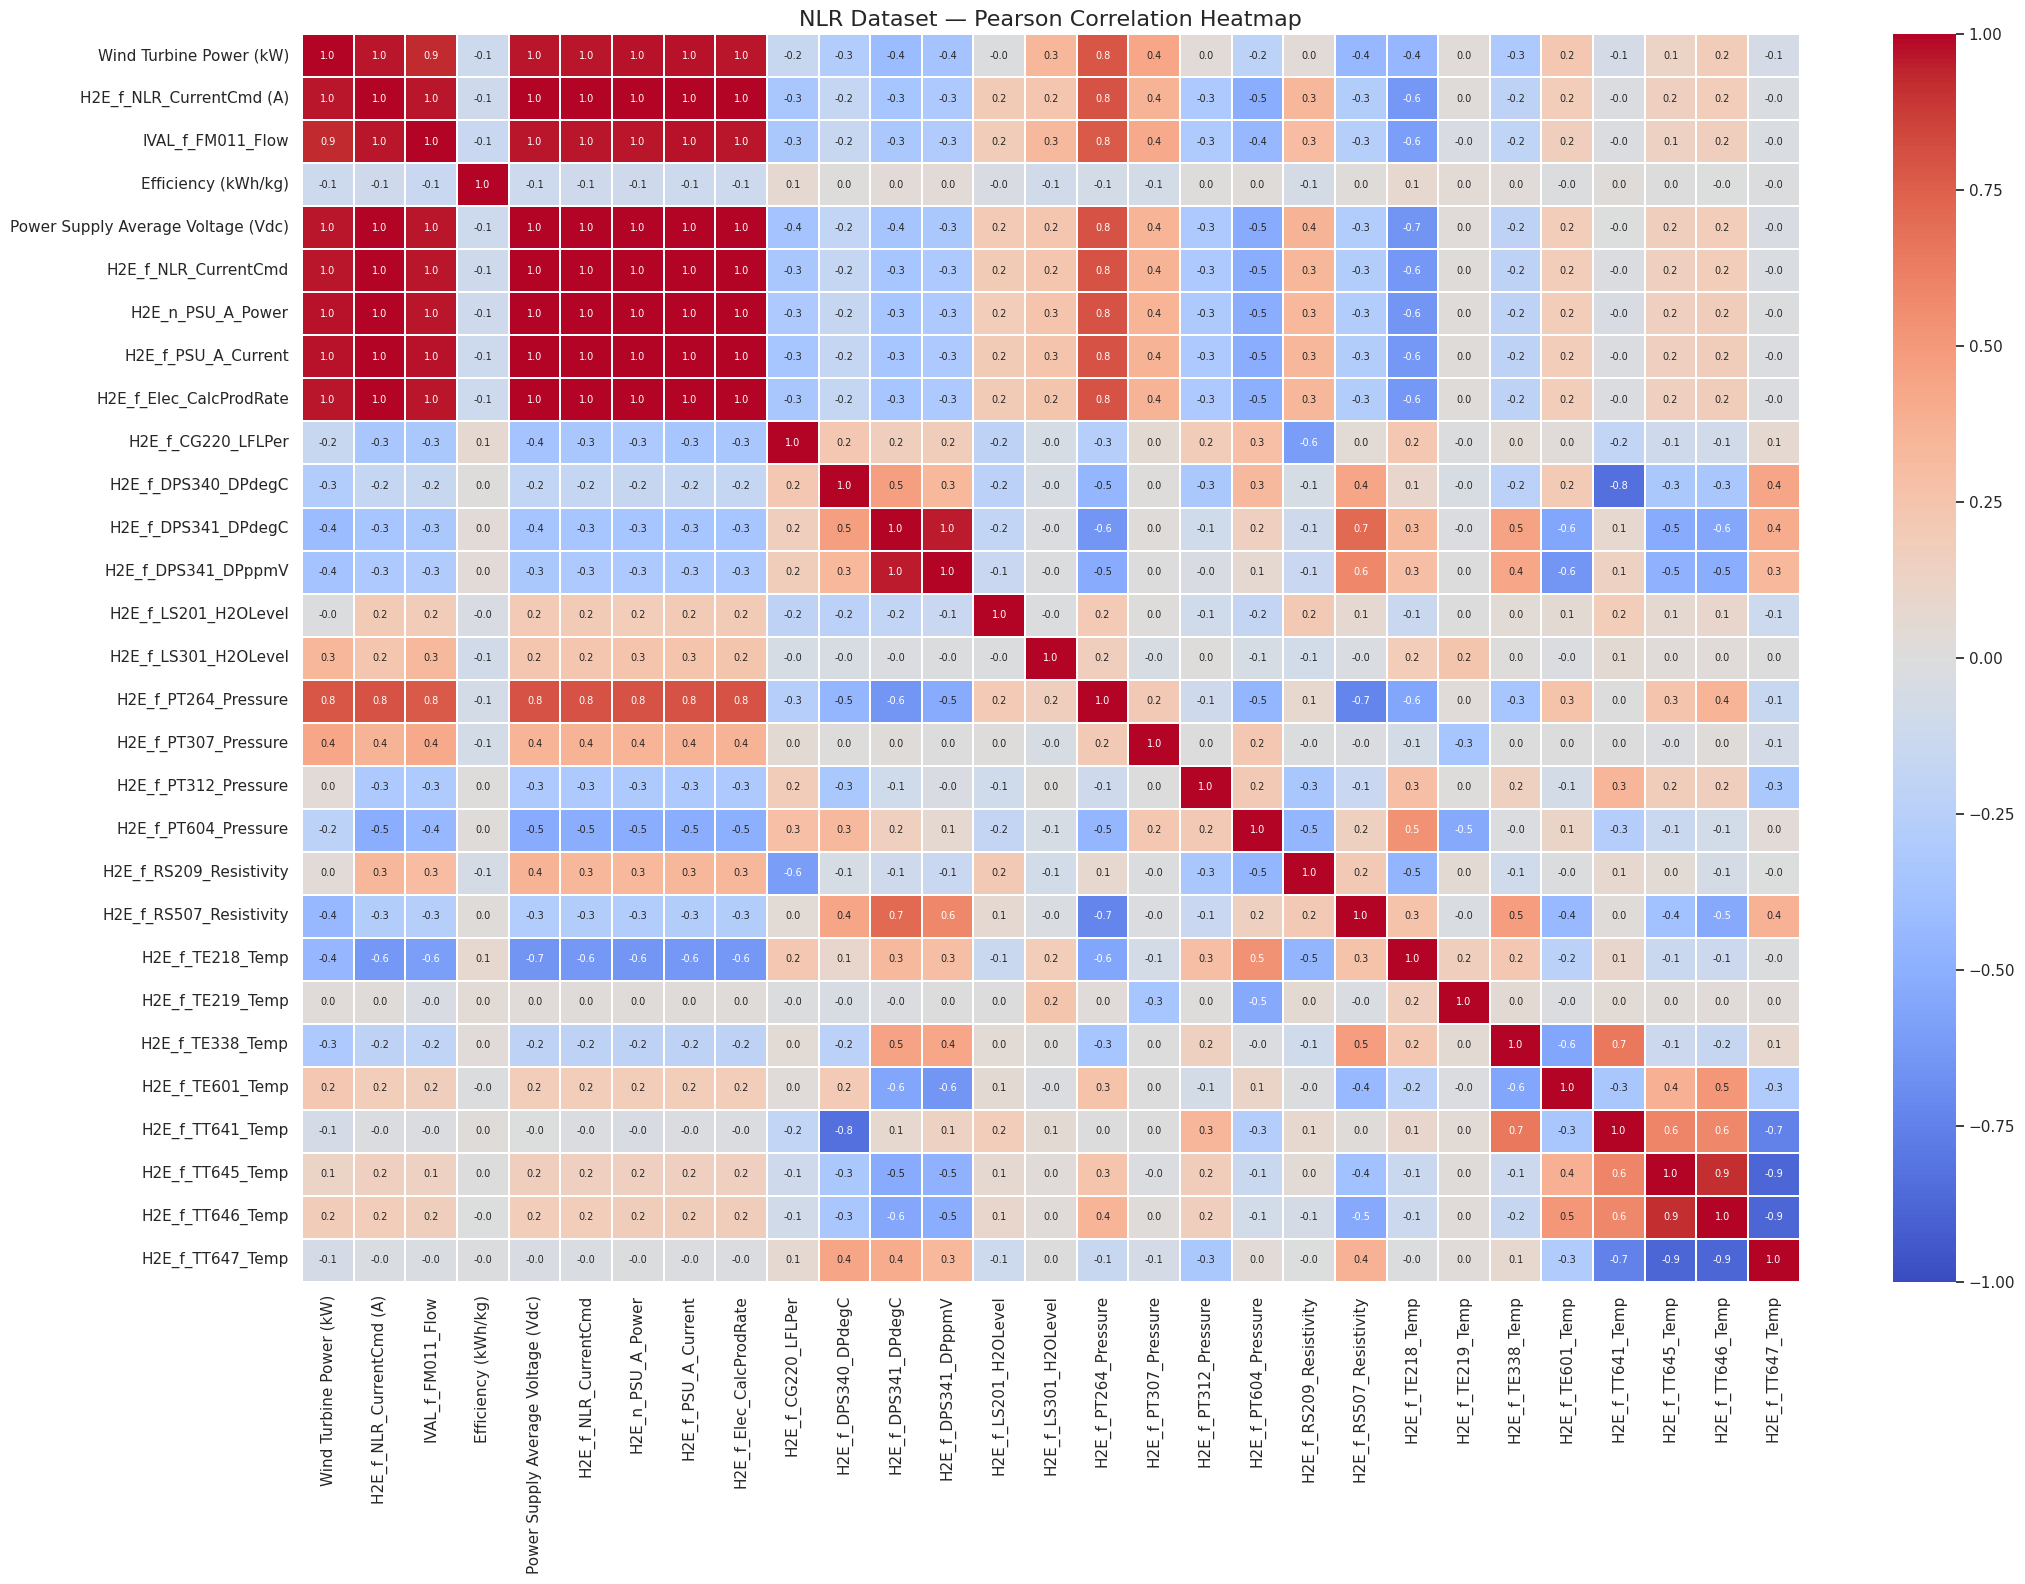

In [ ]:
# Cell 28 — Pearson Correlation Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(22, 16))

sns.heatmap(
    pearson_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title("NLR Dataset — Pearson Correlation Heatmap", fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Cell 29A — Inspect exact column names

for col in df.columns:
    if "CurrentCmd" in col:
        print(repr(col))# Cell 29A — Inspect exact column names

for col in df.columns:
    if "CurrentCmd" in col:
        print(repr(col))

'H2E_f_NLR_CurrentCmd (A)'
'H2E_f_NLR_CurrentCmd'
'H2E_f_NLR_CurrentCmd (A)'
'H2E_f_NLR_CurrentCmd'


In [ ]:
# Cell 29B — Check duplicate column labels

print("Total columns:", len(df.columns))
print("Unique column names:", df.columns.nunique())
print("\nDuplicate column names:")
print(df.columns[df.columns.duplicated(keep=False)].tolist())

print("\nPositions of current-command columns:")
for i, col in enumerate(df.columns):
    if "CurrentCmd" in col:
        print(i, repr(col))

print("\nValues from each matching column:")
for i, col in enumerate(df.columns):
    if "CurrentCmd" in col:
        print(f"\nColumn position: {i} | Name: {col}")
        display(df.iloc[:5, i])

Total columns: 32
Unique column names: 32

Duplicate column names:
[]

Positions of current-command columns:
2 'H2E_f_NLR_CurrentCmd (A)'
6 'H2E_f_NLR_CurrentCmd'

Values from each matching column:

Column position: 2 | Name: H2E_f_NLR_CurrentCmd (A)


,H2E_f_NLR_CurrentCmd (A)
0,995.024
1,1604.360
2,2067.155
3,2523.305
4,2608.763



Column position: 6 | Name: H2E_f_NLR_CurrentCmd


,H2E_f_NLR_CurrentCmd
0,33.167
1,53.479
2,68.905
3,84.110
4,86.959


In [ ]:
# Cell 29C — Check scaling between current-command variables

col1 = "H2E_f_NLR_CurrentCmd (A)"
col2 = "H2E_f_NLR_CurrentCmd"

ratio = df[col1] / df[col2]

print("Correlation:")
print(df[[col1, col2]].corr().iloc[0, 1])

print("\nRatio statistics:")
print(ratio.describe())

print("\nDoes multiplying the second column by 30 reproduce the first?")
difference = (df[col1] - (df[col2] * 30)).abs()

print(difference.describe())

print("\nMaximum absolute difference:", difference.max())

print("\nFirst 10 comparisons:")
display(pd.DataFrame({
    "CurrentCmd (A)": df[col1].head(10),
    "CurrentCmd": df[col2].head(10),
    "CurrentCmd × 30": (df[col2] * 30).head(10),
    "Absolute Difference": difference.head(10)
}))

Correlation:
0.9999999999522259

Ratio statistics:
count    61285.000000
mean        30.000001
std          0.000174
min         29.998666
25%         29.999928
50%         30.000000
75%         30.000072
max         30.001447
dtype: float64

Does multiplying the second column by 30 reproduce the first?
count    61285.000000
mean         0.005213
std          0.004997
min          0.000000
25%          0.000000
50%          0.004000
75%          0.010000
max          0.015000
dtype: float64

Maximum absolute difference: 0.015000000000327418

First 10 comparisons:


,CurrentCmd (A),CurrentCmd,CurrentCmd × 30,Absolute Difference
0,995.024,33.167,995.01,0.014
1,1604.360,53.479,1604.37,0.010
2,2067.155,68.905,2067.15,0.005
3,2523.305,84.110,2523.30,0.005
4,2608.763,86.959,2608.77,0.007
5,2608.763,86.959,2608.77,0.007
6,2678.972,89.299,2678.97,0.002
7,2746.985,91.566,2746.98,0.005
8,2746.985,91.566,2746.98,0.005
9,2747.806,91.594,2747.82,0.014


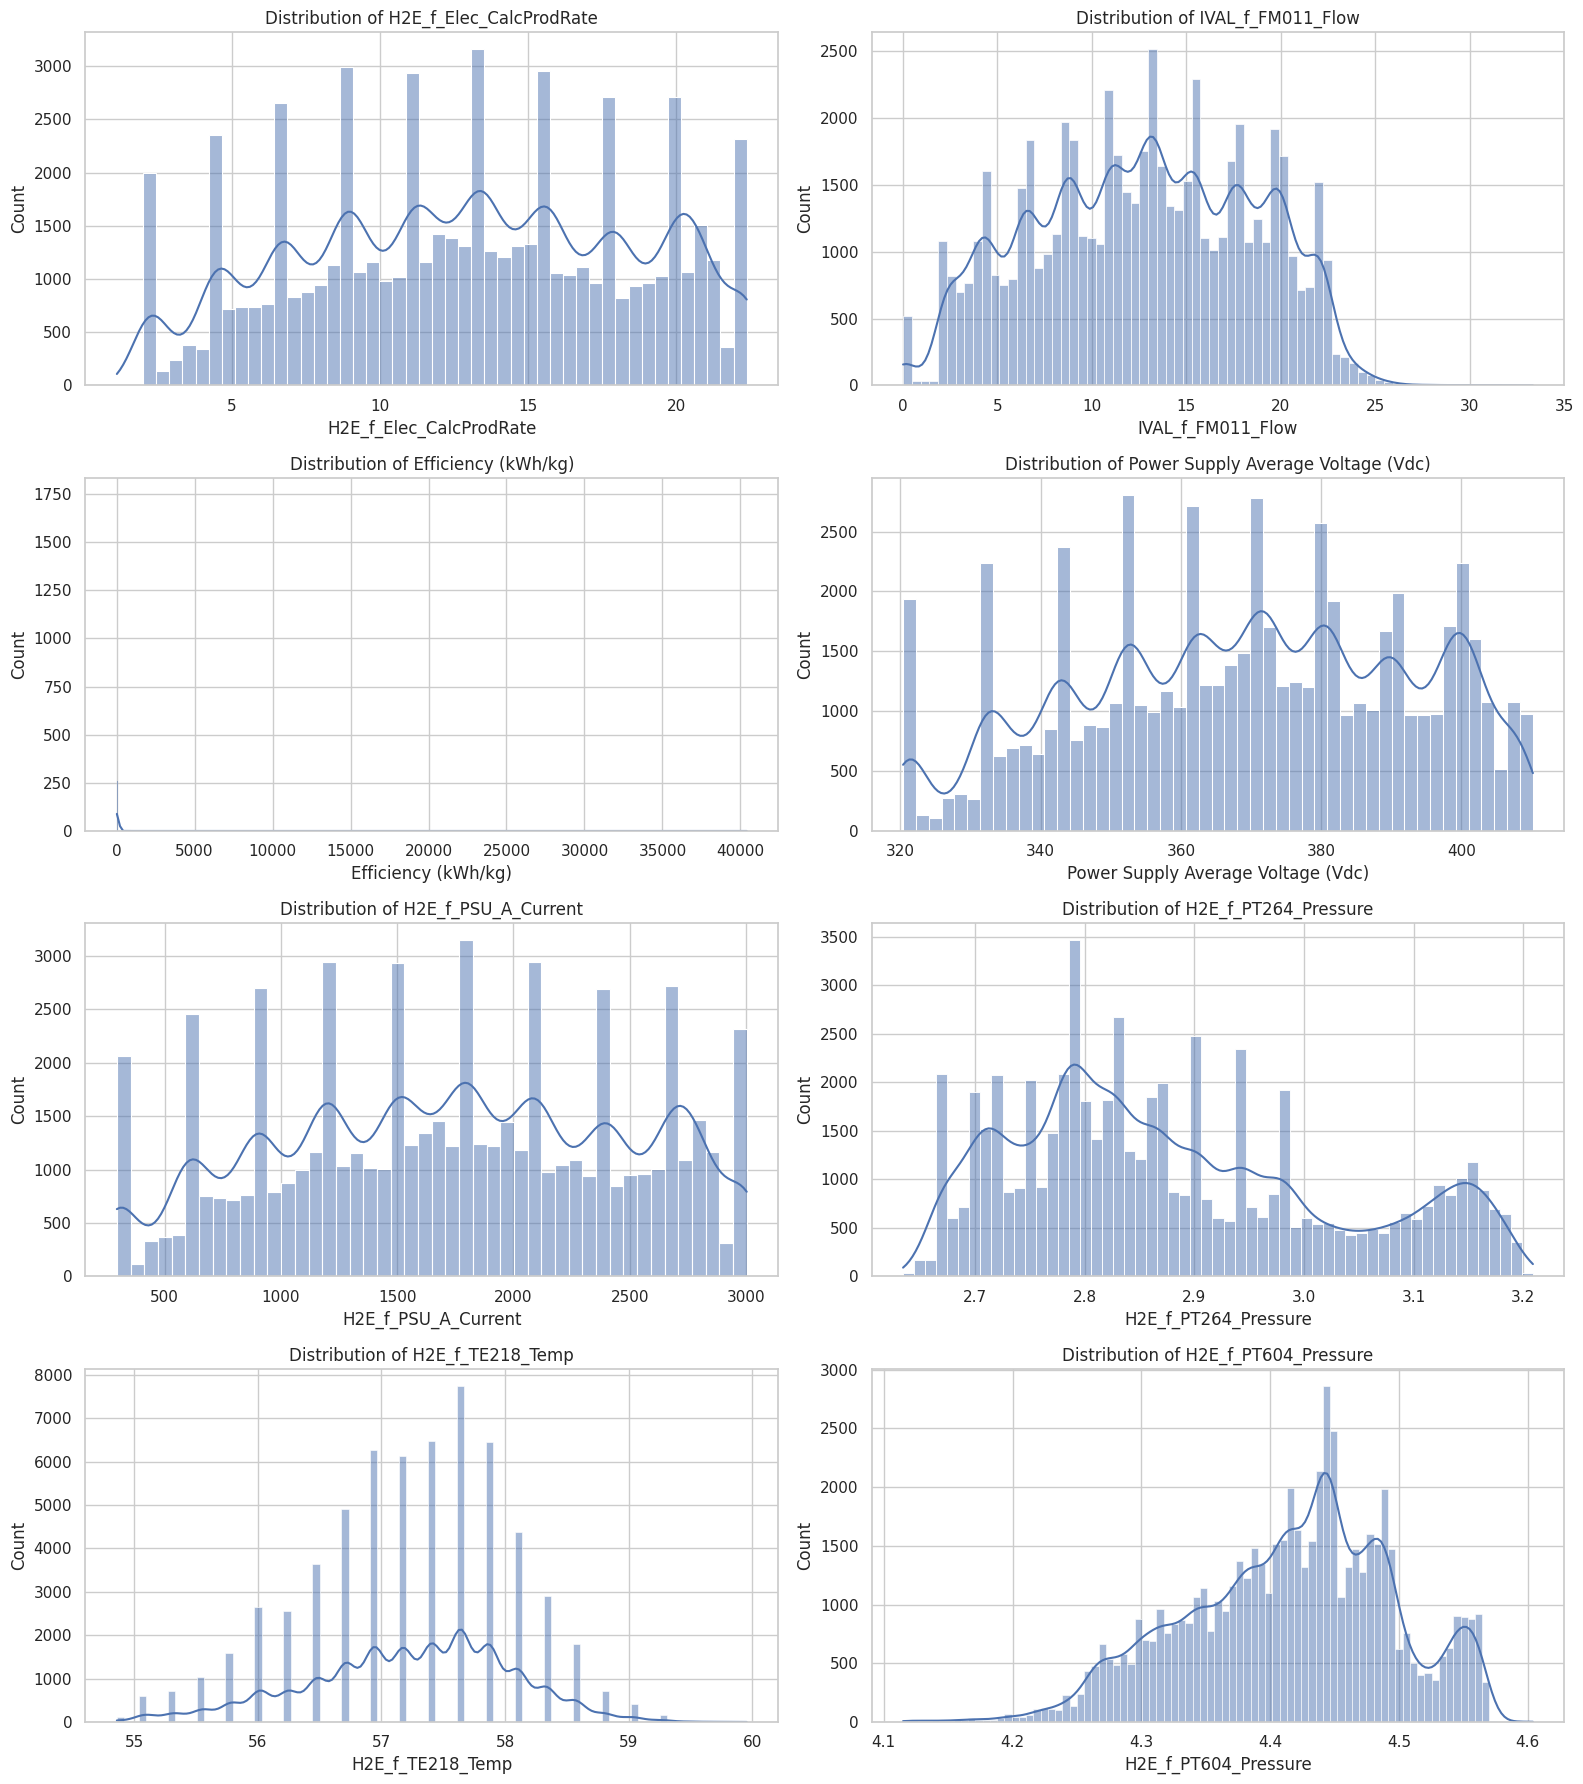

In [ ]:
# Cell 30 — Distribution Analysis of Key Variables

import matplotlib.pyplot as plt
import seaborn as sns

key_features = [
    "H2E_f_Elec_CalcProdRate",
    "IVAL_f_FM011_Flow",
    "Efficiency (kWh/kg)",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_PT604_Pressure"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.histplot(
        df[col].dropna(),
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 31 — Efficiency distribution and extreme-value assessment

eff = df["Efficiency (kWh/kg)"]

print("Efficiency summary:")
display(eff.describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame())

print("\nHighest 15 efficiency observations:")
display(
    df.nlargest(15, "Efficiency (kWh/kg)")[
        [
            "Efficiency (kWh/kg)",
            "IVAL_f_FM011_Flow",
            "H2E_f_Elec_CalcProdRate",
            "H2E_f_PSU_A_Current",
            "Power Supply Average Voltage (Vdc)"
        ]
    ]
)

print("\nCounts above selected thresholds:")
for threshold in [100, 200, 500, 1000, 5000, 10000]:
    count = (eff > threshold).sum()
    print(f"> {threshold:>6}: {count:>6} observations ({count / len(df) * 100:.3f}%)")

Efficiency summary:


,Efficiency (kWh/kg)
count,61284.000000
mean,115.773401
std,956.487253
min,21.113101
1%,36.184644
5%,41.093150
10%,43.723413
25%,47.789729
50%,51.662775
75%,55.789082



Highest 15 efficiency observations:


,Efficiency (kWh/kg),IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc)
23510,40400.00000,0.005,4.479,599,333.467
21029,39857.14286,0.007,6.015,807,340.633
19360,38142.85714,0.007,5.958,777,339.633
21028,37142.85714,0.007,5.960,757,339.100
21024,35857.14286,0.007,5.384,730,338.300
21027,35285.71429,0.007,5.397,722,338.233
19352,35166.66667,0.006,4.588,623,334.267
19355,35000.00000,0.006,4.631,621,334.300
19356,35000.00000,0.006,4.631,621,334.300
19353,34666.66667,0.006,4.633,615,334.167



Counts above selected thresholds:
>    100:    962 observations (1.570%)
>    200:    558 observations (0.911%)
>    500:    483 observations (0.788%)
>   1000:    425 observations (0.693%)
>   5000:    306 observations (0.499%)
>  10000:    153 observations (0.250%)


In [ ]:
# Cell 32A — Find experiment-related columns

print("Columns containing 'experiment':")

for col in df.columns:
    if "experiment" in col.lower():
        print(repr(col))

print("\nAll dataset columns:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

Columns containing 'experiment':
'Experiment'

All dataset columns:
0 'Unnamed: 0'
1 'Wind Turbine Power (kW)'
2 'H2E_f_NLR_CurrentCmd (A)'
3 'IVAL_f_FM011_Flow'
4 'Efficiency (kWh/kg)'
5 'Power Supply Average Voltage (Vdc)'
6 'H2E_f_NLR_CurrentCmd'
7 'H2E_n_PSU_A_Power'
8 'H2E_f_PSU_A_Current'
9 'H2E_f_Elec_CalcProdRate'
10 'H2E_f_CG220_LFLPer'
11 'H2E_f_DPS340_DPdegC'
12 'H2E_f_DPS341_DPdegC'
13 'H2E_f_DPS341_DPppmV'
14 'H2E_f_LS201_H2OLevel'
15 'H2E_f_LS301_H2OLevel'
16 'H2E_f_PT264_Pressure'
17 'H2E_f_PT307_Pressure'
18 'H2E_f_PT312_Pressure'
19 'H2E_f_PT604_Pressure'
20 'H2E_f_RS209_Resistivity'
21 'H2E_f_RS507_Resistivity'
22 'H2E_f_TE218_Temp'
23 'H2E_f_TE219_Temp'
24 'H2E_f_TE338_Temp'
25 'H2E_f_TE601_Temp'
26 'H2E_f_TT641_Temp'
27 'H2E_f_TT645_Temp'
28 'H2E_f_TT646_Temp'
29 'H2E_f_TT647_Temp'
30 'Experiment'
31 'Unnamed: 31'


In [ ]:
# Cell 32B — Efficiency statistics by experiment

efficiency_by_experiment = (
    df.groupby("Experiment")["Efficiency (kWh/kg)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        P95=lambda x: x.quantile(0.95),
        P99=lambda x: x.quantile(0.99),
        Maximum="max"
    )
    .sort_values("Median")
)

display(efficiency_by_experiment.round(2))

,Count,Mean,Median,P95,P99,Maximum
Experiment,,,,,,
windIEA3.4-5ms-C_2-200.csv,3652,115.09,49.81,73.55,131.08,10058.82
windIEA3.4-5ms-C_2-400.csv,3652,114.61,49.95,70.90,114.85,40400.00
windIEA3.4-5ms-A_2-200.csv,3652,269.89,50.28,89.74,7756.50,16352.94
windIEA3.4-5ms-A_2-400.csv,3652,365.40,50.38,100.29,15854.29,39857.14
windIEA3.4-7ms-C_1-200.csv,3591,52.63,51.09,69.85,90.67,114.32
characterization_200.csv,18000,103.62,51.21,57.22,64.56,12375.00
windIEA3.4-7ms-C_1-400.csv,3591,53.07,51.29,70.74,94.37,120.41
windIEA3.4-7ms-A_1-200.csv,3591,105.45,51.51,78.86,138.94,12950.00
windIEA3.4-7ms-A_1-400.csv,3591,128.87,51.78,79.34,133.40,17200.00


In [ ]:
# Cell 33 — Extreme efficiency counts by experiment

efficiency_extremes = (
    df.groupby("Experiment")["Efficiency (kWh/kg)"]
    .agg(
        Total="count",
        Above_100=lambda x: (x > 100).sum(),
        Above_500=lambda x: (x > 500).sum(),
        Above_1000=lambda x: (x > 1000).sum()
    )
)

efficiency_extremes["Above_100_Percent"] = (
    efficiency_extremes["Above_100"] /
    efficiency_extremes["Total"] * 100
)

efficiency_extremes["Above_1000_Percent"] = (
    efficiency_extremes["Above_1000"] /
    efficiency_extremes["Total"] * 100
)

display(efficiency_extremes.round(3))

,Total,Above_100,Above_500,Above_1000,Above_100_Percent,Above_1000_Percent
Experiment,,,,,,
characterization_200.csv,18000,156,126,117,0.867,0.650
windIEA3.4-5ms-A_2-200.csv,3652,164,133,123,4.491,3.368
windIEA3.4-5ms-A_2-400.csv,3652,184,111,82,5.038,2.245
windIEA3.4-5ms-C_2-200.csv,3652,80,34,34,2.191,0.931
windIEA3.4-5ms-C_2-400.csv,3652,59,21,17,1.616,0.465
windIEA3.4-7ms-A_1-200.csv,3591,92,24,23,2.562,0.640
windIEA3.4-7ms-A_1-400.csv,3591,100,26,25,2.785,0.696
windIEA3.4-7ms-C_1-200.csv,3591,14,0,0,0.390,0.000
windIEA3.4-7ms-C_1-400.csv,3591,19,0,0,0.529,0.000


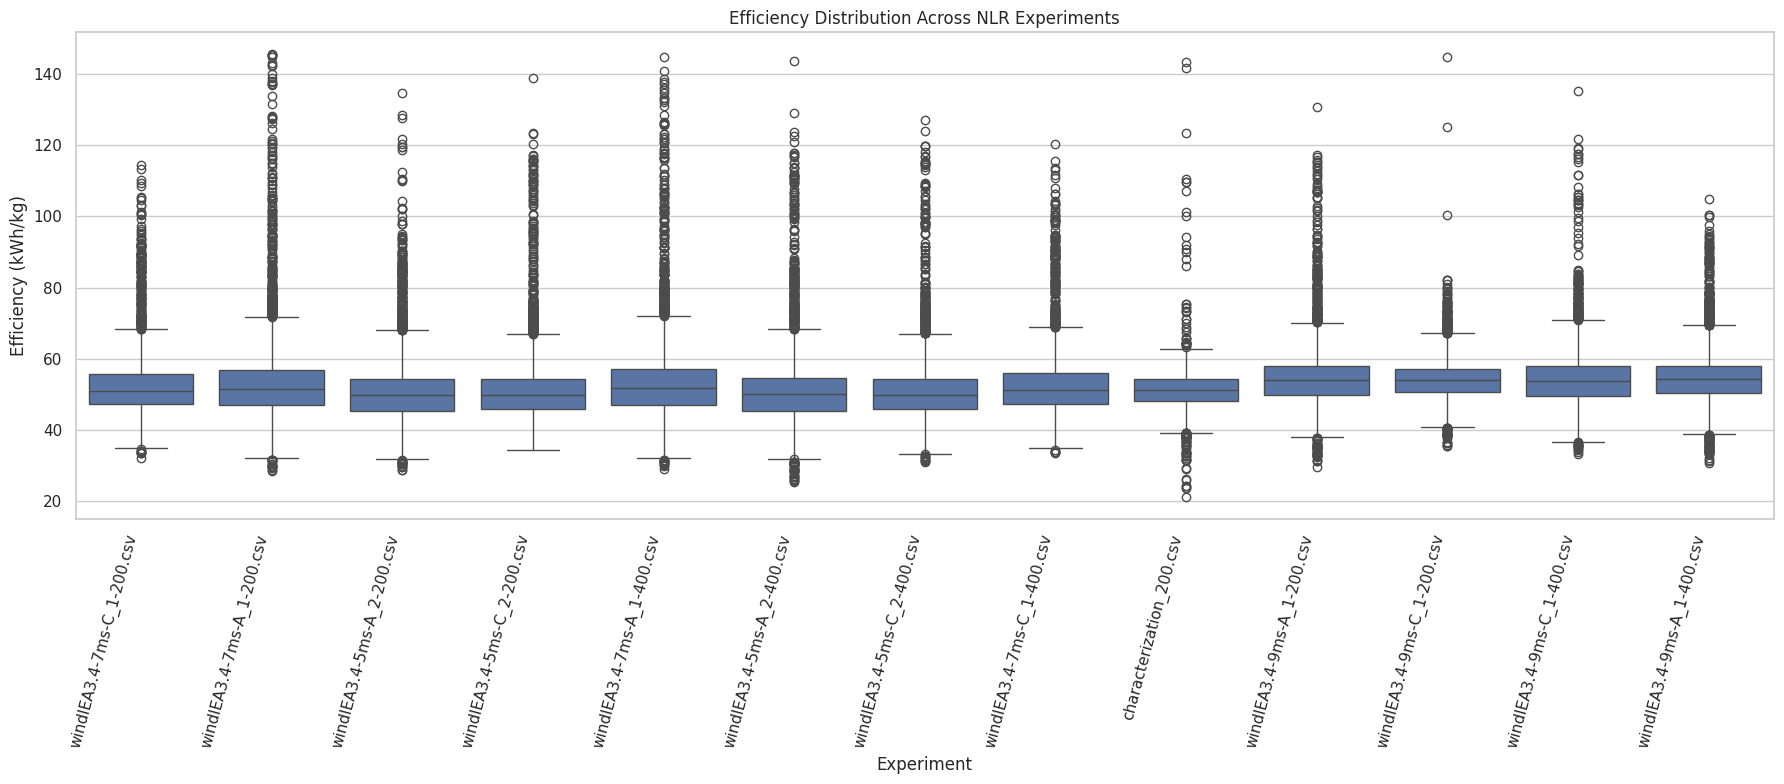

In [ ]:
# Cell 34 — Efficiency distribution by experiment

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df[df["Efficiency (kWh/kg)"] < 150].copy()

plt.figure(figsize=(18, 8))

sns.boxplot(
    data=plot_df,
    x="Experiment",
    y="Efficiency (kWh/kg)"
)

plt.title("Efficiency Distribution Across NLR Experiments")
plt.xlabel("Experiment")
plt.ylabel("Efficiency (kWh/kg)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Cell 35 — Operating-condition coverage by experiment

operating_features = [
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

operating_ranges = (
    df.groupby("Experiment")[operating_features]
    .agg(["min",
          lambda x: x.quantile(0.10),
          "median",
          lambda x: x.quantile(0.90),
          "max"])
)

operating_ranges.columns = [
    f"{feature}_{stat}"
    for feature, stat in operating_ranges.columns
    for stat in []
] if False else [
    f"{feature}_{['min', 'p10', 'median', 'p90', 'max'][i % 5]}"
    for i, (feature, stat) in enumerate(operating_ranges.columns)
]

display(operating_ranges.round(3))

,IVAL_f_FM011_Flow_min,IVAL_f_FM011_Flow_p10,IVAL_f_FM011_Flow_median,IVAL_f_FM011_Flow_p90,IVAL_f_FM011_Flow_max,H2E_f_Elec_CalcProdRate_min,H2E_f_Elec_CalcProdRate_p10,H2E_f_Elec_CalcProdRate_median,H2E_f_Elec_CalcProdRate_p90,H2E_f_Elec_CalcProdRate_max,Power Supply Average Voltage (Vdc)_min,Power Supply Average Voltage (Vdc)_p10,Power Supply Average Voltage (Vdc)_median,Power Supply Average Voltage (Vdc)_p90,Power Supply Average Voltage (Vdc)_max,H2E_f_PSU_A_Current_min,H2E_f_PSU_A_Current_p10,H2E_f_PSU_A_Current_median,H2E_f_PSU_A_Current_p90,H2E_f_PSU_A_Current_max,H2E_f_PT264_Pressure_min,H2E_f_PT264_Pressure_p10,H2E_f_PT264_Pressure_median,H2E_f_PT264_Pressure_p90,H2E_f_PT264_Pressure_max,H2E_f_TE218_Temp_min,H2E_f_TE218_Temp_p10,H2E_f_TE218_Temp_median,H2E_f_TE218_Temp_p90,H2E_f_TE218_Temp_max
Experiment,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
characterization_200.csv,0.008,3.219,12.330,20.354,22.651,1.119,3.131,11.190,20.142,22.380,320.367,331.630,363.084,400.503,410.200,295,596.0,1504.0,2702.0,3003,2.662,2.696,2.800,2.947,2.988,54.861,55.556,57.639,58.333,59.028
windIEA3.4-5ms-A_2-200.csv,0.016,3.314,10.171,17.220,25.214,2.238,3.947,10.293,16.734,22.380,320.533,330.467,358.616,384.633,408.300,297,532.1,1382.0,2239.0,3002,2.703,2.757,2.813,2.917,3.004,56.019,56.713,57.407,58.565,59.259
windIEA3.4-5ms-A_2-400.csv,0.005,3.311,10.206,17.119,27.199,2.238,3.953,10.325,16.736,22.380,321.300,330.500,358.516,384.597,408.067,299,533.2,1384.0,2249.7,3002,2.644,2.685,2.750,2.866,2.956,56.019,56.713,57.407,58.333,59.259
windIEA3.4-5ms-C_2-200.csv,0.016,3.785,9.858,14.977,23.172,2.238,4.978,9.990,14.597,21.227,321.167,335.270,357.433,376.300,402.200,299,667.1,1339.5,1958.0,2843,2.701,2.769,2.808,2.879,2.985,56.481,56.944,57.639,58.542,59.259
windIEA3.4-5ms-C_2-400.csv,0.005,4.044,9.819,14.744,25.957,2.238,4.957,9.992,14.592,21.248,321.633,335.333,357.500,376.100,401.567,300,663.1,1339.5,1956.9,2848,2.648,2.679,2.742,2.827,2.938,56.713,57.176,57.639,58.333,59.028
windIEA3.4-7ms-A_1-200.csv,0.018,5.049,13.168,19.921,25.976,2.555,6.172,13.076,19.635,22.380,322.500,340.500,370.433,397.100,409.433,341,831.0,1753.0,2633.0,3003,2.719,2.777,2.857,2.965,3.012,55.324,56.481,57.407,58.333,59.259
windIEA3.4-7ms-A_1-400.csv,0.014,4.920,13.135,19.999,26.382,2.555,6.213,13.091,19.663,22.380,322.667,341.167,370.567,397.100,409.167,341,833.0,1754.0,2634.0,3001,2.715,2.768,2.849,2.955,2.999,55.324,56.481,57.176,58.333,59.491
windIEA3.4-7ms-C_1-200.csv,2.725,6.487,12.753,18.024,25.957,4.194,7.406,12.735,17.592,22.380,330.500,345.600,368.700,388.333,408.167,549,989.0,1705.0,2357.0,3002,2.777,2.810,2.867,2.948,3.030,55.787,56.713,57.407,58.102,58.796
windIEA3.4-7ms-C_1-400.csv,2.706,6.329,12.615,17.858,31.941,4.058,7.399,12.761,17.628,22.380,331.533,346.533,369.400,388.900,408.533,561,996.0,1710.0,2365.0,3001,2.634,2.678,2.782,2.869,2.950,55.787,56.481,57.176,58.102,58.565


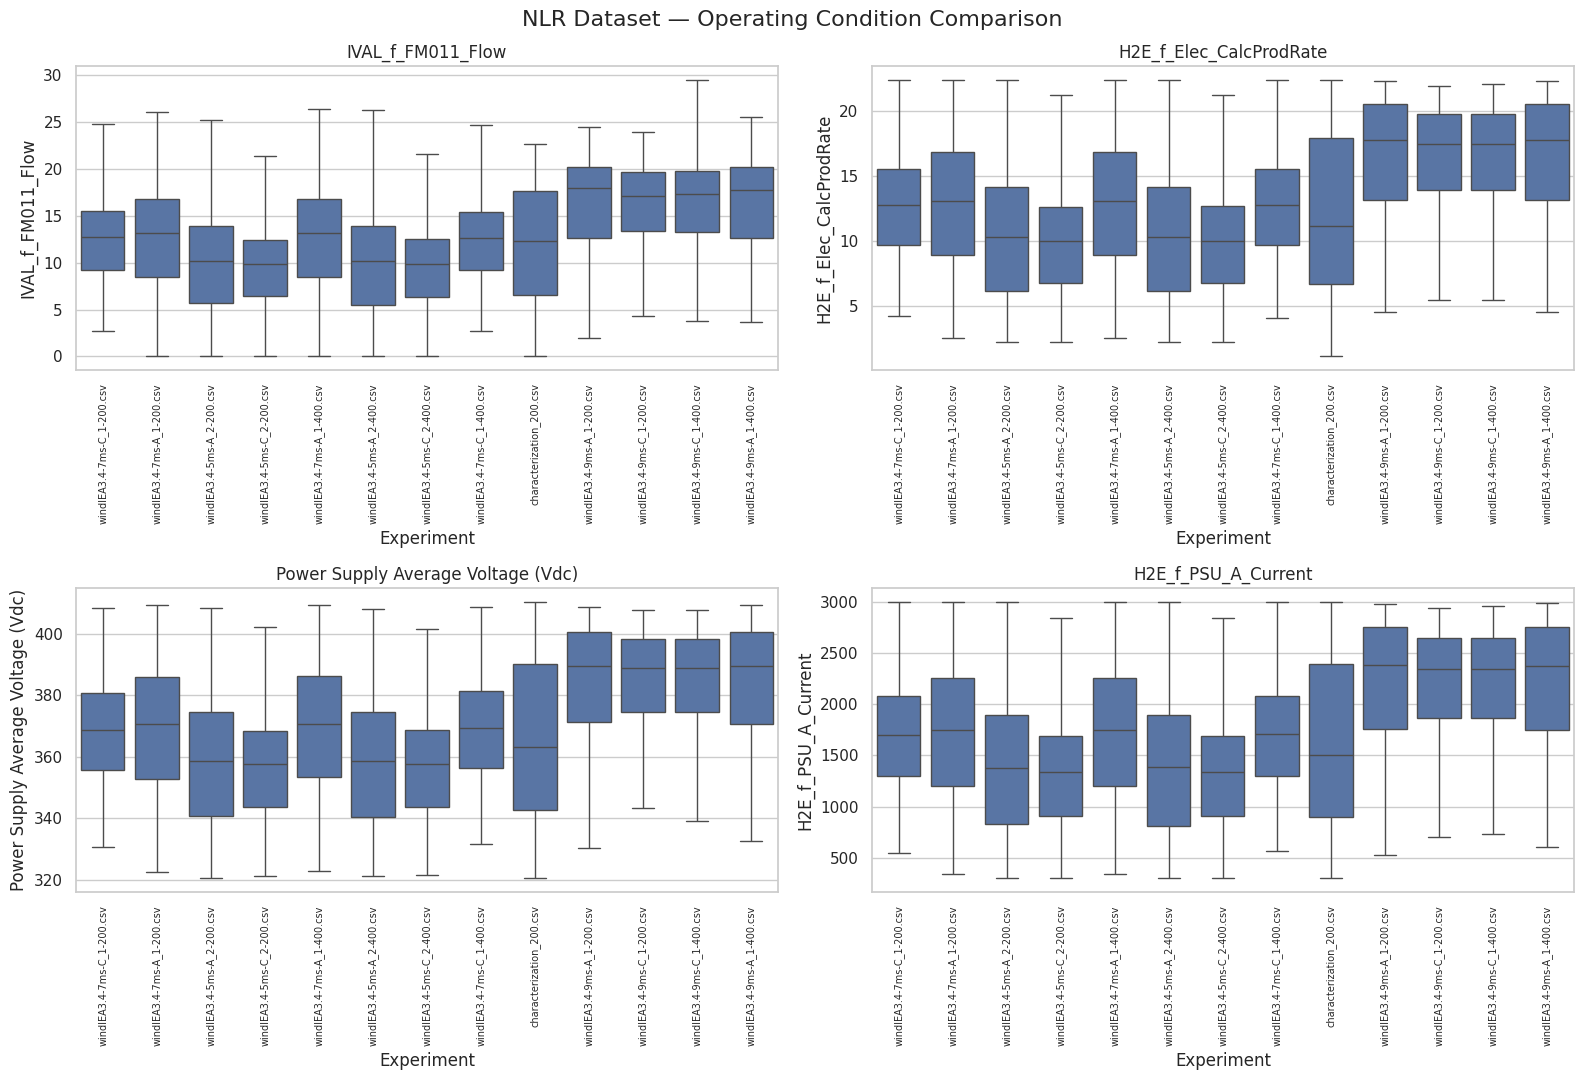

In [ ]:
# Cell 36 — Operating condition comparison by experiment

import seaborn as sns
import matplotlib.pyplot as plt

features_to_plot = [
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes = axes.flatten()

for i, feature in enumerate(features_to_plot):
    sns.boxplot(
        data=df,
        x="Experiment",
        y=feature,
        ax=axes[i],
        showfliers=False
    )
    axes[i].set_title(feature)
    axes[i].tick_params(axis="x", rotation=90, labelsize=7)

plt.suptitle(
    "NLR Dataset — Operating Condition Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 37 — Complete NLR Missing Value Audit

import pandas as pd

# Overall missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(3),
    "Data_Type": df.dtypes.astype(str)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

print("\nOverall missing-value summary:")
display(missing_summary)

# Missing values by experiment
missing_by_experiment = df.groupby("Experiment").apply(
    lambda group: group.isnull().sum(),
    include_groups=False
)

print("\nMissing values by experiment:")
display(missing_by_experiment.loc[:, missing_by_experiment.sum() > 0])

# Verify original dataframe remains unchanged
print("\nOriginal dataframe shape:", df.shape)

Dataset shape: (61285, 32)
Total missing values: 79287

Overall missing-value summary:


,Missing_Count,Missing_Percentage,Data_Type
Unnamed: 31,46972,76.645,float64
Wind Turbine Power (kW),18000,29.371,float64
H2E_f_TT641_Temp,14313,23.355,float64
Efficiency (kWh/kg),1,0.002,float64
IVAL_f_FM011_Flow,1,0.002,float64



Missing values by experiment:


,Wind Turbine Power (kW),IVAL_f_FM011_Flow,Efficiency (kWh/kg),H2E_f_TT641_Temp,Unnamed: 31
Experiment,,,,,
characterization_200.csv,18000,0,0,0,18000
windIEA3.4-5ms-A_2-200.csv,0,0,0,0,3652
windIEA3.4-5ms-A_2-400.csv,0,0,0,0,3652
windIEA3.4-5ms-C_2-200.csv,0,0,0,0,3652
windIEA3.4-5ms-C_2-400.csv,0,0,0,0,3652
windIEA3.4-7ms-A_1-200.csv,0,0,0,0,3591
windIEA3.4-7ms-A_1-400.csv,0,0,0,0,3591
windIEA3.4-7ms-C_1-200.csv,0,0,0,0,3591
windIEA3.4-7ms-C_1-400.csv,0,0,0,0,3591



Original dataframe shape: (61285, 32)


In [ ]:
# Cell 38 — Inspect isolated missing observations

columns_to_check = [
    "IVAL_f_FM011_Flow",
    "Efficiency (kWh/kg)"
]

for col in columns_to_check:
    print(f"\n{'='*65}")
    print("Missing column:", col)

    missing_indices = df.index[df[col].isna()].tolist()

    for idx in missing_indices:
        print(f"\nMissing row index: {idx}")

        start = max(0, idx - 2)
        end = min(len(df), idx + 3)

        display(
            df.iloc[start:end][
                ["Unnamed: 0", "Experiment", col,
                 "H2E_f_Elec_CalcProdRate",
                 "H2E_f_PSU_A_Current",
                 "Power Supply Average Voltage (Vdc)"]
            ]
        )


Missing column: IVAL_f_FM011_Flow

Missing row index: 54944


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc)
54942,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.635,21.317,2858,404.300
54943,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.825,21.317,2859,403.633
54944,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,NaN,21.319,2862,403.467
54945,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.726,21.319,2859,404.267
54946,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.858,21.299,2855,403.533



Missing column: Efficiency (kWh/kg)

Missing row index: 54944


,Unnamed: 0,Experiment,Efficiency (kWh/kg),H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc)
54942,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,57.184395,21.317,2858,404.300
54943,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,56.662665,21.317,2859,403.633
54944,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,NaN,21.319,2862,403.467
54945,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,56.981569,21.319,2859,404.267
54946,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,56.525074,21.299,2855,403.533


In [ ]:
# Cell 39 — Local flow continuity around missing observation

idx = 54944

cols = [
    "Unnamed: 0",
    "Experiment",
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_PSU_A_Current"
]

local_data = df.iloc[idx-10:idx+11][cols].copy()

display(local_data)

print("\nFlow statistics in neighbourhood:")
print(local_data["IVAL_f_FM011_Flow"].describe())

print("\nTimestamp distribution:")
print(local_data["Unnamed: 0"].value_counts())

,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current
54934,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,19.808,20.916,2782
54935,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.082,21.131,2815
54936,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.114,21.131,2832
54937,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.130,21.189,2839
54938,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.192,21.150,2832
54939,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.305,21.268,2851
54940,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.433,21.240,2844
54941,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.513,21.296,2854
54942,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.635,21.317,2858
54943,8/4/2025 11:56,windIEA3.4-9ms-C_1-400.csv,20.825,21.317,2859



Flow statistics in neighbourhood:
count    20.000000
mean     20.577900
std       0.357949
min      19.808000
25%      20.276750
50%      20.726000
75%      20.835500
max      21.090000
Name: IVAL_f_FM011_Flow, dtype: float64

Timestamp distribution:
Unnamed: 0
8/4/2025 11:56    21
Name: count, dtype: int64


In [ ]:
# Cell 40 — Apply justified missing-value treatment to a working copy

df_nlr_work = df.copy()

# Preserve a flag identifying the estimated flow observation
df_nlr_work["Flow_Was_Interpolated"] = 0

missing_flow_idx = 54944

# Linear interpolation using the immediate neighbouring observations
previous_flow = df_nlr_work.loc[missing_flow_idx - 1, "IVAL_f_FM011_Flow"]
next_flow = df_nlr_work.loc[missing_flow_idx + 1, "IVAL_f_FM011_Flow"]

interpolated_flow = (previous_flow + next_flow) / 2

df_nlr_work.loc[
    missing_flow_idx, "IVAL_f_FM011_Flow"
] = interpolated_flow

df_nlr_work.loc[
    missing_flow_idx, "Flow_Was_Interpolated"
] = 1

# Report the changes
print("Original dataframe shape:", df.shape)
print("Working dataframe shape:", df_nlr_work.shape)

print("\nInterpolated flow value:", interpolated_flow)

print("\nRemaining missing values in relevant columns:")
print(
    df_nlr_work[
        [
            "IVAL_f_FM011_Flow",
            "Efficiency (kWh/kg)",
            "Wind Turbine Power (kW)",
            "H2E_f_TT641_Temp",
            "Unnamed: 31"
        ]
    ].isna().sum()
)

print("\nInterpolated observation:")
display(
    df_nlr_work.loc[
        [missing_flow_idx],
        [
            "Experiment",
            "IVAL_f_FM011_Flow",
            "Flow_Was_Interpolated",
            "Efficiency (kWh/kg)"
        ]
    ]
)

print("\nOriginal dataframe unchanged:", df["IVAL_f_FM011_Flow"].isna().sum() == 1)

Original dataframe shape: (61285, 32)
Working dataframe shape: (61285, 33)

Interpolated flow value: 20.7755

Remaining missing values in relevant columns:
IVAL_f_FM011_Flow              0
Efficiency (kWh/kg)            1
Wind Turbine Power (kW)    18000
H2E_f_TT641_Temp           14313
Unnamed: 31                46972
dtype: int64

Interpolated observation:


,Experiment,IVAL_f_FM011_Flow,Flow_Was_Interpolated,Efficiency (kWh/kg)
54944,windIEA3.4-9ms-C_1-400.csv,20.7755,1,NaN



Original dataframe unchanged: True


In [ ]:
# Cell 41 — NLR exact duplicate observation audit

print("Dataset shape:", df_nlr_work.shape)

# Count fully duplicated rows
exact_duplicate_count = df_nlr_work.duplicated().sum()

print("\nExact duplicate rows:", exact_duplicate_count)
print(
    "Percentage of dataset:",
    round(exact_duplicate_count / len(df_nlr_work) * 100, 4),
    "%"
)

# Check duplicates excluding the interpolation indicator
# This helps identify whether the new flag affects duplicate detection.
original_columns = df.columns.tolist()

original_duplicate_count = df_nlr_work.duplicated(
    subset=original_columns
).sum()

print("\nDuplicates across original 32 columns:", original_duplicate_count)

# Display duplicate rows, if present
if original_duplicate_count > 0:
    duplicate_rows = df_nlr_work[
        df_nlr_work.duplicated(
            subset=original_columns,
            keep=False
        )
    ].sort_values(["Experiment", "Unnamed: 0"])

    display(duplicate_rows.head(20))
else:
    print("\nNo exact duplicates found across the original dataset columns.")

Dataset shape: (61285, 33)

Exact duplicate rows: 204
Percentage of dataset: 0.3329 %

Duplicates across original 32 columns: 204


,Unnamed: 0,Wind Turbine Power (kW),H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Efficiency (kWh/kg),Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,H2E_f_Elec_CalcProdRate,H2E_f_CG220_LFLPer,H2E_f_DPS340_DPdegC,H2E_f_DPS341_DPdegC,H2E_f_DPS341_DPppmV,H2E_f_LS201_H2OLevel,H2E_f_LS301_H2OLevel,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_RS209_Resistivity,H2E_f_RS507_Resistivity,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp,Experiment,Unnamed: 31,Flow_Was_Interpolated
29118,7/11/2025 10:46,NaN,3000.0,22.415,56.123132,408.433,100.0,1258,2999,22.38,0.123,-49.097,-51.806,1.049,61.874,29.340,2.984,28.933,24.821,4.301,6.857,14.925,55.556,58.102,10.900,29.996,6.8,8.3,9.3,18.1,characterization_200.csv,NaN,0
29119,7/11/2025 10:46,NaN,3000.0,22.415,56.123132,408.433,100.0,1258,2999,22.38,0.123,-49.097,-51.806,1.049,61.874,29.340,2.984,28.933,24.821,4.301,6.857,14.925,55.556,58.102,10.900,29.996,6.8,8.3,9.3,18.1,characterization_200.csv,NaN,0
29120,7/11/2025 10:46,NaN,3000.0,22.422,56.061012,408.167,100.0,1257,2999,22.38,0.123,-49.097,-51.806,1.050,61.872,29.428,2.985,28.929,24.819,4.300,6.854,15.152,55.556,58.102,10.900,29.996,6.8,8.3,9.4,18.2,characterization_200.csv,NaN,0
29121,7/11/2025 10:46,NaN,3000.0,22.422,56.061012,408.167,100.0,1257,2999,22.38,0.123,-49.097,-51.806,1.050,61.872,29.428,2.985,28.929,24.819,4.300,6.854,15.152,55.556,58.102,10.900,29.996,6.8,8.3,9.4,18.2,characterization_200.csv,NaN,0
29125,7/11/2025 10:47,NaN,3000.0,22.394,56.131107,407.667,100.0,1257,3000,22.38,0.123,-49.028,-51.840,1.050,61.854,29.592,2.984,28.923,24.814,4.299,6.827,15.385,55.556,58.102,10.900,30.006,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0
29126,7/11/2025 10:47,NaN,3000.0,22.394,56.131107,407.667,100.0,1257,3000,22.38,0.123,-49.028,-51.840,1.050,61.854,29.592,2.984,28.923,24.814,4.299,6.827,15.385,55.556,58.102,10.900,30.006,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0
29129,7/11/2025 10:47,NaN,3000.0,22.369,56.193840,407.333,100.0,1257,3000,22.38,0.123,-49.097,-51.875,1.041,61.836,29.694,2.983,28.920,24.809,4.295,6.829,15.152,55.556,58.102,10.895,30.012,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0
29130,7/11/2025 10:47,NaN,3000.0,22.369,56.193840,407.333,100.0,1257,3000,22.38,0.123,-49.097,-51.875,1.041,61.836,29.694,2.983,28.920,24.809,4.295,6.829,15.152,55.556,58.102,10.895,30.012,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0
29132,7/11/2025 10:47,NaN,3000.0,22.514,55.787510,408.500,100.0,1256,3001,22.38,0.123,-49.028,-51.840,1.045,61.776,29.813,2.981,28.917,24.805,4.284,6.823,15.385,55.556,58.333,10.895,30.017,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0
29133,7/11/2025 10:47,NaN,3000.0,22.514,55.787510,408.500,100.0,1256,3001,22.38,0.123,-49.028,-51.840,1.045,61.776,29.813,2.981,28.917,24.805,4.284,6.823,15.385,55.556,58.333,10.895,30.017,6.8,8.3,9.3,18.2,characterization_200.csv,NaN,0


In [ ]:
# Cell 42 — Investigate exact duplicate groups

original_columns = df.columns.tolist()

# Identify every row belonging to an exact duplicate group
duplicate_mask = df.duplicated(
    subset=original_columns,
    keep=False
)

duplicate_data = df.loc[duplicate_mask].copy()

print("Rows involved in duplicate groups:", len(duplicate_data))

print("\n1. Duplicate rows by experiment:")
display(
    duplicate_data["Experiment"]
    .value_counts()
    .to_frame("Duplicate_Rows")
)

print("\n2. Number of occurrences per unique duplicated observation:")
duplicate_group_sizes = (
    duplicate_data
    .groupby(original_columns, dropna=False)
    .size()
    .value_counts()
    .sort_index()
)

display(
    duplicate_group_sizes.to_frame("Number_of_Groups")
)

print("\n3. Duplicate groups by experiment and timestamp:")
duplicate_groups = (
    duplicate_data
    .groupby(
        ["Experiment", "Unnamed: 0"],
        dropna=False
    )
    .size()
    .reset_index(name="Repeated_Rows")
)

display(duplicate_groups.head(25))

print("\nTotal unique duplicated observations:", len(duplicate_groups))

Rows involved in duplicate groups: 408

1. Duplicate rows by experiment:


,Duplicate_Rows
Experiment,
characterization_200.csv,344
windIEA3.4-9ms-A_1-400.csv,64



2. Number of occurrences per unique duplicated observation:


,Number_of_Groups
2,204



3. Duplicate groups by experiment and timestamp:


,Experiment,Unnamed: 0,Repeated_Rows
0,characterization_200.csv,7/11/2025 10:46,4
1,characterization_200.csv,7/11/2025 10:47,16
2,characterization_200.csv,7/11/2025 10:50,4
3,characterization_200.csv,7/11/2025 10:55,6
4,characterization_200.csv,7/11/2025 10:56,12
5,characterization_200.csv,7/11/2025 11:13,10
6,characterization_200.csv,7/11/2025 11:19,4
7,characterization_200.csv,7/11/2025 11:21,2
8,characterization_200.csv,7/11/2025 11:22,2
9,characterization_200.csv,7/11/2025 11:46,18



Total unique duplicated observations: 59


In [ ]:
# Cell 43 — Check duplicate pair positions in original row order

original_columns = df.columns.tolist()

duplicate_groups = (
    df.groupby(original_columns, dropna=False)
      .apply(lambda group: list(group.index), include_groups=False)
)

# Keep only groups containing duplicates
duplicate_groups = duplicate_groups[
    duplicate_groups.apply(len) > 1
]

# Calculate row-index distance within each duplicate pair
duplicate_distances = []

for indices in duplicate_groups:
    duplicate_distances.append(abs(indices[1] - indices[0]))

duplicate_distances = pd.Series(duplicate_distances)

adjacent_pairs = (duplicate_distances == 1).sum()
non_adjacent_pairs = (duplicate_distances > 1).sum()

print("Total duplicate pairs:", len(duplicate_distances))
print("Adjacent duplicate pairs:", adjacent_pairs)
print("Non-adjacent duplicate pairs:", non_adjacent_pairs)

print("\nRow-distance distribution:")
display(duplicate_distances.value_counts().sort_index().to_frame("Pair_Count"))

# Show examples of non-adjacent pairs, if any
if non_adjacent_pairs > 0:
    print("\nNon-adjacent duplicate examples:")
    examples = [
        indices for indices in duplicate_groups
        if abs(indices[1] - indices[0]) > 1
    ][:10]

    for pair in examples:
        print(pair)
else:
    print("\nAll duplicate pairs are adjacent in the original row order.")

Total duplicate pairs: 204
Adjacent duplicate pairs: 194
Non-adjacent duplicate pairs: 10

Row-distance distribution:


,Pair_Count
1,194
2,3
4,1
5,1
7,1
11,1
15,1
18,1
19,1



Non-adjacent duplicate examples:
[57755, 57774]
[58777, 58792]
[58836, 58854]
[58825, 58829]
[59305, 59316]
[59315, 59317]
[59371, 59373]
[60919, 60924]
[60891, 60893]
[60869, 60876]


In [ ]:
# Cell 44 — Inspect non-adjacent duplicate pairs in context

original_columns = df.columns.tolist()

duplicate_groups = (
    df.groupby(original_columns, dropna=False)
      .apply(lambda group: list(group.index), include_groups=False)
)

non_adjacent_pairs = [
    indices for indices in duplicate_groups
    if len(indices) == 2 and abs(indices[1] - indices[0]) > 1
]

for pair in non_adjacent_pairs:
    print("\n" + "=" * 90)
    print("Duplicate row indices:", pair)

    start = max(0, min(pair) - 2)
    end = min(len(df), max(pair) + 3)

    context = df.iloc[start:end][
        [
            "Unnamed: 0",
            "Experiment",
            "IVAL_f_FM011_Flow",
            "H2E_f_Elec_CalcProdRate",
            "H2E_f_PSU_A_Current",
            "Power Supply Average Voltage (Vdc)"
        ]
    ].copy()

    context["Original_Row_Index"] = context.index

    display(context)


Duplicate row indices: [57755, 57774]


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),Original_Row_Index
57753,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,21.738,20.268,2714,398.600,57753
57754,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,21.373,20.363,2730,399.500,57754
57755,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.828,20.600,2760,400.400,57755
57756,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.701,20.691,2773,399.700,57756
57757,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.581,20.882,2799,401.133,57757
57758,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.628,21.049,2821,402.467,57758
57759,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.628,21.049,2821,402.467,57759
57760,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.697,20.973,2812,400.700,57760
57761,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.666,20.907,2802,402.100,57761
57762,8/6/2025 12:54,windIEA3.4-9ms-A_1-400.csv,20.666,20.907,2802,402.100,57762



Duplicate row indices: [58777, 58792]


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),Original_Row_Index
58775,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,4.690,7.661,926,344.500,58775
58776,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,4.578,6.523,845,342.100,58776
58777,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,4.771,9.088,1128,351.200,58777
58778,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,4.914,6.248,838,341.700,58778
58779,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,5.119,9.088,1218,354.400,58779
58780,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,5.463,10.729,1220,354.100,58780
58781,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,6.600,12.056,1545,364.400,58781
58782,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,6.600,12.056,1545,364.400,58782
58783,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,8.407,14.073,1744,369.633,58783
58784,8/6/2025 13:11,windIEA3.4-9ms-A_1-400.csv,8.407,14.073,1744,369.633,58784



Duplicate row indices: [58836, 58854]


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),Original_Row_Index
58834,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,21.594,20.886,2801,402.067,58834
58835,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.436,21.124,2831,402.500,58835
58836,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.196,21.198,2828,401.433,58836
58837,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.409,20.912,2817,401.633,58837
58838,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,21.152,19.036,2586,395.100,58838
58839,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.174,20.630,2783,400.600,58839
58840,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.172,19.944,2765,399.567,58840
58841,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,22.022,19.944,2676,397.633,58841
58842,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,21.816,19.300,2611,395.467,58842
58843,8/6/2025 13:12,windIEA3.4-9ms-A_1-400.csv,20.755,20.728,2757,401.400,58843


... (10 outputs left out)


Duplicate row indices: [60891, 60893]


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),Original_Row_Index
60889,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.256,20.832,2795,401.500,60889
60890,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.114,20.766,2793,402.433,60890
60891,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.500,21.231,2845,403.533,60891
60892,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.601,20.839,2783,403.100,60892
60893,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.500,21.231,2845,403.533,60893
60894,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.062,20.504,2785,401.500,60894
60895,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.430,21.159,2839,404.167,60895



Duplicate row indices: [60869, 60876]


,Unnamed: 0,Experiment,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),Original_Row_Index
60867,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.551,20.932,2823,403.267,60867
60868,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.551,20.932,2823,403.267,60868
60869,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.639,21.189,2836,404.133,60869
60870,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.711,21.121,2830,403.500,60870
60871,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.664,21.160,2832,404.167,60871
60872,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.737,21.124,2839,404.200,60872
60873,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.942,21.180,2831,404.100,60873
60874,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.931,21.112,2831,404.233,60874
60875,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.693,20.765,2805,403.367,60875
60876,8/6/2025 13:46,windIEA3.4-9ms-A_1-400.csv,20.639,21.189,2836,404.133,60876


In [ ]:
# Cell 45 — Remove exact duplicate observations from modelling copy

before_rows = len(df_nlr_work)

# Preserve original row indices for traceability
df_nlr_clean = df_nlr_work.copy()
df_nlr_clean["Original_Row_Index"] = df_nlr_clean.index

# Identify duplicates using only the original dataset columns
original_columns = df.columns.tolist()

duplicate_mask = df_nlr_clean.duplicated(
    subset=original_columns,
    keep="first"
)

removed_indices = df_nlr_clean.loc[
    duplicate_mask, "Original_Row_Index"
].tolist()

# Retain the first occurrence of each exact observation
df_nlr_clean = df_nlr_clean.loc[~duplicate_mask].copy()

after_rows = len(df_nlr_clean)

print("Rows before:", before_rows)
print("Duplicate rows removed:", before_rows - after_rows)
print("Rows after:", after_rows)

print("\nRemaining exact duplicates:")
print(
    df_nlr_clean.duplicated(
        subset=original_columns
    ).sum()
)

print("\nOriginal dataset unchanged:", len(df) == 61285)
print("Working dataset unchanged:", len(df_nlr_work) == before_rows)

print("\nFirst removed original row indices:")
print(removed_indices[:20])

Rows before: 61285
Duplicate rows removed: 204
Rows after: 61081

Remaining exact duplicates:
0

Original dataset unchanged: True
Working dataset unchanged: True

First removed original row indices:
[29119, 29121, 29126, 29130, 29133, 29135, 29138, 29146, 29161, 29173, 29340, 29344, 29636, 29642, 29648, 29672, 29678, 29688, 29690, 29696]


In [ ]:
# Cell 46 — Timestamp integrity by experiment

df_nlr_clean["Parsed_Timestamp"] = pd.to_datetime(
    df_nlr_clean["Unnamed: 0"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

timestamp_report = []

for experiment, group in df_nlr_clean.groupby("Experiment", sort=False):

    timestamps = group["Parsed_Timestamp"]

    timestamp_report.append({
        "Experiment": experiment,
        "Rows": len(group),
        "Invalid_Timestamps": timestamps.isna().sum(),
        "Unique_Timestamps": timestamps.nunique(),
        "Start_Time": timestamps.min(),
        "End_Time": timestamps.max(),
        "Chronologically_Ordered": timestamps.is_monotonic_increasing,
        "Backward_Jumps": (timestamps.diff().dt.total_seconds() < 0).sum()
    })

timestamp_report = pd.DataFrame(timestamp_report)

display(timestamp_report)

print("\nTotal invalid timestamps:",
      df_nlr_clean["Parsed_Timestamp"].isna().sum())

print("Total backward timestamp jumps:",
      timestamp_report["Backward_Jumps"].sum())

,Experiment,Rows,Invalid_Timestamps,Unique_Timestamps,Start_Time,End_Time,Chronologically_Ordered,Backward_Jumps
0,windIEA3.4-7ms-C_1-200.csv,3591,0,61,2025-06-04 10:32:00,2025-06-04 11:32:00,True,0
1,windIEA3.4-7ms-A_1-200.csv,3591,0,61,2025-06-04 11:48:00,2025-06-04 12:48:00,True,0
2,windIEA3.4-5ms-A_2-200.csv,3652,0,62,2025-06-04 12:58:00,2025-06-04 13:59:00,True,0
3,windIEA3.4-5ms-C_2-200.csv,3652,0,62,2025-06-04 14:07:00,2025-06-04 15:08:00,True,0
4,windIEA3.4-7ms-A_1-400.csv,3591,0,60,2025-06-04 15:24:00,2025-06-04 16:23:00,True,0
5,windIEA3.4-5ms-A_2-400.csv,3652,0,62,2025-06-10 12:45:00,2025-06-10 13:46:00,True,0
6,windIEA3.4-5ms-C_2-400.csv,3652,0,62,2025-06-10 13:48:00,2025-06-10 14:49:00,True,0
7,windIEA3.4-7ms-C_1-400.csv,3591,0,61,2025-06-10 14:51:00,2025-06-10 15:51:00,True,0
8,characterization_200.csv,17828,0,301,2025-07-11 10:44:00,2025-07-11 15:44:00,True,0
9,windIEA3.4-9ms-A_1-200.csv,3591,0,61,2025-08-04 09:26:00,2025-08-04 10:26:00,True,0



Total invalid timestamps: 0
Total backward timestamp jumps: 0


In [ ]:
# Cell 47 — Sampling consistency by experiment

sampling_counts = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])
    .size()
    .reset_index(name="Observations_Per_Minute")
)

sampling_report = (
    sampling_counts
    .groupby("Experiment")["Observations_Per_Minute"]
    .agg(
        Total_Minutes="count",
        Mean_Observations="mean",
        Median_Observations="median",
        Minimum_Observations="min",
        Maximum_Observations="max",
        Minutes_With_Less_Than_60=lambda x: (x < 60).sum(),
        Minutes_With_60=lambda x: (x == 60).sum()
    )
    .reset_index()
)

display(sampling_report.round(2))

print("\nOverall observations per minute:")
display(
    sampling_counts["Observations_Per_Minute"]
    .value_counts()
    .sort_index()
    .rename_axis("Observations_Per_Minute")
    .reset_index(name="Number_Of_Minutes")
)

,Experiment,Total_Minutes,Mean_Observations,Median_Observations,Minimum_Observations,Maximum_Observations,Minutes_With_Less_Than_60,Minutes_With_60
0,characterization_200.csv,301,59.23,60.0,28,60,53,248
1,windIEA3.4-5ms-A_2-200.csv,62,58.90,60.0,25,60,2,60
2,windIEA3.4-5ms-A_2-400.csv,62,58.90,60.0,24,60,2,60
3,windIEA3.4-5ms-C_2-200.csv,62,58.90,60.0,12,60,2,60
4,windIEA3.4-5ms-C_2-400.csv,62,58.90,60.0,7,60,2,60
5,windIEA3.4-7ms-A_1-200.csv,61,58.87,60.0,20,60,2,59
6,windIEA3.4-7ms-A_1-400.csv,60,59.85,60.0,52,60,2,58
7,windIEA3.4-7ms-C_1-200.csv,61,58.87,60.0,7,60,2,59
8,windIEA3.4-7ms-C_1-400.csv,61,58.87,60.0,16,60,2,59
9,windIEA3.4-9ms-A_1-200.csv,61,58.87,60.0,23,60,2,59



Overall observations per minute:


,Observations_Per_Minute,Number_Of_Minutes
0,6,1
1,7,2
2,9,1
3,12,1
4,16,1
5,20,1
6,23,1
7,24,1
8,25,1
9,27,1


In [ ]:
# Cell 48 — Investigate incomplete minute groups

incomplete_minutes = sampling_counts[
    sampling_counts["Observations_Per_Minute"] < 60
].copy()

# Identify first and last timestamp for each experiment
experiment_boundaries = (
    df_nlr_clean.groupby("Experiment")["Parsed_Timestamp"]
    .agg(First_Timestamp="min", Last_Timestamp="max")
    .reset_index()
)

incomplete_minutes = incomplete_minutes.merge(
    experiment_boundaries,
    on="Experiment",
    how="left"
)

incomplete_minutes["Boundary_Minute"] = (
    (incomplete_minutes["Parsed_Timestamp"] ==
     incomplete_minutes["First_Timestamp"]) |
    (incomplete_minutes["Parsed_Timestamp"] ==
     incomplete_minutes["Last_Timestamp"])
)

print("Incomplete minute groups by experiment:")
display(
    incomplete_minutes.groupby("Experiment")
    .agg(
        Incomplete_Minutes=("Observations_Per_Minute", "count"),
        Boundary_Minutes=("Boundary_Minute", "sum"),
        Internal_Incomplete_Minutes=(
            "Boundary_Minute",
            lambda x: (~x).sum()
        ),
        Lowest_Count=("Observations_Per_Minute", "min")
    )
    .reset_index()
)

print("\nDetailed incomplete minutes:")
display(
    incomplete_minutes.sort_values(
        ["Experiment", "Parsed_Timestamp"]
    ).reset_index(drop=True)
)

Incomplete minute groups by experiment:


,Experiment,Incomplete_Minutes,Boundary_Minutes,Internal_Incomplete_Minutes,Lowest_Count
0,characterization_200.csv,53,2,51,28
1,windIEA3.4-5ms-A_2-200.csv,2,2,0,25
2,windIEA3.4-5ms-A_2-400.csv,2,2,0,24
3,windIEA3.4-5ms-C_2-200.csv,2,2,0,12
4,windIEA3.4-5ms-C_2-400.csv,2,2,0,7
5,windIEA3.4-7ms-A_1-200.csv,2,2,0,20
6,windIEA3.4-7ms-A_1-400.csv,2,2,0,52
7,windIEA3.4-7ms-C_1-200.csv,2,2,0,7
8,windIEA3.4-7ms-C_1-400.csv,2,2,0,16
9,windIEA3.4-9ms-A_1-200.csv,2,2,0,23



Detailed incomplete minutes:


,Experiment,Parsed_Timestamp,Observations_Per_Minute,First_Timestamp,Last_Timestamp,Boundary_Minute
0,characterization_200.csv,2025-07-11 10:44:00,32,2025-07-11 10:44:00,2025-07-11 15:44:00,True
1,characterization_200.csv,2025-07-11 10:46:00,58,2025-07-11 10:44:00,2025-07-11 15:44:00,False
2,characterization_200.csv,2025-07-11 10:47:00,52,2025-07-11 10:44:00,2025-07-11 15:44:00,False
3,characterization_200.csv,2025-07-11 10:50:00,58,2025-07-11 10:44:00,2025-07-11 15:44:00,False
4,characterization_200.csv,2025-07-11 10:55:00,57,2025-07-11 10:44:00,2025-07-11 15:44:00,False
5,characterization_200.csv,2025-07-11 10:56:00,54,2025-07-11 10:44:00,2025-07-11 15:44:00,False
6,characterization_200.csv,2025-07-11 11:13:00,55,2025-07-11 10:44:00,2025-07-11 15:44:00,False
7,characterization_200.csv,2025-07-11 11:19:00,58,2025-07-11 10:44:00,2025-07-11 15:44:00,False
8,characterization_200.csv,2025-07-11 11:21:00,59,2025-07-11 10:44:00,2025-07-11 15:44:00,False
9,characterization_200.csv,2025-07-11 11:22:00,59,2025-07-11 10:44:00,2025-07-11 15:44:00,False


In [ ]:
# Cell 49 — Compare original and duplicate-cleaned minute counts

# Parse timestamps from the untouched original dataframe
df_original_time = df[["Experiment", "Unnamed: 0"]].copy()

df_original_time["Parsed_Timestamp"] = pd.to_datetime(
    df_original_time["Unnamed: 0"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Count observations per experiment-minute in the original data
original_minute_counts = (
    df_original_time
    .groupby(["Experiment", "Parsed_Timestamp"])
    .size()
    .reset_index(name="Original_Count")
)

# Compare with duplicate-cleaned counts
minute_comparison = original_minute_counts.merge(
    sampling_counts,
    on=["Experiment", "Parsed_Timestamp"],
    how="left"
)

minute_comparison["Duplicates_Removed"] = (
    minute_comparison["Original_Count"]
    - minute_comparison["Observations_Per_Minute"]
)

# Focus on the two experiments with internal incomplete minutes
focus_experiments = [
    "characterization_200.csv",
    "windIEA3.4-9ms-A_1-400.csv"
]

focus_report = minute_comparison[
    minute_comparison["Experiment"].isin(focus_experiments)
].copy()

focus_report = focus_report[
    (focus_report["Original_Count"] < 60) |
    (focus_report["Observations_Per_Minute"] < 60) |
    (focus_report["Duplicates_Removed"] > 0)
]

display(
    focus_report.sort_values(
        ["Experiment", "Parsed_Timestamp"]
    ).reset_index(drop=True)
)

print("\nSummary by experiment:")
display(
    focus_report.groupby("Experiment").agg(
        Minutes_Inspected=("Parsed_Timestamp", "count"),
        Original_Minimum=("Original_Count", "min"),
        Cleaned_Minimum=("Observations_Per_Minute", "min"),
        Total_Duplicates_Removed=("Duplicates_Removed", "sum"),
        Internal_Minutes_Under_60=(
            "Observations_Per_Minute",
            lambda x: (
                (x < 60) &
                (~focus_report.loc[x.index, "Parsed_Timestamp"].isin(
                    focus_report.loc[x.index].groupby("Experiment")[
                        "Parsed_Timestamp"
                    ].agg(["min", "max"]).values.flatten()
                ))
            ).sum()
        )
    ).reset_index()
)

,Experiment,Parsed_Timestamp,Original_Count,Observations_Per_Minute,Duplicates_Removed
0,characterization_200.csv,2025-07-11 10:44:00,32,32,0
1,characterization_200.csv,2025-07-11 10:46:00,60,58,2
2,characterization_200.csv,2025-07-11 10:47:00,60,52,8
3,characterization_200.csv,2025-07-11 10:50:00,60,58,2
4,characterization_200.csv,2025-07-11 10:55:00,60,57,3
5,characterization_200.csv,2025-07-11 10:56:00,60,54,6
6,characterization_200.csv,2025-07-11 11:13:00,60,55,5
7,characterization_200.csv,2025-07-11 11:19:00,60,58,2
8,characterization_200.csv,2025-07-11 11:21:00,60,59,1
9,characterization_200.csv,2025-07-11 11:22:00,60,59,1



Summary by experiment:


,Experiment,Minutes_Inspected,Original_Minimum,Cleaned_Minimum,Total_Duplicates_Removed,Internal_Minutes_Under_60
0,characterization_200.csv,53,28,28,172,51
1,windIEA3.4-9ms-A_1-400.csv,8,60,54,32,6


In [ ]:
# Cell 50 — Detect gaps between consecutive minute timestamps

minute_gap_reports = []

for experiment, group in df_nlr_clean.groupby("Experiment", sort=False):

    unique_times = (
        group["Parsed_Timestamp"]
        .dropna()
        .drop_duplicates()
        .sort_values()
    )

    gaps = unique_times.diff().dt.total_seconds().div(60)

    gap_rows = gaps[gaps > 1]

    minute_gap_reports.append({
        "Experiment": experiment,
        "Unique_Minutes": len(unique_times),
        "Gaps_Greater_Than_1_Minute": len(gap_rows),
        "Largest_Gap_Minutes": gaps.max(),
        "Missing_Minute_Count": (gap_rows - 1).sum()
    })

minute_gap_report = pd.DataFrame(minute_gap_reports)

display(minute_gap_report)

print(
    "\nTotal missing minute timestamps:",
    minute_gap_report["Missing_Minute_Count"].sum()
)

,Experiment,Unique_Minutes,Gaps_Greater_Than_1_Minute,Largest_Gap_Minutes,Missing_Minute_Count
0,windIEA3.4-7ms-C_1-200.csv,61,0,1.0,0.0
1,windIEA3.4-7ms-A_1-200.csv,61,0,1.0,0.0
2,windIEA3.4-5ms-A_2-200.csv,62,0,1.0,0.0
3,windIEA3.4-5ms-C_2-200.csv,62,0,1.0,0.0
4,windIEA3.4-7ms-A_1-400.csv,60,0,1.0,0.0
5,windIEA3.4-5ms-A_2-400.csv,62,0,1.0,0.0
6,windIEA3.4-5ms-C_2-400.csv,62,0,1.0,0.0
7,windIEA3.4-7ms-C_1-400.csv,61,0,1.0,0.0
8,characterization_200.csv,301,0,1.0,0.0
9,windIEA3.4-9ms-A_1-200.csv,61,0,1.0,0.0



Total missing minute timestamps: 0.0


In [ ]:
# Cell 51 — Experiment-level operating-condition consistency

key_columns = [
    "Wind Turbine Power (kW)",
    "H2E_f_NLR_CurrentCmd (A)",
    "IVAL_f_FM011_Flow",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_Elec_CalcProdRate"
]

experiment_summary = (
    df_nlr_clean
    .groupby("Experiment")[key_columns]
    .agg(["count", "median", "std", "min", "max"])
)

display(experiment_summary.round(3))

Wind Turbine Power (kW)                           \
                                             count  median      std     min   
Experiment                                                                    
characterization_200.csv                         0     NaN      NaN     NaN   
windIEA3.4-5ms-A_2-200.csv                    3652  498.79  269.450   20.56   
windIEA3.4-5ms-A_2-400.csv                    3652  498.79  269.450   20.56   
windIEA3.4-5ms-C_2-200.csv                    3652  482.15  197.613   96.46   
windIEA3.4-5ms-C_2-400.csv                    3652  482.15  197.613   96.46   
windIEA3.4-7ms-A_1-200.csv                    3591  648.91  290.372  116.23   
windIEA3.4-7ms-A_1-400.csv                    3591  648.91  290.372  116.23   
windIEA3.4-7ms-C_1-200.csv                    3591  630.60  217.119  186.98   
windIEA3.4-7ms-C_1-400.csv                    3591  630.60  217.119  186.98   
windIEA3.4-9ms-A_1-200.csv                    3591  924.76  257.290  181.95   
windIEA3.4-9ms-A_1-400.csv                    3508  900.56  250.441  227.75   
windIEA3.4-9ms-C_1-200.csv                    3591  906.09  215.727  163.88   
windIEA3.4-9ms-C_1-400.csv                    3591  906.09  215.727  163.88   

                                    H2E_f_NLR_CurrentCmd (A)            \
                                max                    count    median   
Experiment                                                               
characterization_200.csv        NaN                    17828  1500.000   
windIEA3.4-5ms-A_2-200.csv  1474.18                     3652  1382.992   
windIEA3.4-5ms-A_2-400.csv  1474.18                     3652  1381.758   
windIEA3.4-5ms-C_2-200.csv  1141.06                     3652  1340.244   
windIEA3.4-5ms-C_2-400.csv  1141.06                     3652  1340.558   
windIEA3.4-7ms-A_1-200.csv  1629.80                     3591  1759.759   
windIEA3.4-7ms-A_1-400.csv  1629.80                     3591  1761.339   
windIEA3.4-7ms-C_1-200.csv  1359.80                     3591  1710.617   
windIEA3.4-7ms-C_1-400.csv  1359.80                     3591  1711.000   
windIEA3.4-9ms-A_1-200.csv  1237.80                     3591  2391.742   
windIEA3.4-9ms-A_1-400.csv  1169.10                     3508  2376.087   
windIEA3.4-9ms-C_1-200.csv  1218.80                     3591  2352.880   
windIEA3.4-9ms-C_1-400.csv  1218.80                     3591  2354.572   

                                                       IVAL_f_FM011_Flow  \
                                std      min       max             count   
Experiment                                                                 
characterization_200.csv    861.615  300.000  3000.000             17828   
windIEA3.4-5ms-A_2-200.csv  656.331  300.000  3000.000              3652   
windIEA3.4-5ms-A_2-400.csv  656.582  300.000  3000.000              3652   
windIEA3.4-5ms-C_2-200.csv  502.874  300.000  2844.084              3652   
windIEA3.4-5ms-C_2-400.csv  501.910  300.000  2848.193              3652   
windIEA3.4-7ms-A_1-200.csv  664.230  342.439  3000.000              3591   
windIEA3.4-7ms-A_1-400.csv  664.056  342.439  3000.000              3591   
windIEA3.4-7ms-C_1-200.csv  519.250  543.988  3000.000              3591   
windIEA3.4-7ms-C_1-400.csv  519.344  543.988  3000.000              3591   
windIEA3.4-9ms-A_1-200.csv  593.925  604.760  3000.000              3591   
windIEA3.4-9ms-A_1-400.csv  595.717  604.760  2991.966              3508   
windIEA3.4-9ms-C_1-200.csv  493.057  890.765  2994.176              3591   
windIEA3.4-9ms-C_1-400.csv  493.268  889.952  2992.717              3591   

                                                          \
                            median    std    min     max   
Experiment                                                 
characterization_200.csv    12.172  6.382  0.008  22.651   
windIEA3.4-5ms-A_2-200.csv  10.171  5.396  0.016  25.214   
windIEA3.4-5ms-A_2-400.csv  10.206  5.394  0.005  27.199   


In [ ]:
# Cell 52 — Electrical sensor consistency

df_nlr_clean["Calculated_PSU_Power_W"] = (
    df_nlr_clean["Power Supply Average Voltage (Vdc)"] *
    df_nlr_clean["H2E_f_PSU_A_Current"]
)

df_nlr_clean["Power_Difference_W"] = (
    df_nlr_clean["H2E_n_PSU_A_Power"] -
    df_nlr_clean["Calculated_PSU_Power_W"]
)

df_nlr_clean["Power_Relative_Error_Percent"] = (
    df_nlr_clean["Power_Difference_W"].abs() /
    df_nlr_clean["Calculated_PSU_Power_W"].abs()
) * 100

electrical_report = (
    df_nlr_clean
    .groupby("Experiment")
    .agg(
        Median_Measured_Power=("H2E_n_PSU_A_Power", "median"),
        Median_Calculated_Power=("Calculated_PSU_Power_W", "median"),
        Median_Absolute_Difference=("Power_Difference_W",
                                    lambda x: x.abs().median()),
        Median_Relative_Error_Percent=(
            "Power_Relative_Error_Percent", "median"
        ),
        Maximum_Relative_Error_Percent=(
            "Power_Relative_Error_Percent", "max"
        )
    )
    .reset_index()
)

display(electrical_report.round(3))

print("\nOverall correlation:")
print(
    df_nlr_clean[
        ["H2E_n_PSU_A_Power", "Calculated_PSU_Power_W"]
    ].corr().iloc[0, 1]
)

,Experiment,Median_Measured_Power,Median_Calculated_Power,Median_Absolute_Difference,Median_Relative_Error_Percent,Maximum_Relative_Error_Percent
0,characterization_200.csv,552.0,544912.533,544361.533,99.898,99.906
1,windIEA3.4-5ms-A_2-200.csv,503.0,495847.084,495344.084,99.898,99.909
2,windIEA3.4-5ms-A_2-400.csv,500.5,496081.614,495578.614,99.899,99.905
3,windIEA3.4-5ms-C_2-200.csv,486.0,479764.556,479277.556,99.898,99.908
4,windIEA3.4-5ms-C_2-400.csv,485.0,478557.757,478067.757,99.899,99.906
5,windIEA3.4-7ms-A_1-200.csv,661.0,649486.500,648827.500,99.898,99.904
6,windIEA3.4-7ms-A_1-400.csv,661.0,651026.918,650365.918,99.898,99.906
7,windIEA3.4-7ms-C_1-200.csv,642.0,630224.101,629582.265,99.898,99.907
8,windIEA3.4-7ms-C_1-400.csv,641.0,632460.972,631819.972,99.899,99.905
9,windIEA3.4-9ms-A_1-200.csv,945.0,927407.460,926461.460,99.898,99.906



Overall correlation:
0.9999014250452373


In [ ]:
# Cell 53 — Verify PSU power unit consistency

df_nlr_clean["Calculated_PSU_Power_kW"] = (
    df_nlr_clean["Calculated_PSU_Power_W"] / 1000
)

df_nlr_clean["Power_Difference_kW"] = (
    df_nlr_clean["H2E_n_PSU_A_Power"] -
    df_nlr_clean["Calculated_PSU_Power_kW"]
)

df_nlr_clean["Power_Relative_Error_kW_Percent"] = (
    df_nlr_clean["Power_Difference_kW"].abs() /
    df_nlr_clean["H2E_n_PSU_A_Power"].abs()
) * 100

power_unit_report = (
    df_nlr_clean
    .groupby("Experiment")
    .agg(
        Median_Measured_Power_kW=(
            "H2E_n_PSU_A_Power", "median"
        ),
        Median_Calculated_Power_kW=(
            "Calculated_PSU_Power_kW", "median"
        ),
        Median_Absolute_Difference_kW=(
            "Power_Difference_kW",
            lambda x: x.abs().median()
        ),
        Median_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "median"
        ),
        Maximum_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "max"
        )
    )
    .reset_index()
)

display(power_unit_report.round(4))

print("\nOverall median relative error (%):")
print(
    round(
        df_nlr_clean[
            "Power_Relative_Error_kW_Percent"
        ].median(),
        4
    )
)

print("\nCorrelation after unit conversion:")
print(
    df_nlr_clean[
        [
            "H2E_n_PSU_A_Power",
            "Calculated_PSU_Power_kW"
        ]
    ].corr().iloc[0, 1]
)

,Experiment,Median_Measured_Power_kW,Median_Calculated_Power_kW,Median_Absolute_Difference_kW,Median_Relative_Error_Percent,Maximum_Relative_Error_Percent
0,characterization_200.csv,552.0,544.9125,8.2917,1.5379,8.3539
1,windIEA3.4-5ms-A_2-200.csv,503.0,495.8471,7.3891,1.6021,9.5553
2,windIEA3.4-5ms-A_2-400.csv,500.5,496.0816,6.5747,1.3814,9.9467
3,windIEA3.4-5ms-C_2-200.csv,486.0,479.7646,7.1280,1.5140,9.5645
4,windIEA3.4-5ms-C_2-400.csv,485.0,478.5578,5.9888,1.3038,10.6934
5,windIEA3.4-7ms-A_1-200.csv,661.0,649.4865,11.1732,1.7495,17.2462
6,windIEA3.4-7ms-A_1-400.csv,661.0,651.0269,10.5041,1.6494,19.1283
7,windIEA3.4-7ms-C_1-200.csv,642.0,630.2241,11.4230,1.7910,12.5556
8,windIEA3.4-7ms-C_1-400.csv,641.0,632.4610,8.9225,1.3922,6.8011
9,windIEA3.4-9ms-A_1-200.csv,945.0,927.4075,18.9675,1.9970,9.7940



Overall median relative error (%):
1.6029

Correlation after unit conversion:
0.9999014250452476


In [ ]:
# Cell 54 — Inspect largest electrical power discrepancies

cols_to_inspect = [
    "Experiment",
    "Original_Row_Index",
    "Parsed_Timestamp",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current",
    "Calculated_PSU_Power_kW",
    "Power_Difference_kW",
    "Power_Relative_Error_kW_Percent",
    "H2E_f_NLR_CurrentCmd (A)",
    "IVAL_f_FM011_Flow"
]

largest_power_errors = (
    df_nlr_clean
    .nlargest(15, "Power_Relative_Error_kW_Percent")
    [cols_to_inspect]
)

display(largest_power_errors.round(4))

,Experiment,Original_Row_Index,Parsed_Timestamp,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PSU_A_Current,Calculated_PSU_Power_kW,Power_Difference_kW,Power_Relative_Error_kW_Percent,H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow
14487,windIEA3.4-7ms-A_1-400.csv,14487,2025-06-04 15:24:00,364,341.500,862,294.3730,69.6270,19.1283,2078.370,6.650
3594,windIEA3.4-7ms-A_1-200.csv,3594,2025-06-04 11:48:00,477,349.633,1129,394.7357,82.2643,17.2462,2660.810,6.033
14490,windIEA3.4-7ms-A_1-400.csv,14490,2025-06-04 15:24:00,792,370.633,1815,672.6989,119.3011,15.0633,2784.166,7.847
1243,windIEA3.4-7ms-C_1-200.csv,1243,2025-06-04 10:53:00,415,347.600,1044,362.8944,52.1056,12.5556,1049.082,10.313
14491,windIEA3.4-7ms-A_1-400.csv,14491,2025-06-04 15:24:00,938,380.700,2172,826.8804,111.1196,11.8464,2887.604,9.040
14492,windIEA3.4-7ms-A_1-400.csv,14492,2025-06-04 15:24:00,1124,391.467,2554,999.8067,124.1933,11.0492,2927.160,10.549
1379,windIEA3.4-7ms-C_1-200.csv,1379,2025-06-04 10:55:00,329,340.600,862,293.5972,35.4028,10.7607,942.048,5.508
3601,windIEA3.4-7ms-A_1-200.csv,3601,2025-06-04 11:48:00,1055,388.200,2426,941.7732,113.2268,10.7324,3000.000,11.910
22857,windIEA3.4-5ms-C_2-400.csv,22857,2025-06-10 14:07:00,447,351.100,1137,399.2007,47.7993,10.6934,1243.280,6.220
22858,windIEA3.4-5ms-C_2-400.csv,22858,2025-06-10 14:07:00,447,351.100,1137,399.2007,47.7993,10.6934,1243.280,6.220


In [ ]:
# Cell 55 — Power discrepancy by operating-current range

df_nlr_clean["Current_Range"] = pd.cut(
    df_nlr_clean["H2E_f_PSU_A_Current"],
    bins=[0, 1000, 1500, 2000, 2500, 3000, float("inf")],
    labels=[
        "Below 1000 A",
        "1000–1500 A",
        "1500–2000 A",
        "2000–2500 A",
        "2500–3000 A",
        "Above 3000 A"
    ],
    right=False
)

current_error_report = (
    df_nlr_clean
    .groupby("Current_Range", observed=False)
    .agg(
        Observation_Count=(
            "Power_Relative_Error_kW_Percent", "count"
        ),
        Median_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "median"
        ),
        Mean_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "mean"
        ),
        P95_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent",
            lambda x: x.quantile(0.95)
        ),
        Maximum_Relative_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "max"
        )
    )
    .reset_index()
)

display(current_error_report.round(4))

,Current_Range,Observation_Count,Median_Relative_Error_Percent,Mean_Relative_Error_Percent,P95_Relative_Error_Percent,Maximum_Relative_Error_Percent
0,Below 1000 A,12097,1.3662,1.5384,2.6464,19.1283
1,1000–1500 A,11199,1.3113,1.3990,1.9231,17.2462
2,1500–2000 A,14078,1.4886,1.5566,2.0190,15.0633
3,2000–2500 A,12170,1.7804,1.8286,2.3400,11.8464
4,2500–3000 A,9954,2.2222,2.2484,2.7488,11.0492
5,Above 3000 A,1583,2.5967,2.6018,2.8594,3.1633


In [ ]:
# Cell 56 — Power error by experiment and current range

experiment_current_report = (
    df_nlr_clean
    .groupby(
        ["Experiment", "Current_Range"],
        observed=True
    )
    .agg(
        Observation_Count=(
            "Power_Relative_Error_kW_Percent", "count"
        ),
        Median_Error_Percent=(
            "Power_Relative_Error_kW_Percent", "median"
        ),
        P95_Error_Percent=(
            "Power_Relative_Error_kW_Percent",
            lambda x: x.quantile(0.95)
        )
    )
    .reset_index()
)

display(
    experiment_current_report
    .pivot(
        index="Experiment",
        columns="Current_Range",
        values="Median_Error_Percent"
    )
    .round(3)
)

print("\nObservation counts by experiment and current range:")
display(
    experiment_current_report
    .pivot(
        index="Experiment",
        columns="Current_Range",
        values="Observation_Count"
    )
    .fillna(0)
    .astype(int)
)

Current_Range,Below 1000 A,1000–1500 A,1500–2000 A,2000–2500 A,2500–3000 A,Above 3000 A
Experiment,,,,,,
characterization_200.csv,1.357,1.234,1.370,1.700,2.102,2.580
windIEA3.4-5ms-A_2-200.csv,1.488,1.415,1.632,1.945,2.320,2.759
windIEA3.4-5ms-A_2-400.csv,1.267,1.203,1.421,1.680,2.037,2.493
windIEA3.4-5ms-C_2-200.csv,1.441,1.403,1.602,1.847,2.408,NaN
windIEA3.4-5ms-C_2-400.csv,1.207,1.212,1.399,1.681,2.191,NaN
windIEA3.4-7ms-A_1-200.csv,1.520,1.479,1.704,1.979,2.413,2.735
windIEA3.4-7ms-A_1-400.csv,1.423,1.375,1.601,1.890,2.318,2.714
windIEA3.4-7ms-C_1-200.csv,1.598,1.575,1.783,2.050,2.505,2.866
windIEA3.4-7ms-C_1-400.csv,1.176,1.190,1.394,1.683,2.152,2.595



Observation counts by experiment and current range:


Current_Range,Below 1000 A,1000–1500 A,1500–2000 A,2000–2500 A,2500–3000 A,Above 3000 A
Experiment,,,,,,
characterization_200.csv,5348,2321,3040,3560,2297,1262
windIEA3.4-5ms-A_2-200.csv,1242,717,1005,512,140,36
windIEA3.4-5ms-A_2-400.csv,1251,706,989,522,149,35
windIEA3.4-5ms-C_2-200.csv,1126,1056,1173,245,52,0
windIEA3.4-5ms-C_2-400.csv,1121,1066,1167,247,51,0
windIEA3.4-7ms-A_1-200.csv,521,861,830,850,444,85
windIEA3.4-7ms-A_1-400.csv,518,867,825,842,434,105
windIEA3.4-7ms-C_1-200.csv,368,977,1153,897,167,29
windIEA3.4-7ms-C_1-400.csv,363,977,1150,893,177,31


In [ ]:
# Cell 57 — Basic physical validity checks

sensor_columns = [
    "Wind Turbine Power (kW)",
    "H2E_f_NLR_CurrentCmd (A)",
    "IVAL_f_FM011_Flow",
    "Efficiency (kWh/kg)",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_CG220_LFLPer",
    "H2E_f_DPS340_DPdegC",
    "H2E_f_DPS341_DPdegC",
    "H2E_f_DPS341_DPppmV",
    "H2E_f_LS201_H2OLevel",
    "H2E_f_LS301_H2OLevel",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT312_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_RS209_Resistivity",
    "H2E_f_RS507_Resistivity",
    "H2E_f_TE218_Temp",
    "H2E_f_TE219_Temp",
    "H2E_f_TE338_Temp",
    "H2E_f_TE601_Temp",
    "H2E_f_TT641_Temp",
    "H2E_f_TT645_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT647_Temp"
]

validity_report = []

for col in sensor_columns:
    values = df_nlr_clean[col]

    validity_report.append({
        "Sensor": col,
        "Negative_Count": (values < 0).sum(),
        "Zero_Count": (values == 0).sum(),
        "Positive_Count": (values > 0).sum(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Missing_Count": values.isna().sum()
    })

validity_report = pd.DataFrame(validity_report)

display(validity_report.round(4))

,Sensor,Negative_Count,Zero_Count,Positive_Count,Minimum,Maximum,Missing_Count
0,Wind Turbine Power (kW),0,0,43253,20.5600,1629.800,17828
1,H2E_f_NLR_CurrentCmd (A),0,0,61081,300.0000,3000.000,0
2,IVAL_f_FM011_Flow,0,0,61081,0.0050,33.339,0
3,Efficiency (kWh/kg),0,0,61080,21.1131,40400.000,1
4,Power Supply Average Voltage (Vdc),0,0,61081,320.3670,410.200,0
5,H2E_f_NLR_CurrentCmd,0,0,61081,10.0000,100.000,0
6,H2E_n_PSU_A_Power,0,0,61081,97.0000,1261.000,0
7,H2E_f_PSU_A_Current,0,0,61081,295.0000,3003.000,0
8,H2E_f_Elec_CalcProdRate,0,0,61081,1.1190,22.380,0
9,H2E_f_CG220_LFLPer,0,0,61081,0.1190,4.348,0


In [ ]:
# Cell 58 — Investigate unusually high efficiency readings

efficiency_columns = [
    "Experiment",
    "Original_Row_Index",
    "Parsed_Timestamp",
    "Efficiency (kWh/kg)",
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current"
]

highest_efficiency = (
    df_nlr_clean
    .nlargest(20, "Efficiency (kWh/kg)")
    [efficiency_columns]
)

display(highest_efficiency.round(4))

,Experiment,Original_Row_Index,Parsed_Timestamp,Efficiency (kWh/kg),IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,H2E_f_NLR_CurrentCmd (A),H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PSU_A_Current
23510,windIEA3.4-5ms-C_2-400.csv,23510,2025-06-10 14:18:00,40400.0000,0.005,4.479,617.845,202,333.467,599
21029,windIEA3.4-5ms-A_2-400.csv,21029,2025-06-10 13:34:00,39857.1429,0.007,6.015,799.526,279,340.633,807
19360,windIEA3.4-5ms-A_2-400.csv,19360,2025-06-10 13:06:00,38142.8571,0.007,5.958,798.331,267,339.633,777
21028,windIEA3.4-5ms-A_2-400.csv,21028,2025-06-10 13:34:00,37142.8571,0.007,5.960,806.235,260,339.100,757
21024,windIEA3.4-5ms-A_2-400.csv,21024,2025-06-10 13:34:00,35857.1429,0.007,5.384,721.774,251,338.300,730
21027,windIEA3.4-5ms-A_2-400.csv,21027,2025-06-10 13:34:00,35285.7143,0.007,5.397,756.064,247,338.233,722
19352,windIEA3.4-5ms-A_2-400.csv,19352,2025-06-10 13:06:00,35166.6667,0.006,4.588,614.771,211,334.267,623
19355,windIEA3.4-5ms-A_2-400.csv,19355,2025-06-10 13:06:00,35000.0000,0.006,4.631,641.318,210,334.300,621
19356,windIEA3.4-5ms-A_2-400.csv,19356,2025-06-10 13:06:00,35000.0000,0.006,4.631,641.318,210,334.300,621
19353,windIEA3.4-5ms-A_2-400.csv,19353,2025-06-10 13:06:00,34666.6667,0.006,4.633,621.051,208,334.167,615


In [ ]:
# Cell 59 — Efficiency distribution by measured hydrogen flow

df_nlr_clean["Flow_Category"] = pd.cut(
    df_nlr_clean["IVAL_f_FM011_Flow"],
    bins=[0, 0.1, 1, 5, 10, 20, 40],
    labels=[
        "Near-zero (0–0.1)",
        "Very low (0.1–1)",
        "Low (1–5)",
        "Moderate (5–10)",
        "High (10–20)",
        "Very high (20–40)"
    ],
    include_lowest=True
)

efficiency_flow_report = (
    df_nlr_clean
    .groupby("Flow_Category", observed=True)
    .agg(
        Observation_Count=("Efficiency (kWh/kg)", "count"),
        Median_Efficiency=("Efficiency (kWh/kg)", "median"),
        Mean_Efficiency=("Efficiency (kWh/kg)", "mean"),
        P95_Efficiency=(
            "Efficiency (kWh/kg)",
            lambda x: x.quantile(0.95)
        ),
        Maximum_Efficiency=("Efficiency (kWh/kg)", "max")
    )
    .reset_index()
)

display(efficiency_flow_report.round(3))

,Flow_Category,Observation_Count,Median_Efficiency,Mean_Efficiency,P95_Efficiency,Maximum_Efficiency
0,Near-zero (0–0.1),393,9000.000,9640.805,22370.000,40400.000
1,Very low (0.1–1),163,548.043,666.815,1480.743,2436.975
2,Low (1–5),6771,48.118,56.893,102.150,525.703
3,Moderate (5–10),13575,48.826,51.019,71.517,223.006
4,High (10–20),33170,52.008,52.193,61.053,119.295
5,Very high (20–40),7008,54.745,53.905,57.720,62.622


In [ ]:
# Cell 60 — Efficiency anomalies by experiment

df_nlr_clean["Extreme_Efficiency_Flag"] = (
    df_nlr_clean["Efficiency (kWh/kg)"] > 100
)

efficiency_experiment_report = (
    df_nlr_clean
    .groupby("Experiment")
    .agg(
        Observation_Count=("Efficiency (kWh/kg)", "count"),
        Median_Efficiency=("Efficiency (kWh/kg)", "median"),
        P95_Efficiency=(
            "Efficiency (kWh/kg)",
            lambda x: x.quantile(0.95)
        ),
        Maximum_Efficiency=("Efficiency (kWh/kg)", "max"),
        Extreme_Efficiency_Count=("Extreme_Efficiency_Flag", "sum"),
        Near_Zero_Flow_Count=(
            "IVAL_f_FM011_Flow",
            lambda x: (x <= 0.1).sum()
        )
    )
    .reset_index()
)

efficiency_experiment_report[
    "Extreme_Efficiency_Percent"
] = (
    efficiency_experiment_report["Extreme_Efficiency_Count"] /
    efficiency_experiment_report["Observation_Count"] * 100
)

display(efficiency_experiment_report.round(3))

,Experiment,Observation_Count,Median_Efficiency,P95_Efficiency,Maximum_Efficiency,Extreme_Efficiency_Count,Near_Zero_Flow_Count,Extreme_Efficiency_Percent
0,characterization_200.csv,17828,51.193,57.226,12375.000,155,117,0.869
1,windIEA3.4-5ms-A_2-200.csv,3652,50.280,89.736,16352.941,164,112,4.491
2,windIEA3.4-5ms-A_2-400.csv,3652,50.381,100.292,39857.143,184,66,5.038
3,windIEA3.4-5ms-C_2-200.csv,3652,49.813,73.548,10058.824,80,34,2.191
4,windIEA3.4-5ms-C_2-400.csv,3652,49.945,70.902,40400.000,59,14,1.616
5,windIEA3.4-7ms-A_1-200.csv,3591,51.513,78.864,12950.000,92,22,2.562
6,windIEA3.4-7ms-A_1-400.csv,3591,51.776,79.339,17200.000,100,24,2.785
7,windIEA3.4-7ms-C_1-200.csv,3591,51.090,69.847,114.324,14,0,0.390
8,windIEA3.4-7ms-C_1-400.csv,3591,51.294,70.737,120.406,19,0,0.529
9,windIEA3.4-9ms-A_1-200.csv,3591,54.078,72.323,20666.667,42,4,1.170


In [ ]:
# Stage 3: Within-experiment sensor anomaly screening
# IQR is used as an exploratory screening method, not an automatic deletion rule.

sensor_columns = [
    col for col in df_nlr_clean.select_dtypes(include="number").columns
    if col not in [
        "Original_Row_Index",
        "Flow_Was_Interpolated",
        "Extreme_Efficiency_Flag",
        "Calculated_PSU_Power_W",
        "Power_Difference_W",
        "Power_Relative_Error_Percent",
        "Calculated_PSU_Power_kW",
        "Power_Difference_kW",
        "Power_Relative_Error_kW_Percent"
    ]
]

anomaly_records = []

for experiment, group in df_nlr_clean.groupby("Experiment"):

    for col in sensor_columns:

        values = group[col].dropna()

        if len(values) < 10:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        anomaly_count = (
            (values < lower_bound) |
            (values > upper_bound)
        ).sum()

        anomaly_records.append({
            "Experiment": experiment,
            "Sensor": col,
            "Valid_Count": len(values),
            "Anomaly_Count": anomaly_count,
            "Anomaly_Percent": anomaly_count / len(values) * 100,
            "Lower_IQR_Bound": lower_bound,
            "Upper_IQR_Bound": upper_bound
        })

anomaly_report = pd.DataFrame(anomaly_records)

display(
    anomaly_report
    .sort_values(
        ["Anomaly_Percent", "Anomaly_Count"],
        ascending=False
    )
    .head(30)
    .round(3)
)

,Experiment,Sensor,Valid_Count,Anomaly_Count,Anomaly_Percent,Lower_IQR_Bound,Upper_IQR_Bound
110,windIEA3.4-5ms-C_2-200.csv,H2E_f_TE601_Temp,3652,909,24.890,19.909,21.301
258,windIEA3.4-7ms-C_1-400.csv,H2E_f_TT646_Temp,3591,790,21.999,16.350,16.750
53,windIEA3.4-5ms-A_2-200.csv,H2E_f_TT641_Temp,3652,791,21.659,18.000,18.000
211,windIEA3.4-7ms-C_1-200.csv,H2E_f_CG220_LFLPer,3591,723,20.134,0.119,0.119
280,windIEA3.4-9ms-A_1-200.csv,H2E_f_RS507_Resistivity,3591,604,16.820,3.760,4.068
342,windIEA3.4-9ms-C_1-200.csv,H2E_f_TE601_Temp,3591,600,16.708,27.648,35.360
37,windIEA3.4-5ms-A_2-200.csv,H2E_f_CG220_LFLPer,3652,542,14.841,0.123,0.123
193,windIEA3.4-7ms-A_1-400.csv,H2E_f_RS507_Resistivity,3591,521,14.508,12.456,19.645
128,windIEA3.4-5ms-C_2-400.csv,H2E_f_LS201_H2OLevel,3652,504,13.801,57.940,64.713
153,windIEA3.4-7ms-A_1-200.csv,H2E_f_CG220_LFLPer,3591,474,13.200,0.123,0.123


In [ ]:
# Stage 3: Inspect distributions of high-IQR-flagged sensors

sensors_to_inspect = [
    "H2E_f_TE601_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT641_Temp",
    "H2E_f_CG220_LFLPer",
    "H2E_f_RS507_Resistivity",
    "H2E_f_LS201_H2OLevel"
]

for sensor in sensors_to_inspect:

    print("\n" + "=" * 75)
    print(f"SENSOR: {sensor}")
    print("=" * 75)

    values = df_nlr_clean[sensor].dropna()

    print("Valid observations:", len(values))
    print("Unique values:", values.nunique())
    print("Minimum:", values.min())
    print("Maximum:", values.max())

    print("\nDistribution:")
    display(values.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame(name="Value").round(4))

    print("\n10 most frequent readings:")
    display(
        values.value_counts()
        .head(10)
        .rename_axis("Reading")
        .reset_index(name="Frequency")
    )


SENSOR: H2E_f_TE601_Temp
Valid observations: 61081
Unique values: 3946
Minimum: 15.133
Maximum: 41.679

Distribution:


,Value
count,61081.0000
mean,28.0781
std,6.3403
min,15.1330
1%,15.5750
5%,16.2270
25%,21.4050
50%,30.1120
75%,31.6910
95%,37.9300



10 most frequent readings:


,Reading,Frequency
0,30.587,247
1,30.566,201
2,30.603,195
3,30.593,195
4,30.561,190
5,30.556,189
6,30.598,187
7,30.645,186
8,30.577,179
9,30.608,177



SENSOR: H2E_f_TT646_Temp
Valid observations: 61081
Unique values: 135
Minimum: 8.3
Maximum: 21.7

Distribution:


,Value
count,61081.0000
mean,12.0191
std,3.9903
min,8.3000
1%,8.4000
5%,8.6000
25%,8.9000
50%,9.3000
75%,16.5000
95%,18.6000


... (14 outputs left out)


SENSOR: H2E_f_LS201_H2OLevel
Valid observations: 61081
Unique values: 12836
Minimum: 49.856
Maximum: 63.388

Distribution:


,Value
count,61081.0000
mean,56.5023
std,3.9608
min,49.8560
1%,50.2900
5%,50.6000
25%,52.8540
50%,56.5090
75%,60.1260
95%,62.4680



10 most frequent readings:


,Reading,Frequency
0,50.862,21
1,50.636,20
2,50.551,19
3,50.793,19
4,50.501,18
5,50.447,18
6,50.642,18
7,52.779,17
8,59.037,17
9,51.537,17


In [ ]:
# Stage 3: Compare potentially multi-regime sensors across experiments

sensors_to_compare = [
    "H2E_f_TE601_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT641_Temp",
    "H2E_f_CG220_LFLPer",
    "H2E_f_RS507_Resistivity",
    "H2E_f_LS201_H2OLevel"
]

sensor_regime_report = (
    df_nlr_clean
    .groupby("Experiment")[sensors_to_compare]
    .agg(["count", "nunique", "median", "min", "max"])
)

display(sensor_regime_report.round(3))

H2E_f_TE601_Temp                                  \
                                      count nunique  median     min     max   
Experiment                                                                    
characterization_200.csv              17828     355  30.133  29.125  30.994   
windIEA3.4-5ms-A_2-200.csv             3652     259  20.452  19.373  20.921   
windIEA3.4-5ms-A_2-400.csv             3652     263  31.598  30.904  32.331   
windIEA3.4-5ms-C_2-200.csv             3652     330  20.552  19.594  21.469   
windIEA3.4-5ms-C_2-400.csv             3652     343  31.691  30.587  32.478   
windIEA3.4-7ms-A_1-200.csv             3591     485  18.168  16.248  19.110   
windIEA3.4-7ms-A_1-400.csv             3591     315  21.648  20.479  22.332   
windIEA3.4-7ms-C_1-200.csv             3591     288  16.000  15.133  16.800   
windIEA3.4-7ms-C_1-400.csv             3591     328  32.869  32.103  33.953   
windIEA3.4-9ms-A_1-200.csv             3591     662  27.943  25.458  29.695   
windIEA3.4-9ms-A_1-400.csv             3508     699  36.179  23.444  38.248   
windIEA3.4-9ms-C_1-200.csv             3591    1058  30.857  29.959  39.958   
windIEA3.4-9ms-C_1-400.csv             3591     974  38.449  35.227  41.679   

                           H2E_f_TT646_Temp                             \
                                      count nunique median   min   max   
Experiment                                                               
characterization_200.csv              17828      14    9.0   8.4   9.7   
windIEA3.4-5ms-A_2-200.csv             3652       9    8.9   8.5   9.3   
windIEA3.4-5ms-A_2-400.csv             3652       6   16.4  16.1  16.6   
windIEA3.4-5ms-C_2-200.csv             3652       8    9.2   8.9   9.6   
windIEA3.4-5ms-C_2-400.csv             3652       6   16.5  16.2  16.7   
windIEA3.4-7ms-A_1-200.csv             3591       6    8.5   8.3   8.8   
windIEA3.4-7ms-A_1-400.csv             3591       6    9.3   9.0   9.5   
windIEA3.4-7ms-C_1-200.csv             3591      20    9.2   8.4  10.3   
windIEA3.4-7ms-C_1-400.csv             3591      22   16.5  16.1  18.2   
windIEA3.4-9ms-A_1-200.csv             3591       8   18.6  18.4  19.1   
windIEA3.4-9ms-A_1-400.csv             3508     131   10.7   8.7  21.7   
windIEA3.4-9ms-C_1-200.csv             3591       6   18.2  17.9  18.4   
windIEA3.4-9ms-C_1-400.csv             3591      92   18.0  10.2  19.3   

                           H2E_f_TT641_Temp                             \
                                      count nunique median   min   max   
Experiment                                                               
characterization_200.csv              17828      33    4.2   3.7   6.9   
windIEA3.4-5ms-A_2-200.csv             3652       4   18.0  17.8  18.1   
windIEA3.4-5ms-A_2-400.csv             3652       5   21.6  21.3  21.7   
windIEA3.4-5ms-C_2-200.csv             3652       7   17.9  17.5  18.1   
windIEA3.4-5ms-C_2-400.csv             3652       6   21.0  20.8  21.3   
windIEA3.4-7ms-A_1-200.csv             3591       7   17.9  17.4  18.0   
windIEA3.4-7ms-A_1-400.csv             3591       7   18.3  18.0  18.6   
windIEA3.4-7ms-C_1-200.csv             3591      16   17.2  16.6  18.1   
windIEA3.4-7ms-C_1-400.csv             3591      92   20.6  20.4  51.5   
windIEA3.4-9ms-A_1-200.csv                0       0    NaN   NaN   NaN   
windIEA3.4-9ms-A_1-400.csv                0       0    NaN   NaN   NaN   
windIEA3.4-9ms-C_1-200.csv                0       0    NaN   NaN   NaN   
windIEA3.4-9ms-C_1-400.csv                0       0    NaN   NaN   NaN   

                           H2E_f_CG220_LFLPer                               \
                                        count nunique median    min    max   
Experiment                                                                   
characterization_200.csv                17828      70  0.123  0.119  4.210   
windIEA3.4-5ms-A_2-200.csv               3652      93  0.123  0.119  4.348   
wi

In [ ]:
# Stage 3: Inspect TT641 temperature around its maximum
# in windIEA3.4-7ms-C_1-400.csv

target_experiment = "windIEA3.4-7ms-C_1-400.csv"
target_sensor = "H2E_f_TT641_Temp"

experiment_data = (
    df_nlr_clean[
        df_nlr_clean["Experiment"] == target_experiment
    ]
    .sort_values("Original_Row_Index")
)

max_index = experiment_data[target_sensor].idxmax()
max_row = experiment_data.loc[max_index]

print("Maximum TT641 reading:")
display(max_row[[
    "Original_Row_Index",
    "Unnamed: 0",
    "Experiment",
    target_sensor
]].to_frame("Value"))

position = experiment_data.index.get_loc(max_index)

start = max(0, position - 10)
end = min(len(experiment_data), position + 11)

columns_to_show = [
    "Original_Row_Index",
    "Unnamed: 0",
    "H2E_f_NLR_CurrentCmd (A)",
    "IVAL_f_FM011_Flow",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE601_Temp",
    "H2E_f_TT641_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_LS201_H2OLevel"
]

display(
    experiment_data.iloc[start:end][columns_to_show]
    .reset_index(drop=True)
    .round(3)
)

Maximum TT641 reading:


,Value
Original_Row_Index,28971
Unnamed: 0,6/10/2025 15:51
Experiment,windIEA3.4-7ms-C_1-400.csv
H2E_f_TT641_Temp,51.5


,Original_Row_Index,Unnamed: 0,H2E_f_NLR_CurrentCmd (A),IVAL_f_FM011_Flow,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,H2E_f_TE601_Temp,H2E_f_TT641_Temp,H2E_f_TT646_Temp,H2E_f_LS201_H2OLevel
0,28961,6/10/2025 15:51,2190.276,13.837,383.300,2.833,32.589,46.5,18.1,54.636
1,28962,6/10/2025 15:51,2175.016,13.988,383.367,2.837,32.589,46.9,18.1,54.645
2,28963,6/10/2025 15:51,2175.448,14.249,383.367,2.839,32.595,47.4,18.1,54.657
3,28964,6/10/2025 15:51,2163.409,14.424,383.100,2.839,32.600,47.8,18.2,54.669
4,28965,6/10/2025 15:51,2147.784,14.568,382.700,2.838,32.605,48.2,18.1,54.679
5,28966,6/10/2025 15:51,2166.233,14.708,383.100,2.835,32.605,48.8,18.2,54.689
6,28967,6/10/2025 15:51,2144.700,14.796,382.567,2.835,32.611,49.2,18.1,54.695
7,28968,6/10/2025 15:51,2121.232,14.835,382.500,2.834,32.611,49.8,18.1,54.695
8,28969,6/10/2025 15:51,2115.127,14.984,380.767,2.834,32.616,50.2,18.1,54.684
9,28970,6/10/2025 15:51,2082.457,15.089,380.633,2.834,32.621,51.0,18.2,54.684


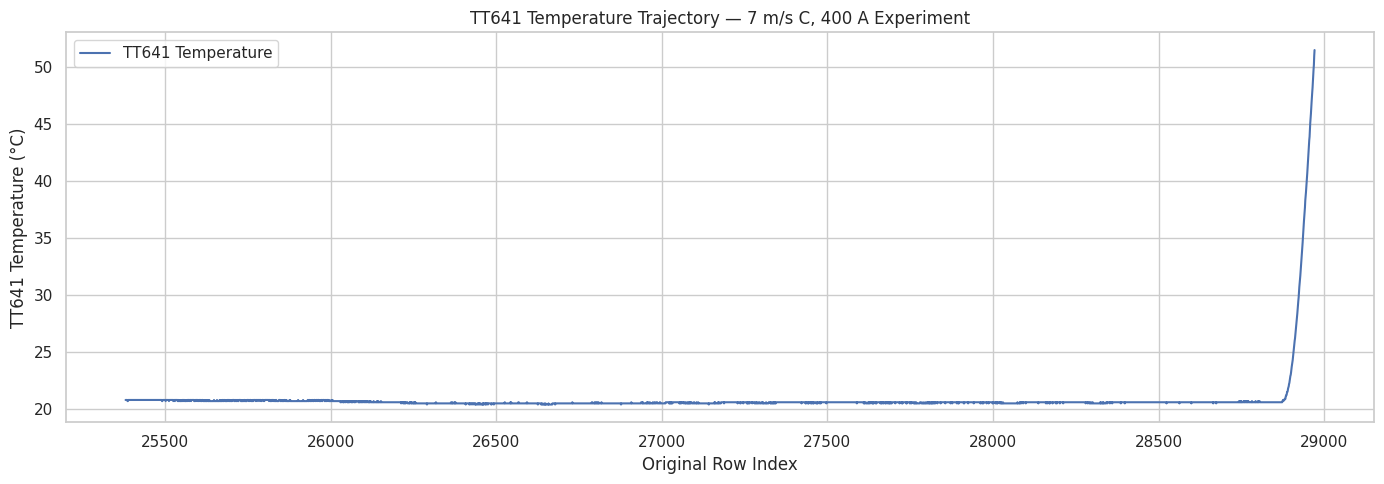

Temperature summary:


,TT641 Temperature
count,3591.000
mean,20.905
std,2.428
min,20.400
25%,20.500
50%,20.600
75%,20.600
max,51.500


In [ ]:
# Stage 3: TT641 temperature trajectory in the selected experiment

import matplotlib.pyplot as plt

target_experiment = "windIEA3.4-7ms-C_1-400.csv"

experiment_data = (
    df_nlr_clean[
        df_nlr_clean["Experiment"] == target_experiment
    ]
    .sort_values("Original_Row_Index")
    .copy()
)

plt.figure(figsize=(14, 5))

plt.plot(
    experiment_data["Original_Row_Index"],
    experiment_data["H2E_f_TT641_Temp"],
    label="TT641 Temperature"
)

plt.xlabel("Original Row Index")
plt.ylabel("TT641 Temperature (°C)")
plt.title("TT641 Temperature Trajectory — 7 m/s C, 400 A Experiment")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Temperature summary:")
display(
    experiment_data["H2E_f_TT641_Temp"]
    .describe()
    .to_frame("TT641 Temperature")
    .round(3)
)

In [ ]:
# Stage 4: Candidate target suitability assessment

candidate_targets = [
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current",
    "Wind Turbine Power (kW)"
]

target_report = []

for col in candidate_targets:

    values = df_nlr_clean[col].dropna()

    target_report.append({
        "Candidate_Target": col,
        "Valid_Count": values.count(),
        "Missing_Count": df_nlr_clean[col].isna().sum(),
        "Unique_Values": values.nunique(),
        "Minimum": values.min(),
        "Median": values.median(),
        "Mean": values.mean(),
        "Maximum": values.max(),
        "Experiments_Available": (
            df_nlr_clean.loc[
                df_nlr_clean[col].notna(), "Experiment"
            ].nunique()
        )
    })

target_report = pd.DataFrame(target_report)

display(target_report.round(4))

,Candidate_Target,Valid_Count,Missing_Count,Unique_Values,Minimum,Median,Mean,Maximum,Experiments_Available
0,IVAL_f_FM011_Flow,61081,0,19725,0.0050,12.8990,12.6732,33.339,13
1,H2E_f_Elec_CalcProdRate,61081,0,15447,1.1190,13.2050,12.9138,22.380,13
2,Efficiency (kWh/kg),61080,1,53242,21.1131,51.6598,115.9848,40400.000,13
3,H2E_n_PSU_A_Power,61081,0,1165,97.0000,668.0000,668.2082,1261.000,13
4,Power Supply Average Voltage (Vdc),61081,0,2090,320.3670,371.1000,369.1064,410.200,13
5,H2E_f_PSU_A_Current,61081,0,2678,295.0000,1770.0000,1730.9989,3003.000,13
6,Wind Turbine Power (kW),43253,17828,17503,20.5600,657.4000,668.2678,1629.800,12


In [ ]:
# Stage 4: Target relationship and correlation assessment

target_relationships = [
    ("IVAL_f_FM011_Flow", "H2E_f_Elec_CalcProdRate"),
    ("H2E_n_PSU_A_Power", "Power Supply Average Voltage (Vdc)"),
    ("H2E_n_PSU_A_Power", "H2E_f_PSU_A_Current"),
    ("Power Supply Average Voltage (Vdc)", "H2E_f_PSU_A_Current"),
    ("IVAL_f_FM011_Flow", "Efficiency (kWh/kg)")
]

# Overall Pearson and Spearman correlations
overall_correlations = []

for col1, col2 in target_relationships:

    pair = df_nlr_clean[[col1, col2]].dropna()

    overall_correlations.append({
        "Variable_1": col1,
        "Variable_2": col2,
        "Valid_Pairs": len(pair),
        "Pearson_Correlation": pair[col1].corr(
            pair[col2], method="pearson"
        ),
        "Spearman_Correlation": pair[col1].corr(
            pair[col2], method="spearman"
        )
    })

print("OVERALL TARGET RELATIONSHIPS")
display(pd.DataFrame(overall_correlations).round(4))


# Relationship between measured and calculated production
production_by_experiment = []

for experiment, group in df_nlr_clean.groupby("Experiment"):

    pair = group[
        [
            "IVAL_f_FM011_Flow",
            "H2E_f_Elec_CalcProdRate"
        ]
    ].dropna()

    production_by_experiment.append({
        "Experiment": experiment,
        "Valid_Pairs": len(pair),
        "Pearson_Correlation": pair[
            "IVAL_f_FM011_Flow"
        ].corr(pair["H2E_f_Elec_CalcProdRate"]),
        "Spearman_Correlation": pair[
            "IVAL_f_FM011_Flow"
        ].corr(
            pair["H2E_f_Elec_CalcProdRate"],
            method="spearman"
        )
    })

print("\nMEASURED VS CALCULATED PRODUCTION BY EXPERIMENT")
display(
    pd.DataFrame(production_by_experiment).round(4)
)

OVERALL TARGET RELATIONSHIPS


,Variable_1,Variable_2,Valid_Pairs,Pearson_Correlation,Spearman_Correlation
0,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,61081,0.9676,0.9697
1,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),61081,0.9953,0.9990
2,H2E_n_PSU_A_Power,H2E_f_PSU_A_Current,61081,0.9982,0.9997
3,Power Supply Average Voltage (Vdc),H2E_f_PSU_A_Current,61081,0.9988,0.9988
4,IVAL_f_FM011_Flow,Efficiency (kWh/kg),61080,-0.1449,0.2383



MEASURED VS CALCULATED PRODUCTION BY EXPERIMENT


,Experiment,Valid_Pairs,Pearson_Correlation,Spearman_Correlation
0,characterization_200.csv,17828,0.9976,0.9938
1,windIEA3.4-5ms-A_2-200.csv,3652,0.9598,0.9592
2,windIEA3.4-5ms-A_2-400.csv,3652,0.9599,0.9587
3,windIEA3.4-5ms-C_2-200.csv,3652,0.9525,0.9505
4,windIEA3.4-5ms-C_2-400.csv,3652,0.9546,0.9542
5,windIEA3.4-7ms-A_1-200.csv,3591,0.9401,0.9427
6,windIEA3.4-7ms-A_1-400.csv,3591,0.9398,0.9425
7,windIEA3.4-7ms-C_1-200.csv,3591,0.9329,0.9339
8,windIEA3.4-7ms-C_1-400.csv,3591,0.9248,0.9329
9,windIEA3.4-9ms-A_1-200.csv,3591,0.9184,0.9075


In [ ]:
# Stage 4: Candidate feature relationship with measured hydrogen flow

target = "IVAL_f_FM011_Flow"

excluded_columns = [
    "Unnamed: 0",
    "Unnamed: 31",
    "Experiment",
    "Original_Row_Index",
    "Flow_Was_Interpolated",
    "Extreme_Efficiency_Flag",
    "Calculated_PSU_Power_W",
    "Power_Difference_W",
    "Power_Relative_Error_Percent",
    "Calculated_PSU_Power_kW",
    "Power_Difference_kW",
    "Power_Relative_Error_kW_Percent",
    target
]

candidate_features = [
    col for col in df_nlr_clean.select_dtypes(include="number").columns
    if col not in excluded_columns
]

feature_relationships = []

for col in candidate_features:

    pair = df_nlr_clean[[col, target]].dropna()

    feature_relationships.append({
        "Feature": col,
        "Valid_Pairs": len(pair),
        "Pearson_Correlation": pair[col].corr(
            pair[target], method="pearson"
        ),
        "Spearman_Correlation": pair[col].corr(
            pair[target], method="spearman"
        )
    })

feature_relationship_report = pd.DataFrame(feature_relationships)

feature_relationship_report["Absolute_Spearman"] = (
    feature_relationship_report["Spearman_Correlation"].abs()
)

display(
    feature_relationship_report
    .sort_values("Absolute_Spearman", ascending=False)
    .drop(columns="Absolute_Spearman")
    .round(4)
)

,Feature,Valid_Pairs,Pearson_Correlation,Spearman_Correlation
6,H2E_f_PSU_A_Current,61081,0.9705,0.9725
5,H2E_n_PSU_A_Power,61081,0.9686,0.9720
3,Power Supply Average Voltage (Vdc),61081,0.9672,0.9699
7,H2E_f_Elec_CalcProdRate,61081,0.9676,0.9697
4,H2E_f_NLR_CurrentCmd,61081,0.9622,0.9643
1,H2E_f_NLR_CurrentCmd (A),61081,0.9622,0.9643
0,Wind Turbine Power (kW),43253,0.9288,0.9353
14,H2E_f_PT264_Pressure,61081,0.7729,0.8201
20,H2E_f_TE218_Temp,61081,-0.5957,-0.5936
17,H2E_f_PT604_Pressure,61081,-0.4371,-0.4316


In [ ]:
# Stage 4: Within-experiment feature suitability

target = "IVAL_f_FM011_Flow"

features_to_check = [
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd",
    "H2E_f_NLR_CurrentCmd (A)",
    "Wind Turbine Power (kW)",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_PT604_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_TT645_Temp"
]

within_experiment_results = []

for experiment, group in df_nlr_clean.groupby("Experiment"):

    for feature in features_to_check:

        pair = group[[feature, target]].dropna()

        within_experiment_results.append({
            "Experiment": experiment,
            "Feature": feature,
            "Valid_Pairs": len(pair),
            "Pearson": pair[feature].corr(
                pair[target], method="pearson"
            ),
            "Spearman": pair[feature].corr(
                pair[target], method="spearman"
            )
        })

within_experiment_report = pd.DataFrame(
    within_experiment_results
)

display(
    within_experiment_report
    .pivot(
        index="Experiment",
        columns="Feature",
        values="Spearman"
    )
    .round(3)
)

Feature,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT604_Pressure,H2E_f_TE218_Temp,H2E_f_TT645_Temp,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),Wind Turbine Power (kW)
Experiment,,,,,,,,,,,
characterization_200.csv,0.994,0.994,0.990,0.978,0.007,-0.958,-0.915,0.873,0.990,0.989,NaN
windIEA3.4-5ms-A_2-200.csv,0.955,0.955,0.963,0.923,0.452,-0.150,-0.322,0.158,0.962,0.959,0.962
windIEA3.4-5ms-A_2-400.csv,0.955,0.955,0.961,0.938,0.454,-0.162,-0.317,-0.163,0.961,0.958,0.965
windIEA3.4-5ms-C_2-200.csv,0.946,0.946,0.953,0.872,0.441,-0.057,-0.303,0.312,0.952,0.948,0.948
windIEA3.4-5ms-C_2-400.csv,0.951,0.951,0.957,0.927,0.543,-0.156,-0.184,-0.257,0.957,0.954,0.962
windIEA3.4-7ms-A_1-200.csv,0.928,0.928,0.947,0.937,0.567,0.089,-0.285,0.288,0.946,0.943,0.932
windIEA3.4-7ms-A_1-400.csv,0.933,0.933,0.949,0.943,0.558,-0.083,-0.121,0.175,0.948,0.944,0.936
windIEA3.4-7ms-C_1-200.csv,0.921,0.921,0.940,0.914,0.590,0.032,-0.188,0.264,0.939,0.934,0.925
windIEA3.4-7ms-C_1-400.csv,0.924,0.924,0.939,0.955,0.576,0.067,-0.219,-0.298,0.938,0.933,0.934


In [ ]:
# Stage 4: Feature redundancy assessment within experiments

features_for_redundancy = [
    "H2E_f_NLR_CurrentCmd",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure",
    "Wind Turbine Power (kW)"
]

for experiment, group in df_nlr_clean.groupby("Experiment"):

    print("\n" + "=" * 80)
    print("EXPERIMENT:", experiment)
    print("=" * 80)

    correlation_matrix = group[
        features_for_redundancy
    ].corr(method="spearman")

    display(correlation_matrix.round(3))


EXPERIMENT: characterization_200.csv


,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,Wind Turbine Power (kW)
H2E_f_NLR_CurrentCmd,1.000,1.000,0.994,0.995,0.994,0.982,NaN
H2E_f_NLR_CurrentCmd (A),1.000,1.000,0.994,0.995,0.994,0.982,NaN
H2E_f_PSU_A_Current,0.994,0.994,1.000,0.993,0.990,0.978,NaN
H2E_n_PSU_A_Power,0.995,0.995,0.993,1.000,0.995,0.979,NaN
Power Supply Average Voltage (Vdc),0.994,0.994,0.990,0.995,1.000,0.978,NaN
H2E_f_PT264_Pressure,0.982,0.982,0.978,0.979,0.978,1.000,NaN
Wind Turbine Power (kW),NaN,NaN,NaN,NaN,NaN,NaN,NaN



EXPERIMENT: windIEA3.4-5ms-A_2-200.csv


,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,Wind Turbine Power (kW)
H2E_f_NLR_CurrentCmd,1.000,1.000,0.997,0.998,0.997,0.947,0.998
H2E_f_NLR_CurrentCmd (A),1.000,1.000,0.997,0.998,0.997,0.947,0.998
H2E_f_PSU_A_Current,0.997,0.997,1.000,1.000,0.999,0.950,0.999
H2E_n_PSU_A_Power,0.998,0.998,1.000,1.000,0.999,0.950,0.999
Power Supply Average Voltage (Vdc),0.997,0.997,0.999,0.999,1.000,0.949,0.998
H2E_f_PT264_Pressure,0.947,0.947,0.950,0.950,0.949,1.000,0.950
Wind Turbine Power (kW),0.998,0.998,0.999,0.999,0.998,0.950,1.000



EXPERIMENT: windIEA3.4-5ms-A_2-400.csv


,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,Wind Turbine Power (kW)
H2E_f_NLR_CurrentCmd,1.000,1.000,0.996,0.996,0.996,0.960,0.997
H2E_f_NLR_CurrentCmd (A),1.000,1.000,0.996,0.996,0.996,0.960,0.997
H2E_f_PSU_A_Current,0.996,0.996,1.000,1.000,0.999,0.962,0.998
H2E_n_PSU_A_Power,0.996,0.996,1.000,1.000,0.999,0.962,0.998
Power Supply Average Voltage (Vdc),0.996,0.996,0.999,0.999,1.000,0.961,0.997
H2E_f_PT264_Pressure,0.960,0.960,0.962,0.962,0.961,1.000,0.963
Wind Turbine Power (kW),0.997,0.997,0.998,0.998,0.997,0.963,1.000


... (16 outputs left out)


EXPERIMENT: windIEA3.4-9ms-C_1-200.csv


,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,Wind Turbine Power (kW)
H2E_f_NLR_CurrentCmd,1.000,1.000,0.986,0.986,0.981,0.971,0.996
H2E_f_NLR_CurrentCmd (A),1.000,1.000,0.986,0.986,0.981,0.971,0.996
H2E_f_PSU_A_Current,0.986,0.986,1.000,1.000,0.996,0.992,0.990
H2E_n_PSU_A_Power,0.986,0.986,1.000,1.000,0.997,0.991,0.990
Power Supply Average Voltage (Vdc),0.981,0.981,0.996,0.997,1.000,0.985,0.986
H2E_f_PT264_Pressure,0.971,0.971,0.992,0.991,0.985,1.000,0.980
Wind Turbine Power (kW),0.996,0.996,0.990,0.990,0.986,0.980,1.000



EXPERIMENT: windIEA3.4-9ms-C_1-400.csv


,H2E_f_NLR_CurrentCmd,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_PT264_Pressure,Wind Turbine Power (kW)
H2E_f_NLR_CurrentCmd,1.000,1.000,0.990,0.990,0.987,0.977,0.989
H2E_f_NLR_CurrentCmd (A),1.000,1.000,0.990,0.990,0.987,0.977,0.989
H2E_f_PSU_A_Current,0.990,0.990,1.000,1.000,0.996,0.992,0.995
H2E_n_PSU_A_Power,0.990,0.990,1.000,1.000,0.997,0.991,0.995
Power Supply Average Voltage (Vdc),0.987,0.987,0.996,0.997,1.000,0.986,0.991
H2E_f_PT264_Pressure,0.977,0.977,0.992,0.991,0.986,1.000,0.993
Wind Turbine Power (kW),0.989,0.989,0.995,0.995,0.991,0.993,1.000


In [ ]:
# STAGE 4 — TARGET LEAKAGE AND FEATURE AVAILABILITY AUDIT

primary_target = "IVAL_f_FM011_Flow"

candidate_columns = [
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PSU_A_Current",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_NLR_CurrentCmd",
    "Wind Turbine Power (kW)",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT312_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TE219_Temp",
    "H2E_f_TE338_Temp",
    "H2E_f_TE601_Temp",
    "H2E_f_TT641_Temp",
    "H2E_f_TT645_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT647_Temp",
    "Experiment",
    "Parsed_Timestamp"
]

audit_rows = []

for col in candidate_columns:
    if col not in df_nlr_clean.columns:
        continue

    audit_rows.append({
        "Feature": col,
        "Available_Count": df_nlr_clean[col].notna().sum(),
        "Missing_Count": df_nlr_clean[col].isna().sum(),
        "Unique_Experiments": (
            df_nlr_clean.loc[
                df_nlr_clean[col].notna(), "Experiment"
            ].nunique()
        ),
        "Correlation_With_Flow_Pearson": (
            df_nlr_clean[[primary_target, col]]
            .corr(method="pearson")
            .iloc[0, 1]
            if col != "Experiment"
            and col != "Parsed_Timestamp"
            else None
        )
    })

feature_availability_audit = pd.DataFrame(audit_rows)

display(
    feature_availability_audit.round(4)
)

,Feature,Available_Count,Missing_Count,Unique_Experiments,Correlation_With_Flow_Pearson
0,H2E_f_Elec_CalcProdRate,61081,0,13,0.9676
1,Efficiency (kWh/kg),61080,1,13,-0.1449
2,H2E_n_PSU_A_Power,61081,0,13,0.9686
3,Power Supply Average Voltage (Vdc),61081,0,13,0.9672
4,H2E_f_PSU_A_Current,61081,0,13,0.9705
5,H2E_f_NLR_CurrentCmd (A),61081,0,13,0.9622
6,H2E_f_NLR_CurrentCmd,61081,0,13,0.9622
7,Wind Turbine Power (kW),43253,17828,12,0.9288
8,H2E_f_PT264_Pressure,61081,0,13,0.7729
9,H2E_f_PT307_Pressure,61081,0,13,0.4190


In [ ]:
# STAGE 4 — TARGET SUITABILITY
# Compare target relationships within each experiment

target_column = "IVAL_f_FM011_Flow"

target_features = [
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TT645_Temp"
]

experiment_target_report = []

for experiment, group in df_nlr_clean.groupby("Experiment"):

    for feature in target_features:

        # Extract individual columns as Series
        target_series = group[target_column].squeeze()
        feature_series = group[feature].squeeze()

        valid = pd.concat(
            [target_series, feature_series],
            axis=1
        ).dropna()

        if len(valid) < 3:
            pearson = float("nan")
            spearman = float("nan")
        else:
            pearson = pd.Series.corr(
                valid.iloc[:, 0],
                valid.iloc[:, 1],
                method="pearson"
            )

            spearman = pd.Series.corr(
                valid.iloc[:, 0],
                valid.iloc[:, 1],
                method="spearman"
            )

        experiment_target_report.append({
            "Experiment": experiment,
            "Feature": feature,
            "Valid_Pairs": len(valid),
            "Pearson": pearson,
            "Spearman": spearman
        })

experiment_target_report = pd.DataFrame(experiment_target_report)

display(experiment_target_report.round(4))

,Experiment,Feature,Valid_Pairs,Pearson,Spearman
0,characterization_200.csv,H2E_f_Elec_CalcProdRate,17828,0.9976,0.9938
1,characterization_200.csv,H2E_f_PSU_A_Current,17828,0.9984,0.9902
2,characterization_200.csv,H2E_n_PSU_A_Power,17828,0.9964,0.9898
3,characterization_200.csv,Power Supply Average Voltage (Vdc),17828,0.9978,0.9889
4,characterization_200.csv,H2E_f_NLR_CurrentCmd (A),17828,0.9979,0.9941
...,...,...,...,...,...
125,windIEA3.4-9ms-C_1-400.csv,H2E_f_PT264_Pressure,3591,0.9027,0.9044
126,windIEA3.4-9ms-C_1-400.csv,H2E_f_PT307_Pressure,3591,0.6424,0.5912
127,windIEA3.4-9ms-C_1-400.csv,H2E_f_PT604_Pressure,3591,0.1252,0.1191
128,windIEA3.4-9ms-C_1-400.csv,H2E_f_TE218_Temp,3591,-0.1372,-0.1277


In [ ]:
# STAGE 4 — FEATURE CONSISTENCY ACROSS EXPERIMENTS

feature_consistency = (
    experiment_target_report
    .groupby("Feature")
    .agg(
        Experiments_Compared=("Experiment", "nunique"),
        Mean_Pearson=("Pearson", "mean"),
        Std_Pearson=("Pearson", "std"),
        Min_Pearson=("Pearson", "min"),
        Max_Pearson=("Pearson", "max"),
        Mean_Spearman=("Spearman", "mean"),
        Std_Spearman=("Spearman", "std"),
        Min_Spearman=("Spearman", "min"),
        Max_Spearman=("Spearman", "max")
    )
    .sort_values("Mean_Spearman", ascending=False)
)

display(feature_consistency.round(4))

,Experiments_Compared,Mean_Pearson,Std_Pearson,Min_Pearson,Max_Pearson,Mean_Spearman,Std_Spearman,Min_Spearman,Max_Spearman
Feature,,,,,,,,,
H2E_f_PSU_A_Current,13,0.9442,0.0266,0.8829,0.9984,0.9432,0.0259,0.8813,0.9902
H2E_n_PSU_A_Power,13,0.9428,0.0267,0.8805,0.9964,0.9423,0.0262,0.8798,0.9898
H2E_f_Elec_CalcProdRate,13,0.9390,0.0291,0.8723,0.9976,0.9384,0.0289,0.8723,0.9938
Power Supply Average Voltage (Vdc),13,0.9391,0.0276,0.8778,0.9978,0.9376,0.0280,0.8747,0.9889
H2E_f_PT264_Pressure,13,0.9356,0.0241,0.8925,0.9883,0.9334,0.0267,0.8715,0.9782
H2E_f_NLR_CurrentCmd (A),13,0.9274,0.0362,0.8554,0.9979,0.9284,0.0345,0.8603,0.9941
H2E_f_PT307_Pressure,13,0.5464,0.1700,0.0145,0.6571,0.4962,0.1560,0.0072,0.5912
H2E_f_TT645_Temp,13,0.1273,0.3110,-0.2740,0.8968,0.1358,0.3143,-0.2980,0.8726
H2E_f_PT604_Pressure,13,-0.0880,0.2694,-0.9504,0.1252,-0.1131,0.2719,-0.9583,0.1191


In [ ]:
# STAGE 4 — FEATURE REDUNDANCY ANALYSIS
# Calculate predictor-to-predictor correlations

redundancy_features = [
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TT645_Temp"
]

redundancy_data = df_nlr_clean[redundancy_features].copy()

pearson_redundancy = redundancy_data.corr(method="pearson")
spearman_redundancy = redundancy_data.corr(method="spearman")

print("PEARSON FEATURE CORRELATION")
display(pearson_redundancy.round(3))

print("SPEARMAN FEATURE CORRELATION")
display(spearman_redundancy.round(3))

PEARSON FEATURE CORRELATION


,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd (A),H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT604_Pressure,H2E_f_TE218_Temp,H2E_f_TT645_Temp
H2E_f_Elec_CalcProdRate,1.000,0.999,0.998,0.998,0.998,0.799,0.363,-0.507,-0.637,0.163
H2E_f_PSU_A_Current,0.999,1.000,0.998,0.999,0.997,0.799,0.363,-0.507,-0.637,0.163
H2E_n_PSU_A_Power,0.998,0.998,1.000,0.995,0.995,0.802,0.360,-0.507,-0.643,0.159
Power Supply Average Voltage (Vdc),0.998,0.999,0.995,1.000,0.996,0.799,0.355,-0.525,-0.654,0.170
H2E_f_NLR_CurrentCmd (A),0.998,0.997,0.995,0.996,1.000,0.798,0.361,-0.507,-0.638,0.164
H2E_f_PT264_Pressure,0.799,0.799,0.802,0.799,0.798,1.000,0.214,-0.453,-0.556,0.251
H2E_f_PT307_Pressure,0.363,0.363,0.360,0.355,0.361,0.214,1.000,0.234,-0.074,-0.022
H2E_f_PT604_Pressure,-0.507,-0.507,-0.507,-0.525,-0.507,-0.453,0.234,1.000,0.537,-0.133
H2E_f_TE218_Temp,-0.637,-0.637,-0.643,-0.654,-0.638,-0.556,-0.074,0.537,1.000,-0.134
H2E_f_TT645_Temp,0.163,0.163,0.159,0.170,0.164,0.251,-0.022,-0.133,-0.134,1.000


SPEARMAN FEATURE CORRELATION


,H2E_f_Elec_CalcProdRate,H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd (A),H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT604_Pressure,H2E_f_TE218_Temp,H2E_f_TT645_Temp
H2E_f_Elec_CalcProdRate,1.000,0.999,0.999,0.998,0.998,0.844,0.318,-0.490,-0.630,0.360
H2E_f_PSU_A_Current,0.999,1.000,1.000,0.999,0.997,0.845,0.318,-0.490,-0.630,0.360
H2E_n_PSU_A_Power,0.999,1.000,1.000,0.999,0.997,0.845,0.316,-0.494,-0.633,0.361
Power Supply Average Voltage (Vdc),0.998,0.999,0.999,1.000,0.996,0.847,0.310,-0.506,-0.650,0.367
H2E_f_NLR_CurrentCmd (A),0.998,0.997,0.997,0.996,1.000,0.844,0.317,-0.490,-0.631,0.361
H2E_f_PT264_Pressure,0.844,0.845,0.845,0.847,0.844,1.000,0.207,-0.505,-0.605,0.339
H2E_f_PT307_Pressure,0.318,0.318,0.316,0.310,0.317,0.207,1.000,0.216,-0.056,-0.016
H2E_f_PT604_Pressure,-0.490,-0.490,-0.494,-0.506,-0.490,-0.505,0.216,1.000,0.522,-0.339
H2E_f_TE218_Temp,-0.630,-0.630,-0.633,-0.650,-0.631,-0.605,-0.056,0.522,1.000,-0.347
H2E_f_TT645_Temp,0.360,0.360,0.361,0.367,0.361,0.339,-0.016,-0.339,-0.347,1.000


In [ ]:
# STAGE 4 — ELECTRICAL FEATURE REDUNDANCY
# Examine relationships between PSU current, voltage, power and current command

electrical_features = [
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_NLR_CurrentCmd (A)"
]

electrical_data = df_nlr_clean[electrical_features].dropna()

# Fit a simple linear relationship between each pair
from itertools import combinations

electrical_relationships = []

for feature_a, feature_b in combinations(electrical_features, 2):

    x = electrical_data[feature_a]
    y = electrical_data[feature_b]

    slope, intercept = np.polyfit(x, y, 1)
    predicted_y = slope * x + intercept

    residuals = y - predicted_y

    electrical_relationships.append({
        "Feature_A": feature_a,
        "Feature_B": feature_b,
        "Pearson": x.corr(y),
        "Slope": slope,
        "Intercept": intercept,
        "R_squared": 1 - (
            (residuals ** 2).sum() /
            ((y - y.mean()) ** 2).sum()
        ),
        "Residual_Std": residuals.std()
    })

electrical_relationships = pd.DataFrame(electrical_relationships)

display(electrical_relationships.round(6))

,Feature_A,Feature_B,Pearson,Slope,Intercept,R_squared,Residual_Std
0,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),0.998755,0.031510,314.563259,0.997511,1.160778
1,H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,0.998200,0.431482,-78.686252,0.996402,19.122104
2,H2E_f_PSU_A_Current,H2E_f_NLR_CurrentCmd (A),0.997088,0.998169,5.373828,0.994184,56.307236
3,Power Supply Average Voltage (Vdc),H2E_n_PSU_A_Power,0.995251,13.636207,-4365.002351,0.990524,31.033349
4,Power Supply Average Voltage (Vdc),H2E_f_NLR_CurrentCmd (A),0.996045,31.605712,-9932.665974,0.992106,65.600848
5,H2E_n_PSU_A_Power,H2E_f_NLR_CurrentCmd (A),0.995329,2.305113,192.907800,0.990680,71.279989


In [ ]:
# STAGE 4 — FEATURE AND TARGET ROLE REGISTER

feature_roles = {
    "Real_Time_State_Estimation": {
        "Primary_Target": [
            "IVAL_f_FM011_Flow"
        ],
        "Candidate_Inputs": [
            "Wind Turbine Power (kW)",
            "H2E_f_NLR_CurrentCmd (A)",
            "H2E_f_NLR_CurrentCmd",
            "H2E_f_PSU_A_Current",
            "H2E_n_PSU_A_Power",
            "Power Supply Average Voltage (Vdc)",
            "H2E_f_CG220_LFLPer",
            "H2E_f_DPS340_DPdegC",
            "H2E_f_DPS341_DPdegC",
            "H2E_f_DPS341_DPppmV",
            "H2E_f_LS201_H2OLevel",
            "H2E_f_LS301_H2OLevel",
            "H2E_f_PT264_Pressure",
            "H2E_f_PT307_Pressure",
            "H2E_f_PT312_Pressure",
            "H2E_f_PT604_Pressure",
            "H2E_f_RS209_Resistivity",
            "H2E_f_RS507_Resistivity",
            "H2E_f_TE218_Temp",
            "H2E_f_TE219_Temp",
            "H2E_f_TE338_Temp",
            "H2E_f_TE601_Temp",
            "H2E_f_TT641_Temp",
            "H2E_f_TT645_Temp",
            "H2E_f_TT646_Temp",
            "H2E_f_TT647_Temp"
        ],
        "Leakage_Sensitive": [
            "H2E_f_Elec_CalcProdRate",
            "Efficiency (kWh/kg)"
        ]
    },

    "Future_Flow_Forecasting": {
        "Future_Target": [
            "IVAL_f_FM011_Flow"
        ],
        "Historical_Input_Candidates": [
            "IVAL_f_FM011_Flow",
            "Wind Turbine Power (kW)",
            "H2E_f_NLR_CurrentCmd (A)",
            "H2E_f_NLR_CurrentCmd",
            "H2E_f_PSU_A_Current",
            "H2E_n_PSU_A_Power",
            "Power Supply Average Voltage (Vdc)",
            "H2E_f_CG220_LFLPer",
            "H2E_f_DPS340_DPdegC",
            "H2E_f_DPS341_DPdegC",
            "H2E_f_DPS341_DPppmV",
            "H2E_f_LS201_H2OLevel",
            "H2E_f_LS301_H2OLevel",
            "H2E_f_PT264_Pressure",
            "H2E_f_PT307_Pressure",
            "H2E_f_PT312_Pressure",
            "H2E_f_PT604_Pressure",
            "H2E_f_RS209_Resistivity",
            "H2E_f_RS507_Resistivity",
            "H2E_f_TE218_Temp",
            "H2E_f_TE219_Temp",
            "H2E_f_TE338_Temp",
            "H2E_f_TE601_Temp",
            "H2E_f_TT641_Temp",
            "H2E_f_TT645_Temp",
            "H2E_f_TT646_Temp",
            "H2E_f_TT647_Temp"
        ],
        "Leakage_Sensitive": [
            "H2E_f_Elec_CalcProdRate",
            "Efficiency (kWh/kg)"
        ]
    }
}

available_columns = set(df_nlr_clean.columns)

for objective, groups in feature_roles.items():

    print("\n", "=" * 65)
    print(objective)

    for role, columns in groups.items():

        available = [c for c in columns if c in available_columns]
        missing = [c for c in columns if c not in available_columns]

        print(f"\n{role}")
        print("Available:", len(available))
        print("Missing:", missing)

print("\nExperiment and timestamp are reserved for validation and ordering.")
print("Original dataset remains unchanged.")


Real_Time_State_Estimation

Primary_Target
Available: 1
Missing: []

Candidate_Inputs
Available: 26
Missing: []

Leakage_Sensitive
Available: 2
Missing: []

Future_Flow_Forecasting

Future_Target
Available: 1
Missing: []

Historical_Input_Candidates
Available: 27
Missing: []

Leakage_Sensitive
Available: 2
Missing: []

Experiment and timestamp are reserved for validation and ordering.
Original dataset remains unchanged.


In [ ]:
# STAGE 4 — TEMPORAL RESOLUTION CHECK
# Inspect observations per minute within each experiment

temporal_check = df_nlr_clean.copy()

temporal_check["Minute"] = (
    temporal_check["Parsed_Timestamp"].dt.floor("min")
)

minute_counts = (
    temporal_check
    .groupby(["Experiment", "Minute"])
    .size()
    .reset_index(name="Observations_Per_Minute")
)

print("OBSERVATIONS PER MINUTE — OVERALL")
display(
    minute_counts["Observations_Per_Minute"]
    .describe()
    .to_frame("Statistics")
    .round(2)
)

print("\nOBSERVATIONS PER MINUTE — BY EXPERIMENT")

experiment_sampling = (
    minute_counts
    .groupby("Experiment")["Observations_Per_Minute"]
    .agg(
        Minute_Groups="count",
        Mean_Observations="mean",
        Median_Observations="median",
        Minimum="min",
        Maximum="max"
    )
)

display(experiment_sampling.round(2))

print("\nTIMESTAMP PRECISION:")
print("Available timestamp precision: minute-level")
print("Exact within-minute sampling interval: not established")

OBSERVATIONS PER MINUTE — OVERALL


,Statistics
count,1034.00
mean,59.07
std,5.30
min,6.00
25%,60.00
50%,60.00
75%,60.00
max,60.00



OBSERVATIONS PER MINUTE — BY EXPERIMENT


,Minute_Groups,Mean_Observations,Median_Observations,Minimum,Maximum
Experiment,,,,,
characterization_200.csv,301,59.23,60.0,28,60
windIEA3.4-5ms-A_2-200.csv,62,58.90,60.0,25,60
windIEA3.4-5ms-A_2-400.csv,62,58.90,60.0,24,60
windIEA3.4-5ms-C_2-200.csv,62,58.90,60.0,12,60
windIEA3.4-5ms-C_2-400.csv,62,58.90,60.0,7,60
windIEA3.4-7ms-A_1-200.csv,61,58.87,60.0,20,60
windIEA3.4-7ms-A_1-400.csv,60,59.85,60.0,52,60
windIEA3.4-7ms-C_1-200.csv,61,58.87,60.0,7,60
windIEA3.4-7ms-C_1-400.csv,61,58.87,60.0,16,60



TIMESTAMP PRECISION:
Available timestamp precision: minute-level
Exact within-minute sampling interval: not established


In [ ]:
# STAGE 4 — MINUTE-LEVEL AGGREGATION QUALITY
# Compare original observations with minute-level means

aggregation_columns = [
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TT645_Temp"
]

aggregation_work = df_nlr_clean.copy()

aggregation_work["Minute"] = (
    aggregation_work["Parsed_Timestamp"].dt.floor("min")
)

minute_aggregated = (
    aggregation_work
    .groupby(["Experiment", "Minute"])[aggregation_columns]
    .agg(["mean", "std", "min", "max"])
)

print("Original observation count:", len(df_nlr_clean))
print("Minute-level group count:", len(minute_aggregated))

print("\nWITHIN-MINUTE VARIABILITY")
display(
    minute_aggregated.xs("std", axis=1, level=1)
    .describe()
    .T
    .round(4)
)

Original observation count: 61081
Minute-level group count: 1034

WITHIN-MINUTE VARIABILITY


,count,mean,std,min,25%,50%,75%,max
IVAL_f_FM011_Flow,1034.0,1.5900,1.5093,0.0590,0.1994,1.2065,2.3981,9.6766
H2E_f_Elec_CalcProdRate,1034.0,1.2896,1.2577,0.0000,0.0000,1.0499,2.0350,7.4470
H2E_f_PSU_A_Current,1034.0,173.1340,167.7241,0.5017,1.3902,140.2204,268.7236,826.3260
H2E_n_PSU_A_Power,1034.0,75.6602,73.9419,0.1291,0.8988,61.9858,118.0323,361.4528
Power Supply Average Voltage (Vdc),1034.0,5.4038,5.0293,0.1016,0.5415,4.2344,8.3375,25.3480
H2E_f_NLR_CurrentCmd (A),1034.0,170.2258,164.3524,0.0000,0.0000,139.5953,268.7035,836.7224
H2E_f_PT264_Pressure,1034.0,0.0206,0.0190,0.0008,0.0028,0.0158,0.0308,0.0916
H2E_f_PT307_Pressure,1034.0,0.2096,0.1935,0.0008,0.0559,0.1564,0.3034,1.0940
H2E_f_PT604_Pressure,1034.0,0.0185,0.0186,0.0010,0.0037,0.0126,0.0265,0.1041
H2E_f_TE218_Temp,1034.0,0.1817,0.1252,0.0000,0.1084,0.1482,0.2367,0.9046


In [ ]:
# STAGE 4 — MINUTE-TO-MINUTE FLOW DYNAMICS

flow_minute = (
    aggregation_work
    .groupby(["Experiment", "Minute"])
    .agg(
        Mean_Flow=("IVAL_f_FM011_Flow", "mean"),
        Median_Flow=("IVAL_f_FM011_Flow", "median"),
        Min_Flow=("IVAL_f_FM011_Flow", "min"),
        Max_Flow=("IVAL_f_FM011_Flow", "max")
    )
    .reset_index()
)

flow_minute = flow_minute.sort_values(
    ["Experiment", "Minute"]
)

flow_minute["Previous_Minute_Flow"] = (
    flow_minute.groupby("Experiment")["Mean_Flow"].shift(1)
)

flow_minute["Flow_Change"] = (
    flow_minute["Mean_Flow"] -
    flow_minute["Previous_Minute_Flow"]
)

flow_minute["Absolute_Flow_Change"] = (
    flow_minute["Flow_Change"].abs()
)

flow_minute["Percentage_Flow_Change"] = (
    flow_minute["Flow_Change"] /
    flow_minute["Previous_Minute_Flow"].replace(0, np.nan)
) * 100

print("MINUTE-TO-MINUTE FLOW CHANGE")
display(
    flow_minute[
        ["Flow_Change", "Absolute_Flow_Change",
         "Percentage_Flow_Change"]
    ].describe().round(4)
)

print("\nFLOW DYNAMICS BY EXPERIMENT")

flow_dynamics_by_experiment = (
    flow_minute
    .groupby("Experiment")
    .agg(
        Mean_Absolute_Change=("Absolute_Flow_Change", "mean"),
        Median_Absolute_Change=("Absolute_Flow_Change", "median"),
        Maximum_Absolute_Change=("Absolute_Flow_Change", "max"),
        Mean_Percentage_Change=("Percentage_Flow_Change", "mean")
    )
)

display(flow_dynamics_by_experiment.round(4))

MINUTE-TO-MINUTE FLOW CHANGE


,Flow_Change,Absolute_Flow_Change,Percentage_Flow_Change
count,1021.0000,1021.0000,1021.0000
mean,-0.0125,2.6754,8.6371
std,3.9362,2.8860,53.1937
min,-13.8135,0.0005,-85.2502
25%,-1.6959,0.3178,-11.7991
50%,0.0213,1.6670,0.1693
75%,1.6390,4.1567,16.1919
max,15.2895,15.2895,561.9704



FLOW DYNAMICS BY EXPERIMENT


,Mean_Absolute_Change,Median_Absolute_Change,Maximum_Absolute_Change,Mean_Percentage_Change
Experiment,,,,
characterization_200.csv,0.2870,0.1654,5.0334,-0.1437
windIEA3.4-5ms-A_2-200.csv,4.0893,3.5372,13.5052,22.1014
windIEA3.4-5ms-A_2-400.csv,4.1214,3.3001,13.3131,19.8010
windIEA3.4-5ms-C_2-200.csv,3.2181,2.5036,9.4186,17.4601
windIEA3.4-5ms-C_2-400.csv,3.2220,2.6452,12.2446,12.2566
windIEA3.4-7ms-A_1-200.csv,4.4159,3.9779,13.8135,12.3409
windIEA3.4-7ms-A_1-400.csv,4.3924,3.2978,14.0150,20.1695
windIEA3.4-7ms-C_1-200.csv,3.7754,3.0520,12.6210,9.6513
windIEA3.4-7ms-C_1-400.csv,3.3138,2.5252,9.8250,7.4691


In [ ]:
# STAGE 4 — FLOW TEMPORAL DEPENDENCE
# Evaluate 1-minute and 5-minute lag relationships
# Separately within each experiment

flow_lag_report = []

for experiment, group in flow_minute.groupby("Experiment"):

    group = group.sort_values("Minute").copy()

    group["Flow_Lag_1"] = group["Mean_Flow"].shift(1)
    group["Flow_Lag_5"] = group["Mean_Flow"].shift(5)

    for lag in [1, 5]:

        lag_column = f"Flow_Lag_{lag}"

        valid = group[
            ["Mean_Flow", lag_column]
        ].dropna()

        flow_lag_report.append({
            "Experiment": experiment,
            "Lag_Minutes": lag,
            "Valid_Pairs": len(valid),
            "Pearson_Correlation": valid["Mean_Flow"].corr(
                valid[lag_column],
                method="pearson"
            ),
            "Spearman_Correlation": valid["Mean_Flow"].corr(
                valid[lag_column],
                method="spearman"
            )
        })

flow_lag_report = pd.DataFrame(flow_lag_report)

display(flow_lag_report.round(4))

,Experiment,Lag_Minutes,Valid_Pairs,Pearson_Correlation,Spearman_Correlation
0,characterization_200.csv,1,300,0.9964,0.9895
1,characterization_200.csv,5,296,0.9903,0.9813
2,windIEA3.4-5ms-A_2-200.csv,1,61,0.4274,0.4462
3,windIEA3.4-5ms-A_2-200.csv,5,57,0.1049,0.1603
4,windIEA3.4-5ms-A_2-400.csv,1,61,0.4312,0.4453
5,windIEA3.4-5ms-A_2-400.csv,5,57,0.0985,0.1413
6,windIEA3.4-5ms-C_2-200.csv,1,61,0.4153,0.4196
7,windIEA3.4-5ms-C_2-200.csv,5,57,0.0876,0.1023
8,windIEA3.4-5ms-C_2-400.csv,1,61,0.4014,0.4240
9,windIEA3.4-5ms-C_2-400.csv,5,57,0.0839,0.1003


In [ ]:
# STAGE 4 — MINUTE-LEVEL OPERATING CONDITION VARIABILITY

variables_to_check = [
    "IVAL_f_FM011_Flow",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

minute_variability = (
    aggregation_work
    .groupby(["Experiment", "Minute"])[variables_to_check]
    .agg(["mean", "std"])
)

minute_variability.columns = [
    f"{variable}_{stat}"
    for variable, stat in minute_variability.columns
]

minute_variability = minute_variability.reset_index()

variability_summary = []

for variable in variables_to_check:
    variability_summary.append({
        "Variable": variable,
        "Mean_Minute_SD": minute_variability[f"{variable}_std"].mean(),
        "Median_Minute_SD": minute_variability[f"{variable}_std"].median(),
        "Maximum_Minute_SD": minute_variability[f"{variable}_std"].max(),
        "Mean_Minute_Mean": minute_variability[f"{variable}_mean"].mean()
    })

variability_summary = pd.DataFrame(variability_summary)

display(variability_summary.round(4))

,Variable,Mean_Minute_SD,Median_Minute_SD,Maximum_Minute_SD,Mean_Minute_Mean
0,IVAL_f_FM011_Flow,1.5900,1.2065,9.6766,12.7033
1,H2E_f_PSU_A_Current,173.1340,140.2204,826.3260,1736.4167
2,H2E_n_PSU_A_Power,75.6602,61.9858,361.4528,670.5947
3,Power Supply Average Voltage (Vdc),5.4038,4.2344,25.3480,369.2725
4,H2E_f_PT264_Pressure,0.0206,0.0158,0.0916,2.8813
5,H2E_f_TE218_Temp,0.1817,0.1482,0.9046,57.2300


In [ ]:
# STAGE 4 — WITHIN-EXPERIMENT SENSOR RELATIONSHIPS

relationship_features = [
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_NLR_CurrentCmd",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

experiment_relationships = []

for experiment, group in df_nlr_clean.groupby("Experiment"):

    for feature in relationship_features:

        valid = group[
            ["IVAL_f_FM011_Flow", feature]
        ].dropna()

        experiment_relationships.append({
            "Experiment": experiment,
            "Feature": feature,
            "Valid_Rows": len(valid),
            "Pearson_Correlation": valid[
                "IVAL_f_FM011_Flow"
            ].corr(valid[feature], method="pearson"),
            "Spearman_Correlation": valid[
                "IVAL_f_FM011_Flow"
            ].corr(valid[feature], method="spearman")
        })

experiment_relationships = pd.DataFrame(
    experiment_relationships
)

relationship_summary = (
    experiment_relationships
    .groupby("Feature")
    .agg(
        Experiments=("Experiment", "nunique"),
        Mean_Pearson=("Pearson_Correlation", "mean"),
        Std_Pearson=("Pearson_Correlation", "std"),
        Min_Pearson=("Pearson_Correlation", "min"),
        Max_Pearson=("Pearson_Correlation", "max"),
        Mean_Spearman=("Spearman_Correlation", "mean"),
        Std_Spearman=("Spearman_Correlation", "std"),
        Min_Spearman=("Spearman_Correlation", "min"),
        Max_Spearman=("Spearman_Correlation", "max")
    )
)

display(relationship_summary.round(4))

,Experiments,Mean_Pearson,Std_Pearson,Min_Pearson,Max_Pearson,Mean_Spearman,Std_Spearman,Min_Spearman,Max_Spearman
Feature,,,,,,,,,
H2E_f_NLR_CurrentCmd,13,0.9274,0.0362,0.8554,0.9979,0.9284,0.0345,0.8603,0.9941
H2E_f_PSU_A_Current,13,0.9442,0.0266,0.8829,0.9984,0.9432,0.0259,0.8813,0.9902
H2E_f_PT264_Pressure,13,0.9356,0.0241,0.8925,0.9883,0.9334,0.0267,0.8715,0.9782
H2E_f_TE218_Temp,13,-0.2776,0.2025,-0.9033,-0.1026,-0.2703,0.2080,-0.9154,-0.0892
H2E_n_PSU_A_Power,13,0.9428,0.0267,0.8805,0.9964,0.9423,0.0262,0.8798,0.9898
Power Supply Average Voltage (Vdc),13,0.9391,0.0276,0.8778,0.9978,0.9376,0.0280,0.8747,0.9889


In [ ]:
# STAGE 4 — INVESTIGATE TARGET-RELATED VARIABLE DEPENDENCIES

target_related = [
    "IVAL_f_FM011_Flow",
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "H2E_f_PSU_A_Current",
    "H2E_n_PSU_A_Power",
    "Power Supply Average Voltage (Vdc)"
]

print("TARGET-RELATED VARIABLE CORRELATIONS")
display(
    df_nlr_clean[target_related]
    .corr(method="pearson")
    .round(4)
)

print("\nSAMPLE OBSERVATIONS")
display(
    df_nlr_clean[
        target_related + ["Experiment", "Parsed_Timestamp"]
    ].sample(
        n=10,
        random_state=42
    ).sort_values(["Experiment", "Parsed_Timestamp"])
)

TARGET-RELATED VARIABLE CORRELATIONS


,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,Efficiency (kWh/kg),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc)
IVAL_f_FM011_Flow,1.0000,0.9676,-0.1449,0.9705,0.9686,0.9672
H2E_f_Elec_CalcProdRate,0.9676,1.0000,-0.1112,0.9993,0.9976,0.9982
Efficiency (kWh/kg),-0.1449,-0.1112,1.0000,-0.1117,-0.1043,-0.1158
H2E_f_PSU_A_Current,0.9705,0.9993,-0.1117,1.0000,0.9982,0.9988
H2E_n_PSU_A_Power,0.9686,0.9976,-0.1043,0.9982,1.0000,0.9953
Power Supply Average Voltage (Vdc),0.9672,0.9982,-0.1158,0.9988,0.9953,1.0000



SAMPLE OBSERVATIONS


,IVAL_f_FM011_Flow,H2E_f_Elec_CalcProdRate,Efficiency (kWh/kg),H2E_f_PSU_A_Current,H2E_n_PSU_A_Power,Power Supply Average Voltage (Vdc),Experiment,Parsed_Timestamp
29769,21.839,22.380,57.603370,3000,1258,407.567,characterization_200.csv,2025-07-11 10:57:00
39104,10.843,11.190,50.723969,1500,550,362.100,characterization_200.csv,2025-07-11 13:33:00
42152,6.317,6.714,49.390533,900,312,342.400,characterization_200.csv,2025-07-11 14:24:00
45976,1.753,2.238,55.904164,300,98,321.233,characterization_200.csv,2025-07-11 15:27:00
10253,9.095,8.186,44.529962,1140,405,351.067,windIEA3.4-5ms-A_2-200.csv,2025-06-04 13:49:00
12230,4.829,8.528,84.282460,1144,407,351.267,windIEA3.4-5ms-C_2-200.csv,2025-06-04 14:30:00
23529,6.380,7.933,58.620690,1061,374,349.200,windIEA3.4-5ms-C_2-400.csv,2025-06-10 14:18:00
16437,3.930,6.770,80.407125,907,316,344.167,windIEA3.4-7ms-A_1-400.csv,2025-06-04 15:56:00
26634,6.695,6.356,43.166542,837,289,341.233,windIEA3.4-7ms-C_1-400.csv,2025-06-10 15:12:00
56495,18.940,19.211,56.546990,2633,1071,398.267,windIEA3.4-9ms-C_1-400.csv,2025-08-04 12:22:00


In [ ]:
# STAGE 4 — FINAL FEATURE AND TARGET POLICY

feature_policy = pd.DataFrame([
    {
        "Variable": "IVAL_f_FM011_Flow",
        "Real_Time_Estimation": "Target",
        "Future_Forecasting": "Historical lagged input and future target",
        "Reason": "Measured hydrogen flow is the primary prediction target"
    },
    {
        "Variable": "H2E_f_Elec_CalcProdRate",
        "Real_Time_Estimation": "Excluded initially",
        "Future_Forecasting": "Excluded initially",
        "Reason": "Calculation methodology and target dependency not verified"
    },
    {
        "Variable": "Efficiency (kWh/kg)",
        "Real_Time_Estimation": "Excluded initially",
        "Future_Forecasting": "Excluded initially",
        "Reason": "Potential dependence on hydrogen production and electrical energy"
    },
    {
        "Variable": "Electrical and current-command sensors",
        "Real_Time_Estimation": "Contemporaneous candidate inputs",
        "Future_Forecasting": "Historical lagged inputs",
        "Reason": "Strong within-experiment relationships with flow"
    },
    {
        "Variable": "Pressure and temperature sensors",
        "Real_Time_Estimation": "Contemporaneous candidate inputs",
        "Future_Forecasting": "Historical lagged inputs",
        "Reason": "Potential complementary process information"
    },
    {
        "Variable": "Wind Turbine Power (kW)",
        "Real_Time_Estimation": "Candidate input when available",
        "Future_Forecasting": "Historical lagged input when available",
        "Reason": "Missing in characterization experiment"
    },
    {
        "Variable": "Experiment",
        "Real_Time_Estimation": "Grouping and validation only",
        "Future_Forecasting": "Grouping and validation only",
        "Reason": "Preserve experiment identity and prevent inappropriate mixing"
    },
    {
        "Variable": "Parsed_Timestamp",
        "Real_Time_Estimation": "Temporal ordering",
        "Future_Forecasting": "Temporal ordering and lag construction",
        "Reason": "Source timestamps have minute precision"
    }
])

display(feature_policy)

,Variable,Real_Time_Estimation,Future_Forecasting,Reason
0,IVAL_f_FM011_Flow,Target,Historical lagged input and future target,Measured hydrogen flow is the primary predicti...
1,H2E_f_Elec_CalcProdRate,Excluded initially,Excluded initially,Calculation methodology and target dependency ...
2,Efficiency (kWh/kg),Excluded initially,Excluded initially,Potential dependence on hydrogen production an...
3,Electrical and current-command sensors,Contemporaneous candidate inputs,Historical lagged inputs,Strong within-experiment relationships with flow
4,Pressure and temperature sensors,Contemporaneous candidate inputs,Historical lagged inputs,Potential complementary process information
5,Wind Turbine Power (kW),Candidate input when available,Historical lagged input when available,Missing in characterization experiment
6,Experiment,Grouping and validation only,Grouping and validation only,Preserve experiment identity and prevent inapp...
7,Parsed_Timestamp,Temporal ordering,Temporal ordering and lag construction,Source timestamps have minute precision


In [ ]:
# STAGE 5 — NLR MODELLING READINESS
# Step 1: Verify cleaned dataset and experiment inventory

print("CLEANED NLR DATASET")
print("Shape:", df_nlr_clean.shape)
print("Missing values:", df_nlr_clean.isna().sum().sum())
print("Exact duplicate rows:", df_nlr_clean.duplicated().sum())

print("\nEXPERIMENT INVENTORY")

experiment_inventory = (
    df_nlr_clean
    .groupby("Experiment")
    .agg(
        Observation_Count=("IVAL_f_FM011_Flow", "size"),
        Start_Time=("Parsed_Timestamp", "min"),
        End_Time=("Parsed_Timestamp", "max"),
        Unique_Minutes=("Parsed_Timestamp", "nunique"),
        Mean_Flow=("IVAL_f_FM011_Flow", "mean"),
        Flow_Std=("IVAL_f_FM011_Flow", "std")
    )
    .sort_values("Start_Time")
)

display(experiment_inventory.round(4))

print("\nTOTAL EXPERIMENTS:", df_nlr_clean["Experiment"].nunique())
print("TOTAL OBSERVATIONS:", len(df_nlr_clean))

CLEANED NLR DATASET
Shape: (61081, 44)
Missing values: 78910
Exact duplicate rows: 0

EXPERIMENT INVENTORY


,Observation_Count,Start_Time,End_Time,Unique_Minutes,Mean_Flow,Flow_Std
Experiment,,,,,,
windIEA3.4-7ms-C_1-200.csv,3591,2025-06-04 10:32:00,2025-06-04 11:32:00,61,12.5128,4.3430
windIEA3.4-7ms-A_1-200.csv,3591,2025-06-04 11:48:00,2025-06-04 12:48:00,61,12.8083,5.5186
windIEA3.4-5ms-A_2-200.csv,3652,2025-06-04 12:58:00,2025-06-04 13:59:00,62,10.1579,5.3965
windIEA3.4-5ms-C_2-200.csv,3652,2025-06-04 14:07:00,2025-06-04 15:08:00,62,9.6549,4.1919
windIEA3.4-7ms-A_1-400.csv,3591,2025-06-04 15:24:00,2025-06-04 16:23:00,60,12.7894,5.5322
windIEA3.4-5ms-A_2-400.csv,3652,2025-06-10 12:45:00,2025-06-10 13:46:00,62,10.1412,5.3937
windIEA3.4-5ms-C_2-400.csv,3652,2025-06-10 13:48:00,2025-06-10 14:49:00,62,9.6383,4.1099
windIEA3.4-7ms-C_1-400.csv,3591,2025-06-10 14:51:00,2025-06-10 15:51:00,61,12.4550,4.4235
characterization_200.csv,17828,2025-07-11 10:44:00,2025-07-11 15:44:00,301,12.0694,6.3821



TOTAL EXPERIMENTS: 13
TOTAL OBSERVATIONS: 61081


In [ ]:
# STAGE 5 — STEP 2: MISSING-VALUE INVENTORY

missing_inventory = pd.DataFrame({
    "Missing_Count": df_nlr_clean.isna().sum(),
    "Missing_Percent": (
        df_nlr_clean.isna().mean() * 100
    ),
    "Data_Type": df_nlr_clean.dtypes.astype(str)
})

missing_inventory = (
    missing_inventory[missing_inventory["Missing_Count"] > 0]
    .sort_values("Missing_Count", ascending=False)
)

print("COLUMNS WITH MISSING VALUES:", len(missing_inventory))
print("TOTAL MISSING CELLS:", df_nlr_clean.isna().sum().sum())

display(missing_inventory.round(3))

COLUMNS WITH MISSING VALUES: 4
TOTAL MISSING CELLS: 78910


,Missing_Count,Missing_Percent,Data_Type
Unnamed: 31,46800,76.620,float64
Wind Turbine Power (kW),17828,29.187,float64
H2E_f_TT641_Temp,14281,23.380,float64
Efficiency (kWh/kg),1,0.002,float64


In [ ]:
# STAGE 5 — STEP 3: MISSINGNESS BY EXPERIMENT

columns_to_check = [
    "Unnamed: 31",
    "Wind Turbine Power (kW)",
    "H2E_f_TT641_Temp",
    "Efficiency (kWh/kg)"
]

missing_by_experiment = (
    df_nlr_clean
    .groupby("Experiment")[columns_to_check]
    .agg(lambda column: column.isna().sum())
)

experiment_sizes = (
    df_nlr_clean.groupby("Experiment").size()
)

missing_percentage = (
    missing_by_experiment
    .div(experiment_sizes, axis=0) * 100
)

print("MISSING COUNTS BY EXPERIMENT")
display(missing_by_experiment)

print("\nMISSING PERCENTAGES BY EXPERIMENT")
display(missing_percentage.round(2))

MISSING COUNTS BY EXPERIMENT


,Unnamed: 31,Wind Turbine Power (kW),H2E_f_TT641_Temp,Efficiency (kWh/kg)
Experiment,,,,
characterization_200.csv,17828,17828,0,0
windIEA3.4-5ms-A_2-200.csv,3652,0,0,0
windIEA3.4-5ms-A_2-400.csv,3652,0,0,0
windIEA3.4-5ms-C_2-200.csv,3652,0,0,0
windIEA3.4-5ms-C_2-400.csv,3652,0,0,0
windIEA3.4-7ms-A_1-200.csv,3591,0,0,0
windIEA3.4-7ms-A_1-400.csv,3591,0,0,0
windIEA3.4-7ms-C_1-200.csv,3591,0,0,0
windIEA3.4-7ms-C_1-400.csv,3591,0,0,0



MISSING PERCENTAGES BY EXPERIMENT


,Unnamed: 31,Wind Turbine Power (kW),H2E_f_TT641_Temp,Efficiency (kWh/kg)
Experiment,,,,
characterization_200.csv,100.0,100.0,0.0,0.00
windIEA3.4-5ms-A_2-200.csv,100.0,0.0,0.0,0.00
windIEA3.4-5ms-A_2-400.csv,100.0,0.0,0.0,0.00
windIEA3.4-5ms-C_2-200.csv,100.0,0.0,0.0,0.00
windIEA3.4-5ms-C_2-400.csv,100.0,0.0,0.0,0.00
windIEA3.4-7ms-A_1-200.csv,100.0,0.0,0.0,0.00
windIEA3.4-7ms-A_1-400.csv,100.0,0.0,0.0,0.00
windIEA3.4-7ms-C_1-200.csv,100.0,0.0,0.0,0.00
windIEA3.4-7ms-C_1-400.csv,100.0,0.0,0.0,0.00


In [ ]:
# STAGE 5 — STEP 4: SOURCE VS DERIVED COLUMN INVENTORY

original_columns = list(df.columns)

derived_columns = [
    column for column in df_nlr_clean.columns
    if column not in original_columns
]

print("ORIGINAL SOURCE COLUMNS:", len(original_columns))
print("DERIVED / ADDED COLUMNS:", len(derived_columns))

print("\nDERIVED / ADDED COLUMNS")
for column in derived_columns:
    print("-", column)

print("\nORIGINAL SOURCE COLUMNS")
for column in original_columns:
    print("-", column)

print("\nFEATURE AVAILABILITY CHECK")

candidate_features = [
    "Wind Turbine Power (kW)",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_NLR_CurrentCmd",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_Elec_CalcProdRate",
    "H2E_f_TT641_Temp",
    "IVAL_f_FM011_Flow",
    "Efficiency (kWh/kg)"
]

availability = pd.DataFrame({
    "Available_Count": df_nlr_clean[candidate_features].notna().sum(),
    "Missing_Count": df_nlr_clean[candidate_features].isna().sum(),
    "Missing_Percent": df_nlr_clean[candidate_features].isna().mean() * 100
})

display(availability.round(3))

ORIGINAL SOURCE COLUMNS: 32
DERIVED / ADDED COLUMNS: 12

DERIVED / ADDED COLUMNS
- Flow_Was_Interpolated
- Original_Row_Index
- Parsed_Timestamp
- Calculated_PSU_Power_W
- Power_Difference_W
- Power_Relative_Error_Percent
- Calculated_PSU_Power_kW
- Power_Difference_kW
- Power_Relative_Error_kW_Percent
- Current_Range
- Flow_Category
- Extreme_Efficiency_Flag

ORIGINAL SOURCE COLUMNS
- Unnamed: 0
- Wind Turbine Power (kW)
- H2E_f_NLR_CurrentCmd (A)
- IVAL_f_FM011_Flow
- Efficiency (kWh/kg)
- Power Supply Average Voltage (Vdc)
- H2E_f_NLR_CurrentCmd
- H2E_n_PSU_A_Power
- H2E_f_PSU_A_Current
- H2E_f_Elec_CalcProdRate
- H2E_f_CG220_LFLPer
- H2E_f_DPS340_DPdegC
- H2E_f_DPS341_DPdegC
- H2E_f_DPS341_DPppmV
- H2E_f_LS201_H2OLevel
- H2E_f_LS301_H2OLevel
- H2E_f_PT264_Pressure
- H2E_f_PT307_Pressure
- H2E_f_PT312_Pressure
- H2E_f_PT604_Pressure
- H2E_f_RS209_Resistivity
- H2E_f_RS507_Resistivity
- H2E_f_TE218_Temp
- H2E_f_TE219_Temp
- H2E_f_TE338_Temp
- H2E_f_TE601_Temp
- H2E_f_TT641_Temp
- H2E

,Available_Count,Missing_Count,Missing_Percent
Wind Turbine Power (kW),43253,17828,29.187
H2E_f_NLR_CurrentCmd (A),61081,0,0.000
H2E_f_NLR_CurrentCmd,61081,0,0.000
H2E_n_PSU_A_Power,61081,0,0.000
H2E_f_PSU_A_Current,61081,0,0.000
H2E_f_Elec_CalcProdRate,61081,0,0.000
H2E_f_TT641_Temp,46800,14281,23.380
IVAL_f_FM011_Flow,61081,0,0.000
Efficiency (kWh/kg),61080,1,0.002


In [ ]:
# STAGE 5 — STEP 5: DEFINE COMMON CANDIDATE FEATURES

target_column = "IVAL_f_FM011_Flow"

common_sensor_features = [
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_NLR_CurrentCmd",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_CG220_LFLPer",
    "H2E_f_DPS340_DPdegC",
    "H2E_f_DPS341_DPdegC",
    "H2E_f_DPS341_DPppmV",
    "H2E_f_LS201_H2OLevel",
    "H2E_f_LS301_H2OLevel",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT312_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_RS209_Resistivity",
    "H2E_f_RS507_Resistivity",
    "H2E_f_TE218_Temp",
    "H2E_f_TE219_Temp",
    "H2E_f_TE338_Temp",
    "H2E_f_TE601_Temp",
    "H2E_f_TT645_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT647_Temp"
]

conditional_sensor_features = [
    "Wind Turbine Power (kW)",
    "H2E_f_TT641_Temp"
]

excluded_initially = [
    "H2E_f_Elec_CalcProdRate",
    "Efficiency (kWh/kg)",
    "Unnamed: 31",
    "Flow_Category",
    "Extreme_Efficiency_Flag",
    "Original_Row_Index"
]

# Validate that all specified columns exist
assert target_column in df_nlr_clean.columns
assert all(c in df_nlr_clean.columns for c in common_sensor_features)
assert all(c in df_nlr_clean.columns for c in conditional_sensor_features)
assert all(c in df_nlr_clean.columns for c in excluded_initially)

print("TARGET:", target_column)
print("COMMON SENSOR FEATURES:", len(common_sensor_features))
print("CONDITIONAL SENSOR FEATURES:", len(conditional_sensor_features))
print("EXCLUDED INITIALLY:", len(excluded_initially))

print("\nCOMMON FEATURE MISSINGNESS")
display(
    df_nlr_clean[common_sensor_features]
    .isna()
    .sum()
    .to_frame("Missing_Count")
)

print("\nTARGET QUALITY FLAG")
display(
    df_nlr_clean["Flow_Was_Interpolated"].value_counts(dropna=False)
)

print("\nFEATURE CONFIGURATION VALIDATION: PASSED")

TARGET: IVAL_f_FM011_Flow
COMMON SENSOR FEATURES: 24
CONDITIONAL SENSOR FEATURES: 2
EXCLUDED INITIALLY: 6

COMMON FEATURE MISSINGNESS


,Missing_Count
H2E_f_NLR_CurrentCmd (A),0
H2E_f_NLR_CurrentCmd,0
Power Supply Average Voltage (Vdc),0
H2E_n_PSU_A_Power,0
H2E_f_PSU_A_Current,0
H2E_f_CG220_LFLPer,0
H2E_f_DPS340_DPdegC,0
H2E_f_DPS341_DPdegC,0
H2E_f_DPS341_DPppmV,0
H2E_f_LS201_H2OLevel,0



TARGET QUALITY FLAG


,count
Flow_Was_Interpolated,
0,61080
1,1



FEATURE CONFIGURATION VALIDATION: PASSED


In [ ]:
# STAGE 5 — STEP 6: CHRONOLOGICAL SPLIT FEASIBILITY

split_feasibility = (
    df_nlr_clean
    .sort_values(["Experiment", "Parsed_Timestamp", "Original_Row_Index"])
    .groupby("Experiment")
    .agg(
        Total_Rows=("IVAL_f_FM011_Flow", "size"),
        Unique_Minutes=("Parsed_Timestamp", "nunique"),
        First_Timestamp=("Parsed_Timestamp", "min"),
        Last_Timestamp=("Parsed_Timestamp", "max")
    )
)

split_feasibility["Train_Minutes_70"] = (
    split_feasibility["Unique_Minutes"] * 0.70
).astype(int)

split_feasibility["Validation_Minutes_15"] = (
    split_feasibility["Unique_Minutes"] * 0.15
).astype(int)

split_feasibility["Test_Minutes_15"] = (
    split_feasibility["Unique_Minutes"]
    - split_feasibility["Train_Minutes_70"]
    - split_feasibility["Validation_Minutes_15"]
)

display(split_feasibility)

print("\nTOTAL UNIQUE EXPERIMENT-MINUTES:",
      split_feasibility["Unique_Minutes"].sum())

print("\nPROPOSED SPLIT:")
print("70% chronological training")
print("15% chronological validation")
print("15% chronological testing")

,Total_Rows,Unique_Minutes,First_Timestamp,Last_Timestamp,Train_Minutes_70,Validation_Minutes_15,Test_Minutes_15
Experiment,,,,,,,
characterization_200.csv,17828,301,2025-07-11 10:44:00,2025-07-11 15:44:00,210,45,46
windIEA3.4-5ms-A_2-200.csv,3652,62,2025-06-04 12:58:00,2025-06-04 13:59:00,43,9,10
windIEA3.4-5ms-A_2-400.csv,3652,62,2025-06-10 12:45:00,2025-06-10 13:46:00,43,9,10
windIEA3.4-5ms-C_2-200.csv,3652,62,2025-06-04 14:07:00,2025-06-04 15:08:00,43,9,10
windIEA3.4-5ms-C_2-400.csv,3652,62,2025-06-10 13:48:00,2025-06-10 14:49:00,43,9,10
windIEA3.4-7ms-A_1-200.csv,3591,61,2025-06-04 11:48:00,2025-06-04 12:48:00,42,9,10
windIEA3.4-7ms-A_1-400.csv,3591,60,2025-06-04 15:24:00,2025-06-04 16:23:00,42,9,9
windIEA3.4-7ms-C_1-200.csv,3591,61,2025-06-04 10:32:00,2025-06-04 11:32:00,42,9,10
windIEA3.4-7ms-C_1-400.csv,3591,61,2025-06-10 14:51:00,2025-06-10 15:51:00,42,9,10



TOTAL UNIQUE EXPERIMENT-MINUTES: 1034

PROPOSED SPLIT:
70% chronological training
15% chronological validation
15% chronological testing


In [ ]:
# STAGE 5 — STEP 7: EXPERIMENT GROUPING

experiment_groups = (
    df_nlr_clean[["Experiment"]]
    .drop_duplicates()
    .copy()
)

experiment_groups["Wind_Speed"] = (
    experiment_groups["Experiment"]
    .str.extract(r"-(\d+)ms", expand=False)
)

experiment_groups["Configuration"] = (
    experiment_groups["Experiment"]
    .str.extract(r"-(A|C)_", expand=False)
)

experiment_groups["Power_Rating"] = (
    experiment_groups["Experiment"]
    .str.extract(r"-(\d+)\.csv$", expand=False)
)

experiment_groups["Experiment_Type"] = (
    experiment_groups["Experiment"]
    .apply(
        lambda x: "Characterization"
        if "characterization" in x.lower()
        else "Wind"
    )
)

print("EXPERIMENT GROUPING")
display(
    experiment_groups.sort_values(
        ["Experiment_Type", "Wind_Speed", "Configuration"]
    ).reset_index(drop=True)
)

print("\nGROUP COUNTS")

display(
    experiment_groups.groupby(
        ["Experiment_Type", "Wind_Speed", "Configuration"],
        dropna=False
    ).size().to_frame("Experiment_Count")
)

EXPERIMENT GROUPING


,Experiment,Wind_Speed,Configuration,Power_Rating,Experiment_Type
0,characterization_200.csv,NaN,NaN,NaN,Characterization
1,windIEA3.4-5ms-A_2-200.csv,5,A,200,Wind
2,windIEA3.4-5ms-A_2-400.csv,5,A,400,Wind
3,windIEA3.4-5ms-C_2-200.csv,5,C,200,Wind
4,windIEA3.4-5ms-C_2-400.csv,5,C,400,Wind
5,windIEA3.4-7ms-A_1-200.csv,7,A,200,Wind
6,windIEA3.4-7ms-A_1-400.csv,7,A,400,Wind
7,windIEA3.4-7ms-C_1-200.csv,7,C,200,Wind
8,windIEA3.4-7ms-C_1-400.csv,7,C,400,Wind
9,windIEA3.4-9ms-A_1-200.csv,9,A,200,Wind



GROUP COUNTS


Experiment_Count
Experiment_Type  Wind_Speed Configuration                  
Characterization NaN        NaN                           1
Wind             5          A                             2
                            C                             2
                 7          A                             2
                            C                             2
                 9          A                             2
                            C                             2

In [ ]:
# STAGE 5 — STEP 8: VERIFY EXPERIMENT DESIGN BALANCE

wind_design = (
    experiment_groups[
        experiment_groups["Experiment_Type"] == "Wind"
    ]
    .groupby(
        ["Wind_Speed", "Configuration", "Power_Rating"],
        dropna=False
    )
    .agg(
        Experiment_Count=("Experiment", "count"),
        Experiment_Names=("Experiment", lambda x: list(x))
    )
    .reset_index()
    .sort_values(
        ["Wind_Speed", "Configuration", "Power_Rating"]
    )
)

display(wind_design)

print("\nWIND EXPERIMENT COUNT:", len(experiment_groups[
    experiment_groups["Experiment_Type"] == "Wind"
]))

print(
    "UNIQUE WIND SPEEDS:",
    sorted(
        experiment_groups.loc[
            experiment_groups["Experiment_Type"] == "Wind",
            "Wind_Speed"
        ].dropna().unique()
    )
)

print(
    "\nEXPECTED DESIGN CELLS:",
    3 * 2 * 2
)

print(
    "ALL DESIGN CELLS HAVE TWO EXPERIMENTS:",
    bool((wind_design["Experiment_Count"] == 2).all())
)

,Wind_Speed,Configuration,Power_Rating,Experiment_Count,Experiment_Names
0,5,A,200,1,[windIEA3.4-5ms-A_2-200.csv]
1,5,A,400,1,[windIEA3.4-5ms-A_2-400.csv]
2,5,C,200,1,[windIEA3.4-5ms-C_2-200.csv]
3,5,C,400,1,[windIEA3.4-5ms-C_2-400.csv]
4,7,A,200,1,[windIEA3.4-7ms-A_1-200.csv]
5,7,A,400,1,[windIEA3.4-7ms-A_1-400.csv]
6,7,C,200,1,[windIEA3.4-7ms-C_1-200.csv]
7,7,C,400,1,[windIEA3.4-7ms-C_1-400.csv]
8,9,A,200,1,[windIEA3.4-9ms-A_1-200.csv]
9,9,A,400,1,[windIEA3.4-9ms-A_1-400.csv]



WIND EXPERIMENT COUNT: 12
UNIQUE WIND SPEEDS: ['5', '7', '9']

EXPECTED DESIGN CELLS: 12
ALL DESIGN CELLS HAVE TWO EXPERIMENTS: False


In [ ]:
# STAGE 5 — STEP 9: DEFINE EVALUATION FOLDS

wind_experiments = (
    experiment_groups[
        experiment_groups["Experiment_Type"] == "Wind"
    ]
    .copy()
)

# Leave-one-wind-speed-out evaluation
wind_speed_folds = []

for speed in sorted(wind_experiments["Wind_Speed"].unique()):
    test_experiments = wind_experiments.loc[
        wind_experiments["Wind_Speed"] == speed,
        "Experiment"
    ].tolist()

    train_experiments = wind_experiments.loc[
        wind_experiments["Wind_Speed"] != speed,
        "Experiment"
    ].tolist()

    wind_speed_folds.append({
        "Held_Out_Wind_Speed": speed,
        "Training_Experiments": train_experiments,
        "Testing_Experiments": test_experiments,
        "Training_Count": len(train_experiments),
        "Testing_Count": len(test_experiments)
    })

wind_speed_fold_summary = pd.DataFrame([
    {
        "Held_Out_Wind_Speed": fold["Held_Out_Wind_Speed"],
        "Training_Count": fold["Training_Count"],
        "Testing_Count": fold["Testing_Count"],
        "Testing_Experiments": fold["Testing_Experiments"]
    }
    for fold in wind_speed_folds
])

display(wind_speed_fold_summary)

print("\nFOLD VALIDATION:")
print(
    "Every wind experiment appears in exactly one test fold:",
    sum(fold["Testing_Count"] for fold in wind_speed_folds)
    == len(wind_experiments)
)

print(
    "Each fold trains on 8 experiments:",
    all(fold["Training_Count"] == 8 for fold in wind_speed_folds)
)

print(
    "Each fold tests on 4 experiments:",
    all(fold["Testing_Count"] == 4 for fold in wind_speed_folds)
)

,Held_Out_Wind_Speed,Training_Count,Testing_Count,Testing_Experiments
0,5,8,4,"[windIEA3.4-5ms-A_2-200.csv, windIEA3.4-5ms-C_..."
1,7,8,4,"[windIEA3.4-7ms-C_1-200.csv, windIEA3.4-7ms-A_..."
2,9,8,4,"[windIEA3.4-9ms-A_1-200.csv, windIEA3.4-9ms-C_..."



FOLD VALIDATION:
Every wind experiment appears in exactly one test fold: True
Each fold trains on 8 experiments: True
Each fold tests on 4 experiments: True


In [ ]:
# STAGE 5 — STEP 10: MINUTE-LEVEL CHRONOLOGICAL SPLIT FEASIBILITY

minute_counts = (
    df_nlr_clean
    .groupby("Experiment")["Parsed_Timestamp"]
    .nunique()
    .rename("Total_Minutes")
    .reset_index()
)

# Estimate an 80/20 chronological split by complete minutes
minute_counts["Train_Minutes_80"] = (
    minute_counts["Total_Minutes"] * 0.80
).astype(int)

minute_counts["Test_Minutes_20"] = (
    minute_counts["Total_Minutes"]
    - minute_counts["Train_Minutes_80"]
)

# Estimate test-window duration in minutes
minute_counts["Approx_Test_Window_Minutes"] = (
    minute_counts["Test_Minutes_20"]
)

display(
    minute_counts.sort_values("Experiment").reset_index(drop=True)
)

print("\nSPLIT FEASIBILITY")
print("Experiments:", len(minute_counts))
print("Total complete experiment-minute groups:", minute_counts["Total_Minutes"].sum())
print("Smallest training window:", minute_counts["Train_Minutes_80"].min())
print("Smallest testing window:", minute_counts["Test_Minutes_20"].min())

,Experiment,Total_Minutes,Train_Minutes_80,Test_Minutes_20,Approx_Test_Window_Minutes
0,characterization_200.csv,301,240,61,61
1,windIEA3.4-5ms-A_2-200.csv,62,49,13,13
2,windIEA3.4-5ms-A_2-400.csv,62,49,13,13
3,windIEA3.4-5ms-C_2-200.csv,62,49,13,13
4,windIEA3.4-5ms-C_2-400.csv,62,49,13,13
5,windIEA3.4-7ms-A_1-200.csv,61,48,13,13
6,windIEA3.4-7ms-A_1-400.csv,60,48,12,12
7,windIEA3.4-7ms-C_1-200.csv,61,48,13,13
8,windIEA3.4-7ms-C_1-400.csv,61,48,13,13
9,windIEA3.4-9ms-A_1-200.csv,61,48,13,13



SPLIT FEASIBILITY
Experiments: 13
Total complete experiment-minute groups: 1034
Smallest training window: 47
Smallest testing window: 12


In [ ]:
# STAGE 5 — STEP 11: FORECAST BOUNDARY-GAP FEASIBILITY

split_options = []

for _, row in minute_counts.iterrows():

    total = int(row["Total_Minutes"])

    for train_fraction in [0.70, 0.75, 0.80]:

        train_minutes = int(total * train_fraction)
        remaining_minutes = total - train_minutes

        for horizon in [1, 5]:

            # Reserve a boundary gap equal to the forecast horizon
            usable_test_minutes = max(0, remaining_minutes - horizon)

            split_options.append({
                "Experiment": row["Experiment"],
                "Train_Fraction": train_fraction,
                "Forecast_Horizon_Minutes": horizon,
                "Training_Minutes": train_minutes,
                "Boundary_Gap_Minutes": horizon,
                "Usable_Test_Minutes": usable_test_minutes
            })

forecast_gap_feasibility = pd.DataFrame(split_options)

display(
    forecast_gap_feasibility[
        forecast_gap_feasibility["Experiment"] != "characterization_200.csv"
    ]
    .groupby(
        ["Train_Fraction", "Forecast_Horizon_Minutes"]
    )
    .agg(
        Min_Training_Minutes=("Training_Minutes", "min"),
        Min_Test_Minutes=("Usable_Test_Minutes", "min"),
        Mean_Test_Minutes=("Usable_Test_Minutes", "mean"),
        Max_Test_Minutes=("Usable_Test_Minutes", "max")
    )
    .reset_index()
)

print("\nCHARACTERIZATION EXPERIMENT")

display(
    forecast_gap_feasibility[
        forecast_gap_feasibility["Experiment"] == "characterization_200.csv"
    ]
)

,Train_Fraction,Forecast_Horizon_Minutes,Min_Training_Minutes,Min_Test_Minutes,Mean_Test_Minutes,Max_Test_Minutes
0,0.70,1,41,17,17.833333,18
1,0.70,5,41,13,13.833333,14
2,0.75,1,44,14,14.833333,15
3,0.75,5,44,10,10.833333,11
4,0.80,1,47,11,11.833333,12
5,0.80,5,47,7,7.833333,8



CHARACTERIZATION EXPERIMENT


,Experiment,Train_Fraction,Forecast_Horizon_Minutes,Training_Minutes,Boundary_Gap_Minutes,Usable_Test_Minutes
0,characterization_200.csv,0.70,1,210,1,90
1,characterization_200.csv,0.70,5,210,5,86
2,characterization_200.csv,0.75,1,225,1,75
3,characterization_200.csv,0.75,5,225,5,71
4,characterization_200.csv,0.80,1,240,1,60
5,characterization_200.csv,0.80,5,240,5,56


In [ ]:
# STAGE 5 — STEP 12: VERIFY MINUTE SEQUENCE CONTINUITY

minute_sequence = (
    df_nlr_clean[
        ["Experiment", "Parsed_Timestamp"]
    ]
    .drop_duplicates()
    .sort_values(["Experiment", "Parsed_Timestamp"])
    .copy()
)

minute_sequence["Previous_Timestamp"] = (
    minute_sequence.groupby("Experiment")["Parsed_Timestamp"].shift(1)
)

minute_sequence["Gap_Minutes"] = (
    minute_sequence["Parsed_Timestamp"]
    - minute_sequence["Previous_Timestamp"]
).dt.total_seconds() / 60

sequence_summary = (
    minute_sequence
    .groupby("Experiment")
    .agg(
        Unique_Minutes=("Parsed_Timestamp", "count"),
        First_Timestamp=("Parsed_Timestamp", "min"),
        Last_Timestamp=("Parsed_Timestamp", "max"),
        Minimum_Gap_Minutes=("Gap_Minutes", "min"),
        Maximum_Gap_Minutes=("Gap_Minutes", "max"),
        Non_One_Minute_Gaps=(
            "Gap_Minutes",
            lambda x: int((x.dropna() != 1).sum())
        )
    )
    .reset_index()
)

display(sequence_summary)

print("\nSEQUENCE VALIDATION")
print(
    "All within-experiment timestamp gaps equal one minute:",
    bool(
        sequence_summary["Non_One_Minute_Gaps"].eq(0).all()
    )
)

print(
    "No duplicate experiment-minute pairs:",
    not minute_sequence.duplicated(
        ["Experiment", "Parsed_Timestamp"]
    ).any()
)

,Experiment,Unique_Minutes,First_Timestamp,Last_Timestamp,Minimum_Gap_Minutes,Maximum_Gap_Minutes,Non_One_Minute_Gaps
0,characterization_200.csv,301,2025-07-11 10:44:00,2025-07-11 15:44:00,1.0,1.0,0
1,windIEA3.4-5ms-A_2-200.csv,62,2025-06-04 12:58:00,2025-06-04 13:59:00,1.0,1.0,0
2,windIEA3.4-5ms-A_2-400.csv,62,2025-06-10 12:45:00,2025-06-10 13:46:00,1.0,1.0,0
3,windIEA3.4-5ms-C_2-200.csv,62,2025-06-04 14:07:00,2025-06-04 15:08:00,1.0,1.0,0
4,windIEA3.4-5ms-C_2-400.csv,62,2025-06-10 13:48:00,2025-06-10 14:49:00,1.0,1.0,0
5,windIEA3.4-7ms-A_1-200.csv,61,2025-06-04 11:48:00,2025-06-04 12:48:00,1.0,1.0,0
6,windIEA3.4-7ms-A_1-400.csv,60,2025-06-04 15:24:00,2025-06-04 16:23:00,1.0,1.0,0
7,windIEA3.4-7ms-C_1-200.csv,61,2025-06-04 10:32:00,2025-06-04 11:32:00,1.0,1.0,0
8,windIEA3.4-7ms-C_1-400.csv,61,2025-06-10 14:51:00,2025-06-10 15:51:00,1.0,1.0,0
9,windIEA3.4-9ms-A_1-200.csv,61,2025-08-04 09:26:00,2025-08-04 10:26:00,1.0,1.0,0



SEQUENCE VALIDATION
All within-experiment timestamp gaps equal one minute: True
No duplicate experiment-minute pairs: True


In [ ]:
# STAGE 5 — STEP 13: MINUTE-LEVEL AGGREGATION COMPARISON

aggregation_variables = [
    "IVAL_f_FM011_Flow",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_NLR_CurrentCmd",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TT645_Temp"
]

minute_aggregation_comparison = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])[aggregation_variables]
    .agg(["mean", "median", "std", "min", "max"])
)

print("AGGREGATED DATASET SHAPE:")
print(minute_aggregation_comparison.shape)

print("\nSAMPLE AGGREGATED RECORDS:")
display(minute_aggregation_comparison.head(10))

print("\nMISSING VALUES IN AGGREGATED DATA:")
display(
    minute_aggregation_comparison.isna()
    .sum()
    .to_frame("Missing_Values")
)

AGGREGATED DATASET SHAPE:
(1034, 55)

SAMPLE AGGREGATED RECORDS:


IVAL_f_FM011_Flow           \
                                                          mean   median   
Experiment               Parsed_Timestamp                                 
characterization_200.csv 2025-07-11 10:44:00         17.077000  18.2100   
                         2025-07-11 10:45:00         22.110367  22.3240   
                         2025-07-11 10:46:00         22.478672  22.4740   
                         2025-07-11 10:47:00         22.251808  22.2710   
                         2025-07-11 10:48:00         22.172650  22.2320   
                         2025-07-11 10:49:00         21.944733  21.9310   
                         2025-07-11 10:50:00         21.826431  21.8525   
                         2025-07-11 10:51:00         21.947200  21.9590   
                         2025-07-11 10:52:00         22.060167  22.0535   
                         2025-07-11 10:53:00         22.270833  22.2725   

                                                                        \
                                                   std     min     max   
Experiment               Parsed_Timestamp                                
characterization_200.csv 2025-07-11 10:44:00  3.522640  11.806  22.259   
                         2025-07-11 10:45:00  0.528901  20.540  22.599   
                         2025-07-11 10:46:00  0.070421  22.349  22.651   
                         2025-07-11 10:47:00  0.146090  21.992  22.514   
                         2025-07-11 10:48:00  0.169963  21.864  22.419   
                         2025-07-11 10:49:00  0.094628  21.714  22.182   
                         2025-07-11 10:50:00  0.123352  21.553  22.016   
                         2025-07-11 10:51:00  0.092256  21.716  22.118   
                         2025-07-11 10:52:00  0.118612  21.850  22.347   
                         2025-07-11 10:53:00  0.083706  22.099  22.418   

                                             H2E_f_NLR_CurrentCmd (A)          \
                                                                 mean  median   
Experiment               Parsed_Timestamp                                       
characterization_200.csv 2025-07-11 10:44:00                   3000.0  3000.0   
                         2025-07-11 10:45:00                   3000.0  3000.0   
                         2025-07-11 10:46:00                   3000.0  3000.0   
                         2025-07-11 10:47:00                   3000.0  3000.0   
                         2025-07-11 10:48:00                   3000.0  3000.0   
                         2025-07-11 10:49:00                   3000.0  3000.0   
                         2025-07-11 10:50:00                   3000.0  3000.0   
                         2025-07-11 10:51:00                   3000.0  3000.0   
                         2025-07-11 10:52:00                   3000.0  3000.0   
                         2025-07-11 10:53:00                   3000.0  3000.0   

                                                                   \
                                              std     min     max   
Experiment               Parsed_Timestamp                           
characterization_200.csv 2025-07-11 10:44:00  0.0  3000.0  3000.0   
                         2025-07-11 10:45:00  0.0  3000.0  3000.0   
                         2025-07-11 10:46:00  0.0  3000.0  3000.0   
                         2025-07-11 10:47:00  0.0  3000.0  3000.0   
                         2025-07-11 10:48:00  0.0  3000.0  3000.0   
                         2025-07-11 10:49:00  0.0  3000.0  3000.0   
                         2025-07-11 10:50:00  0.0  3000.0  3000.0   
                         2025-07-11 10:51:00  0.0  3000.0  3000.0   
                         2025-07-11 10:52:00  0.0  3000.0  3000.0   
                         2025-07-11 10:53:00  0.0  3000.0  3000.0   

                                             H2E_f_NLR_CurrentCmd              \
                                                             mean median 


MISSING VALUES IN AGGREGATED DATA:


Missing_Values
IVAL_f_FM011_Flow                  mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_NLR_CurrentCmd (A)           mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_NLR_CurrentCmd               mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
Power Supply Average Voltage (Vdc) mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_n_PSU_A_Power                  mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_PSU_A_Current                mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_PT264_Pressure               mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_PT307_Pressure               mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_PT604_Pressure               mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_TE218_Temp                   mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0
H2E_f_TT645_Temp                   mean                 0
                                   median               0
                                   std                  0
                                   min                  0
                                   max                  0

In [ ]:
# STAGE 5 — STEP 14: WITHIN-MINUTE VARIABILITY BY EXPERIMENT

variability_variables = [
    "IVAL_f_FM011_Flow",
    "H2E_f_NLR_CurrentCmd (A)",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

minute_variability = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])[variability_variables]
    .std()
    .reset_index()
)

minute_variability = minute_variability.merge(
    experiment_groups[
        ["Experiment", "Wind_Speed", "Configuration",
         "Power_Rating", "Experiment_Type"]
    ],
    on="Experiment",
    how="left"
)

variability_summary = (
    minute_variability
    .groupby(
        ["Experiment_Type", "Wind_Speed", "Configuration"],
        dropna=False
    )[variability_variables]
    .agg(["mean", "median", "max"])
)

display(variability_summary)

IVAL_f_FM011_Flow            \
                                                       mean    median   
Experiment_Type  Wind_Speed Configuration                               
Characterization NaN        NaN                    0.195164  0.111215   
Wind             5          A                      2.134912  1.820529   
                            C                      1.568818  1.387980   
                 7          A                      2.618719  2.242022   
                            C                      2.064707  1.710571   
                 9          A                      2.352673  1.959650   
                            C                      2.253983  2.005571   

                                                    H2E_f_NLR_CurrentCmd (A)  \
                                                max                     mean   
Experiment_Type  Wind_Speed Configuration                                      
Characterization NaN        NaN            3.522640                 4.520386   
Wind             5          A              6.348606               235.005260   
                            C              5.774010               174.861188   
                 7          A              6.874475               298.959832   
                            C              5.764050               237.195519   
                 9          A              9.676558               266.010998   
                            C              9.312043               219.640261   

                                                                   \
                                               median         max   
Experiment_Type  Wind_Speed Configuration                           
Characterization NaN        NaN              0.000000  151.181785   
Wind             5          A              218.566540  701.549568   
                            C              149.276677  593.652999   
                 7          A              264.244668  738.146701   
                            C              207.803457  642.710688   
                 9          A              233.044734  836.722427   
                            C              184.499327  683.289799   

                                          Power Supply Average Voltage (Vdc)  \
                                                                        mean   
Experiment_Type  Wind_Speed Configuration                                      
Characterization NaN        NaN                                     0.556679   
Wind             5          A                                       7.368763   
                            C                                       5.548325   
                 7          A                                       9.233705   
                            C                                       7.227903   
                 9          A                                       8.229752   
                            C                                       6.816571   

                                                                \
                                             median        max   
Experiment_Type  Wind_Speed Configuration                        
Characterization NaN        NaN            0.327719  22.253033   
Wind             5          A              6.472320  20.783418   
                            C              4.745713  17.967428   
                 7          A              7.981958  23.339706   
                            C              6.298628  19.291873   
                 9          A              7.156365  25.347959   
                            C              5.751200  21.585358   

                                          H2E_n_PSU_A_Power              \
                                                       mean      median   
Experiment_Type  Wind_Speed Configuration                                 
Characterization NaN        NaN                    3.676707    0.555151   
Wind             5          A                     98.4785

In [ ]:
# STAGE 5 — STEP 14B: CLEAN VARIABILITY SUMMARY

variability_variables = [
    "IVAL_f_FM011_Flow",
    "H2E_f_NLR_CurrentCmd (A)",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

variability_summary_clean = (
    minute_variability
    .groupby(
        ["Experiment_Type", "Wind_Speed", "Configuration"],
        dropna=False
    )[variability_variables]
    .agg(["mean", "median", "max"])
)

# Flatten multi-level column names
variability_summary_clean.columns = [
    f"{variable}_{statistic}"
    for variable, statistic in variability_summary_clean.columns
]

variability_summary_clean = (
    variability_summary_clean
    .round(4)
    .reset_index()
)

display(variability_summary_clean)

print("\nTABLE SHAPE:", variability_summary_clean.shape)

,Experiment_Type,Wind_Speed,Configuration,IVAL_f_FM011_Flow_mean,IVAL_f_FM011_Flow_median,IVAL_f_FM011_Flow_max,H2E_f_NLR_CurrentCmd (A)_mean,H2E_f_NLR_CurrentCmd (A)_median,H2E_f_NLR_CurrentCmd (A)_max,Power Supply Average Voltage (Vdc)_mean,Power Supply Average Voltage (Vdc)_median,Power Supply Average Voltage (Vdc)_max,H2E_n_PSU_A_Power_mean,H2E_n_PSU_A_Power_median,H2E_n_PSU_A_Power_max,H2E_f_PSU_A_Current_mean,H2E_f_PSU_A_Current_median,H2E_f_PSU_A_Current_max,H2E_f_PT264_Pressure_mean,H2E_f_PT264_Pressure_median,H2E_f_PT264_Pressure_max,H2E_f_TE218_Temp_mean,H2E_f_TE218_Temp_median,H2E_f_TE218_Temp_max
0,Characterization,NaN,NaN,0.1952,0.1112,3.5226,4.5204,0.0000,151.1818,0.5567,0.3277,22.2530,3.6767,0.5552,338.2308,7.9566,0.9987,735.2757,0.0027,0.0017,0.0755,0.1111,0.1141,0.2990
1,Wind,5,A,2.1349,1.8205,6.3486,235.0053,218.5665,701.5496,7.3688,6.4723,20.7834,98.4786,90.8752,300.0484,234.7392,209.8562,676.4466,0.0268,0.0223,0.0833,0.2033,0.1735,0.6744
2,Wind,5,C,1.5688,1.3880,5.7740,174.8612,149.2767,593.6530,5.5483,4.7457,17.9674,72.2605,63.0766,265.3457,175.8222,152.7212,594.2061,0.0203,0.0167,0.0689,0.1705,0.1348,0.5613
3,Wind,7,A,2.6187,2.2420,6.8745,298.9598,264.2447,738.1467,9.2337,7.9820,23.3397,132.1584,112.1558,346.3076,302.1448,262.7500,775.8367,0.0329,0.0283,0.0899,0.2520,0.2276,0.9046
4,Wind,7,C,2.0647,1.7106,5.7641,237.1955,207.8035,642.7107,7.2279,6.2986,19.2919,102.4734,86.1624,257.8051,236.4705,204.1466,621.4265,0.0288,0.0252,0.0867,0.2055,0.1750,0.6518
5,Wind,9,A,2.3527,1.9597,9.6766,266.0110,233.0447,836.7224,8.2298,7.1564,25.3480,123.3011,110.5776,361.4528,271.6106,239.1039,826.3260,0.0312,0.0273,0.0884,0.2243,0.2024,0.7141
6,Wind,9,C,2.2540,2.0056,9.3120,219.6403,184.4993,683.2898,6.8166,5.7512,21.5854,103.8140,87.2475,310.1877,227.1625,186.6297,700.5278,0.0282,0.0235,0.0916,0.2099,0.1903,0.6990



TABLE SHAPE: (7, 24)


In [ ]:
# STAGE 5 — STEP 15: WITHIN-MINUTE RANGE ANALYSIS

range_variables = [
    "IVAL_f_FM011_Flow",
    "H2E_f_NLR_CurrentCmd (A)",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PSU_A_Current",
    "H2E_f_PT264_Pressure",
    "H2E_f_TE218_Temp"
]

minute_ranges = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])[range_variables]
    .agg(lambda x: x.max() - x.min())
    .reset_index()
)

minute_ranges = minute_ranges.merge(
    experiment_groups[
        [
            "Experiment",
            "Wind_Speed",
            "Configuration",
            "Experiment_Type"
        ]
    ],
    on="Experiment",
    how="left"
)

range_summary = (
    minute_ranges
    .groupby(
        ["Experiment_Type", "Wind_Speed", "Configuration"],
        dropna=False
    )[range_variables]
    .agg(["mean", "median", "max"])
)

range_summary.columns = [
    f"{variable}_{statistic}"
    for variable, statistic in range_summary.columns
]

range_summary = range_summary.round(4).reset_index()

display(range_summary)

print("\nRANGE SUMMARY SHAPE:", range_summary.shape)

,Experiment_Type,Wind_Speed,Configuration,IVAL_f_FM011_Flow_mean,IVAL_f_FM011_Flow_median,IVAL_f_FM011_Flow_max,H2E_f_NLR_CurrentCmd (A)_mean,H2E_f_NLR_CurrentCmd (A)_median,H2E_f_NLR_CurrentCmd (A)_max,Power Supply Average Voltage (Vdc)_mean,Power Supply Average Voltage (Vdc)_median,Power Supply Average Voltage (Vdc)_max,H2E_n_PSU_A_Power_mean,H2E_n_PSU_A_Power_median,H2E_n_PSU_A_Power_max,H2E_f_PSU_A_Current_mean,H2E_f_PSU_A_Current_median,H2E_f_PSU_A_Current_max,H2E_f_PT264_Pressure_mean,H2E_f_PT264_Pressure_median,H2E_f_PT264_Pressure_max,H2E_f_TE218_Temp_mean,H2E_f_TE218_Temp_median,H2E_f_TE218_Temp_max
0,Characterization,NaN,NaN,0.7309,0.4920,10.453,8.9701,0.0000,300.000,1.9941,1.4000,68.000,9.4684,2.0,976,20.9468,5.0,2143,0.0106,0.007,0.202,0.3015,0.232,0.926
1,Wind,5,A,6.6578,5.8280,19.058,747.2859,701.2965,2152.753,23.8774,21.1335,65.200,314.7823,284.5,936,750.8952,671.5,2113,0.0872,0.072,0.265,0.5899,0.463,1.621
2,Wind,5,C,4.9657,4.4165,17.837,562.4059,501.5625,1760.645,18.0626,16.3170,53.233,232.3952,211.0,788,565.2661,512.0,1760,0.0664,0.059,0.204,0.4779,0.463,1.621
3,Wind,7,A,8.2364,7.6450,19.191,964.9141,860.3890,2137.957,29.9334,26.9000,66.034,423.7934,368.0,949,969.1488,860.0,2141,0.1062,0.096,0.238,0.7710,0.695,2.315
4,Wind,7,C,6.5548,5.6675,20.015,751.0389,693.0345,1702.663,23.2366,21.2835,54.900,323.8607,304.5,804,748.0246,716.5,1815,0.0919,0.080,0.236,0.6109,0.463,1.852
5,Wind,9,A,7.3922,6.2890,23.855,858.3219,824.3625,2144.094,26.6950,23.5495,73.300,395.1333,370.0,1009,872.8583,821.5,2342,0.1003,0.096,0.239,0.6904,0.694,2.084
6,Wind,9,C,7.3227,6.6110,25.374,741.8217,748.0565,1828.495,23.1275,22.1830,77.733,345.4016,326.5,1072,757.6803,746.0,2484,0.0917,0.078,0.249,0.6316,0.463,1.852



RANGE SUMMARY SHAPE: (7, 24)


In [ ]:
# STAGE 5 — STEP 16: AGGREGATION SAMPLE-COUNT QUALITY

minute_sample_counts = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])
    .size()
    .rename("Observations_Per_Minute")
    .reset_index()
)

minute_sample_summary = (
    minute_sample_counts
    .groupby("Experiment")["Observations_Per_Minute"]
    .agg(
        Minute_Groups="count",
        Mean_Observations="mean",
        Median_Observations="median",
        Minimum_Observations="min",
        Maximum_Observations="max"
    )
    .round(2)
    .reset_index()
)

display(minute_sample_summary)

print("\nOVERALL OBSERVATION COUNTS PER MINUTE")

display(
    minute_sample_counts["Observations_Per_Minute"]
    .describe()
    .to_frame("Observations_Per_Minute")
)

print("\nMINUTE GROUPS WITH FEWER THAN 30 OBSERVATIONS:",
      int((minute_sample_counts["Observations_Per_Minute"] < 30).sum()))

print("MINUTE GROUPS WITH FEWER THAN 50 OBSERVATIONS:",
      int((minute_sample_counts["Observations_Per_Minute"] < 50).sum()))

,Experiment,Minute_Groups,Mean_Observations,Median_Observations,Minimum_Observations,Maximum_Observations
0,characterization_200.csv,301,59.23,60.0,28,60
1,windIEA3.4-5ms-A_2-200.csv,62,58.90,60.0,25,60
2,windIEA3.4-5ms-A_2-400.csv,62,58.90,60.0,24,60
3,windIEA3.4-5ms-C_2-200.csv,62,58.90,60.0,12,60
4,windIEA3.4-5ms-C_2-400.csv,62,58.90,60.0,7,60
5,windIEA3.4-7ms-A_1-200.csv,61,58.87,60.0,20,60
6,windIEA3.4-7ms-A_1-400.csv,60,59.85,60.0,52,60
7,windIEA3.4-7ms-C_1-200.csv,61,58.87,60.0,7,60
8,windIEA3.4-7ms-C_1-400.csv,61,58.87,60.0,16,60
9,windIEA3.4-9ms-A_1-200.csv,61,58.87,60.0,23,60



OVERALL OBSERVATION COUNTS PER MINUTE


,Observations_Per_Minute
count,1034.000000
mean,59.072534
std,5.296765
min,6.000000
25%,60.000000
50%,60.000000
75%,60.000000
max,60.000000



MINUTE GROUPS WITH FEWER THAN 30 OBSERVATIONS: 14
MINUTE GROUPS WITH FEWER THAN 50 OBSERVATIONS: 23


In [ ]:
# STAGE 5 — STEP 17: LOCATE LOW-COUNT MINUTE GROUPS

minute_sample_counts = minute_sample_counts.sort_values(
    ["Experiment", "Parsed_Timestamp"]
).copy()

minute_sample_counts["Minute_Position"] = (
    minute_sample_counts.groupby("Experiment").cumcount() + 1
)

minute_sample_counts["Total_Experiment_Minutes"] = (
    minute_sample_counts.groupby("Experiment")["Parsed_Timestamp"]
    .transform("count")
)

minute_sample_counts["Position_Type"] = "Interior"

minute_sample_counts.loc[
    minute_sample_counts["Minute_Position"] == 1,
    "Position_Type"
] = "First minute"

minute_sample_counts.loc[
    minute_sample_counts["Minute_Position"]
    == minute_sample_counts["Total_Experiment_Minutes"],
    "Position_Type"
] = "Last minute"

low_count_minutes = minute_sample_counts[
    minute_sample_counts["Observations_Per_Minute"] < 50
].copy()

print("LOW-COUNT MINUTE GROUPS:", len(low_count_minutes))

display(
    low_count_minutes[
        [
            "Experiment",
            "Parsed_Timestamp",
            "Observations_Per_Minute",
            "Minute_Position",
            "Total_Experiment_Minutes",
            "Position_Type"
        ]
    ].sort_values(["Experiment", "Minute_Position"])
)

print("\nLOW-COUNT GROUPS BY POSITION")

display(
    low_count_minutes["Position_Type"]
    .value_counts()
    .to_frame("Group_Count")
)

LOW-COUNT MINUTE GROUPS: 23


,Experiment,Parsed_Timestamp,Observations_Per_Minute,Minute_Position,Total_Experiment_Minutes,Position_Type
0,characterization_200.csv,2025-07-11 10:44:00,32,1,301,First minute
103,characterization_200.csv,2025-07-11 12:27:00,49,104,301,Interior
300,characterization_200.csv,2025-07-11 15:44:00,28,301,301,Last minute
301,windIEA3.4-5ms-A_2-200.csv,2025-06-04 12:58:00,27,1,62,First minute
362,windIEA3.4-5ms-A_2-200.csv,2025-06-04 13:59:00,25,62,62,Last minute
363,windIEA3.4-5ms-A_2-400.csv,2025-06-10 12:45:00,24,1,62,First minute
424,windIEA3.4-5ms-A_2-400.csv,2025-06-10 13:46:00,28,62,62,Last minute
425,windIEA3.4-5ms-C_2-200.csv,2025-06-04 14:07:00,40,1,62,First minute
486,windIEA3.4-5ms-C_2-200.csv,2025-06-04 15:08:00,12,62,62,Last minute
487,windIEA3.4-5ms-C_2-400.csv,2025-06-10 13:48:00,7,1,62,First minute



LOW-COUNT GROUPS BY POSITION


,Group_Count
Position_Type,
First minute,11
Last minute,11
Interior,1


In [ ]:
# STAGE 5 — STEP 18: INVESTIGATE THE INTERIOR LOW-COUNT MINUTE

target_experiment = "characterization_200.csv"
target_timestamp = pd.Timestamp("2025-07-11 12:27:00")

# Reconstruct timestamps from the original, unmodified dataset
original_check = df.copy()

original_check["Parsed_Timestamp"] = pd.to_datetime(
    original_check["Unnamed: 0"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

# Select the target minute and its immediate neighbours
check_start = target_timestamp - pd.Timedelta(minutes=1)
check_end = target_timestamp + pd.Timedelta(minutes=1)

original_counts = (
    original_check[
        (original_check["Experiment"] == target_experiment)
        & original_check["Parsed_Timestamp"].between(check_start, check_end)
    ]
    .groupby("Parsed_Timestamp")
    .size()
    .rename("Original_Count")
)

clean_counts = (
    df_nlr_clean[
        (df_nlr_clean["Experiment"] == target_experiment)
        & df_nlr_clean["Parsed_Timestamp"].between(check_start, check_end)
    ]
    .groupby("Parsed_Timestamp")
    .size()
    .rename("Clean_Count")
)

comparison = pd.concat(
    [original_counts, clean_counts],
    axis=1
).fillna(0).astype(int)

comparison["Rows_Removed"] = (
    comparison["Original_Count"] - comparison["Clean_Count"]
)

display(comparison.reset_index())

print("\nTARGET MINUTE ROWS IN CLEANED DATA")

display(
    df_nlr_clean[
        (df_nlr_clean["Experiment"] == target_experiment)
        & (df_nlr_clean["Parsed_Timestamp"] == target_timestamp)
    ][
        [
            "Original_Row_Index",
            "Unnamed: 0",
            "IVAL_f_FM011_Flow",
            "H2E_f_PSU_A_Current",
            "Power Supply Average Voltage (Vdc)"
        ]
    ].head(15)
)

,Parsed_Timestamp,Original_Count,Clean_Count,Rows_Removed
0,2025-07-11 12:26:00,60,59,1
1,2025-07-11 12:27:00,60,49,11
2,2025-07-11 12:28:00,60,60,0



TARGET MINUTE ROWS IN CLEANED DATA


,Original_Row_Index,Unnamed: 0,IVAL_f_FM011_Flow,H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc)
35124,35124,7/11/2025 12:27,15.573,2101,380.700
35125,35125,7/11/2025 12:27,15.447,2098,381.233
35126,35126,7/11/2025 12:27,15.340,2101,381.500
35127,35127,7/11/2025 12:27,15.367,2100,380.567
35128,35128,7/11/2025 12:27,15.311,2101,381.100
35129,35129,7/11/2025 12:27,15.381,2099,381.100
35130,35130,7/11/2025 12:27,15.520,2100,381.367
35131,35131,7/11/2025 12:27,15.506,2100,380.633
35132,35132,7/11/2025 12:27,15.486,2099,381.333
35134,35134,7/11/2025 12:27,15.428,2100,381.567


In [ ]:
# STAGE 5 — STEP 19: BUILD CANDIDATE MINUTE-LEVEL DATASET

# Candidate variables: target + common and conditional sensor features
minute_candidate_variables = [
    target_column
] + common_sensor_features + conditional_sensor_features

# Aggregate without modifying df_nlr_clean
minute_level_candidate = (
    df_nlr_clean
    .groupby(
        ["Experiment", "Parsed_Timestamp"],
        sort=True
    )[minute_candidate_variables]
    .agg(["mean", "std", "min", "max"])
)

# Flatten the multi-level column names
minute_level_candidate.columns = [
    f"{variable}_{statistic}"
    for variable, statistic in minute_level_candidate.columns
]

minute_level_candidate = minute_level_candidate.reset_index()

# Record how many original observations contributed to each minute
sample_counts = (
    df_nlr_clean
    .groupby(["Experiment", "Parsed_Timestamp"])
    .size()
    .rename("Samples_Per_Minute")
    .reset_index()
)

minute_level_candidate = minute_level_candidate.merge(
    sample_counts,
    on=["Experiment", "Parsed_Timestamp"],
    how="left",
    validate="one_to_one"
)

# Attach experiment metadata for analysis and validation only
minute_level_candidate = minute_level_candidate.merge(
    experiment_groups,
    on="Experiment",
    how="left",
    validate="many_to_one"
)

print("MINUTE-LEVEL CANDIDATE SHAPE:", minute_level_candidate.shape)

print("\nFIRST FIVE ROWS")
display(minute_level_candidate.head())

print("\nMISSING VALUES IN AGGREGATED COLUMNS")
display(
    minute_level_candidate.isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("Missing_Count")
)

print("\nSAMPLE COUNT CHECK")
print(
    "Minimum:", minute_level_candidate["Samples_Per_Minute"].min(),
    "| Maximum:", minute_level_candidate["Samples_Per_Minute"].max()
)

print(
    "\nUNIQUE EXPERIMENT-MINUTE GROUPS:",
    minute_level_candidate[
        ["Experiment", "Parsed_Timestamp"]
    ].drop_duplicates().shape[0]
)

MINUTE-LEVEL CANDIDATE SHAPE: (1034, 115)

FIRST FIVE ROWS


,Experiment,Parsed_Timestamp,IVAL_f_FM011_Flow_mean,IVAL_f_FM011_Flow_std,IVAL_f_FM011_Flow_min,IVAL_f_FM011_Flow_max,H2E_f_NLR_CurrentCmd (A)_mean,H2E_f_NLR_CurrentCmd (A)_std,H2E_f_NLR_CurrentCmd (A)_min,H2E_f_NLR_CurrentCmd (A)_max,H2E_f_NLR_CurrentCmd_mean,H2E_f_NLR_CurrentCmd_std,H2E_f_NLR_CurrentCmd_min,H2E_f_NLR_CurrentCmd_max,Power Supply Average Voltage (Vdc)_mean,Power Supply Average Voltage (Vdc)_std,Power Supply Average Voltage (Vdc)_min,Power Supply Average Voltage (Vdc)_max,H2E_n_PSU_A_Power_mean,H2E_n_PSU_A_Power_std,H2E_n_PSU_A_Power_min,H2E_n_PSU_A_Power_max,H2E_f_PSU_A_Current_mean,H2E_f_PSU_A_Current_std,H2E_f_PSU_A_Current_min,H2E_f_PSU_A_Current_max,H2E_f_CG220_LFLPer_mean,H2E_f_CG220_LFLPer_std,H2E_f_CG220_LFLPer_min,H2E_f_CG220_LFLPer_max,H2E_f_DPS340_DPdegC_mean,H2E_f_DPS340_DPdegC_std,H2E_f_DPS340_DPdegC_min,H2E_f_DPS340_DPdegC_max,H2E_f_DPS341_DPdegC_mean,H2E_f_DPS341_DPdegC_std,H2E_f_DPS341_DPdegC_min,H2E_f_DPS341_DPdegC_max,H2E_f_DPS341_DPppmV_mean,H2E_f_DPS341_DPppmV_std,H2E_f_DPS341_DPppmV_min,H2E_f_DPS341_DPppmV_max,H2E_f_LS201_H2OLevel_mean,H2E_f_LS201_H2OLevel_std,H2E_f_LS201_H2OLevel_min,H2E_f_LS201_H2OLevel_max,H2E_f_LS301_H2OLevel_mean,H2E_f_LS301_H2OLevel_std,H2E_f_LS301_H2OLevel_min,H2E_f_LS301_H2OLevel_max,H2E_f_PT264_Pressure_mean,H2E_f_PT264_Pressure_std,H2E_f_PT264_Pressure_min,H2E_f_PT264_Pressure_max,H2E_f_PT307_Pressure_mean,H2E_f_PT307_Pressure_std,H2E_f_PT307_Pressure_min,H2E_f_PT307_Pressure_max,H2E_f_PT312_Pressure_mean,H2E_f_PT312_Pressure_std,H2E_f_PT312_Pressure_min,H2E_f_PT312_Pressure_max,H2E_f_PT604_Pressure_mean,H2E_f_PT604_Pressure_std,H2E_f_PT604_Pressure_min,H2E_f_PT604_Pressure_max,H2E_f_RS209_Resistivity_mean,H2E_f_RS209_Resistivity_std,H2E_f_RS209_Resistivity_min,H2E_f_RS209_Resistivity_max,H2E_f_RS507_Resistivity_mean,H2E_f_RS507_Resistivity_std,H2E_f_RS507_Resistivity_min,H2E_f_RS507_Resistivity_max,H2E_f_TE218_Temp_mean,H2E_f_TE218_Temp_std,H2E_f_TE218_Temp_min,H2E_f_TE218_Temp_max,H2E_f_TE219_Temp_mean,H2E_f_TE219_Temp_std,H2E_f_TE219_Temp_min,H2E_f_TE219_Temp_max,H2E_f_TE338_Temp_mean,H2E_f_TE338_Temp_std,H2E_f_TE338_Temp_min,H2E_f_TE338_Temp_max,H2E_f_TE601_Temp_mean,H2E_f_TE601_Temp_std,H2E_f_TE601_Temp_min,H2E_f_TE601_Temp_max,H2E_f_TT645_Temp_mean,H2E_f_TT645_Temp_std,H2E_f_TT645_Temp_min,H2E_f_TT645_Temp_max,H2E_f_TT646_Temp_mean,H2E_f_TT646_Temp_std,H2E_f_TT646_Temp_min,H2E_f_TT646_Temp_max,H2E_f_TT647_Temp_mean,H2E_f_TT647_Temp_std,H2E_f_TT647_Temp_min,H2E_f_TT647_Temp_max,Wind Turbine Power (kW)_mean,Wind Turbine Power (kW)_std,Wind Turbine Power (kW)_min,Wind Turbine Power (kW)_max,H2E_f_TT641_Temp_mean,H2E_f_TT641_Temp_std,H2E_f_TT641_Temp_min,H2E_f_TT641_Temp_max,Samples_Per_Minute,Wind_Speed,Configuration,Power_Rating,Experiment_Type
0,characterization_200.csv,2025-07-11 10:44:00,17.077000,3.522640,11.806,22.259,3000.0,0.0,3000.0,3000.0,100.0,0.0,100.0,100.0,390.894687,22.253033,341.500,409.500,981.500000,338.230786,283,1259,2424.968750,735.275743,860,3003,0.123,0.0,0.123,0.123,-49.055937,0.046106,-49.097,-48.958,-51.661406,0.021737,-51.701,-51.632,1.078313,0.009396,1.060,1.093,62.111094,0.153431,61.778,62.343,28.802437,1.172979,27.347,30.306,2.918687,0.075464,2.786,2.988,28.666750,0.269100,28.255,29.030,24.903688,0.021466,24.878,24.951,4.291219,0.010895,4.271,4.302,6.870438,0.065490,6.795,6.953,15.483406,0.170155,15.152,15.873,55.338500,0.057057,55.324,55.556,58.015000,0.114114,57.870,58.102,11.030219,0.001845,11.026,11.031,29.757344,0.040932,29.695,29.827,8.459375,0.061484,8.3,8.5,9.521875,0.042001,9.5,9.6,18.915625,0.290838,18.1,19.1,NaN,NaN,NaN,NaN,6.815625,0.036890,6.8,6.9,32,NaN,NaN,NaN,Characterization
1,characterization_200.csv,2025-07-11 10:45:00,22.110367,0.528901,20.540,22.599,3000.0,0.0,3000.0,3000.0,100.0,0.0,100.0,100.0,408.274983,0.586942,407.167,409.367,1253.850000,1.447675,1252,1257,3000.116667,0.825272,2999,3003,0.123,0.0,0.123,0.123,-49.026767,0.027138,-49.097,-48.958,-51.655750,0.034067,-51.736,-51.632,1.060517,0.003780,1.051,1.0


MISSING VALUES IN AGGREGATED COLUMNS


,Missing_Count
Wind Turbine Power (kW)_mean,301
Wind Turbine Power (kW)_std,301
Wind Turbine Power (kW)_min,301
Wind Turbine Power (kW)_max,301
H2E_f_TT641_Temp_mean,242
H2E_f_TT641_Temp_std,242
H2E_f_TT641_Temp_min,242
H2E_f_TT641_Temp_max,242
Wind_Speed,301
Configuration,301



SAMPLE COUNT CHECK
Minimum: 6 | Maximum: 60

UNIQUE EXPERIMENT-MINUTE GROUPS: 1034


In [ ]:
# STAGE 5 — STEP 20: MINUTE-LEVEL DATASET INTEGRITY VALIDATION

# 1. Verify one row per experiment-minute
duplicate_minute_keys = minute_level_candidate.duplicated(
    subset=["Experiment", "Parsed_Timestamp"]
).sum()

# 2. Verify chronological ordering within each experiment
chronological_check = (
    minute_level_candidate
    .sort_values(["Experiment", "Parsed_Timestamp"])
    .groupby("Experiment")["Parsed_Timestamp"]
    .apply(lambda x: x.is_monotonic_increasing)
)

# 3. Verify sample counts reconcile with observation-level data
aggregated_observation_total = minute_level_candidate[
    "Samples_Per_Minute"
].sum()

clean_observation_total = len(df_nlr_clean)

# 4. Verify aggregation statistics are logically consistent
flow_mean_min_check = (
    minute_level_candidate["IVAL_f_FM011_Flow_min"]
    <= minute_level_candidate["IVAL_f_FM011_Flow_mean"]
).all()

flow_mean_max_check = (
    minute_level_candidate["IVAL_f_FM011_Flow_mean"]
    <= minute_level_candidate["IVAL_f_FM011_Flow_max"]
).all()

negative_std_count = (
    minute_level_candidate.select_dtypes(include="number")
    .filter(regex="_std$")
    .lt(0)
    .sum()
    .sum()
)

# 5. Inspect missingness by experiment type
missingness_by_type = (
    minute_level_candidate
    .groupby("Experiment_Type")[
        [
            "Wind Turbine Power (kW)_mean",
            "H2E_f_TT641_Temp_mean"
        ]
    ]
    .agg(lambda x: x.isna().sum())
)

print("DUPLICATE EXPERIMENT-MINUTE KEYS:", duplicate_minute_keys)

print("\nALL EXPERIMENTS CHRONOLOGICAL:",
      bool(chronological_check.all()))

print("AGGREGATED SAMPLE TOTAL:", aggregated_observation_total)
print("CLEAN OBSERVATION TOTAL:", clean_observation_total)
print("SAMPLE TOTALS MATCH:",
      aggregated_observation_total == clean_observation_total)

print("\nFLOW MEAN WITHIN MIN-MAX:",
      flow_mean_min_check and flow_mean_max_check)

print("NEGATIVE STANDARD DEVIATIONS:", negative_std_count)

print("\nSTRUCTURAL MISSINGNESS BY EXPERIMENT TYPE")
display(missingness_by_type)

print("\nNUMERIC AGGREGATE SUMMARY")
display(
    minute_level_candidate[
        [
            "IVAL_f_FM011_Flow_mean",
            "IVAL_f_FM011_Flow_std",
            "Samples_Per_Minute"
        ]
    ].describe().round(4)
)

DUPLICATE EXPERIMENT-MINUTE KEYS: 0

ALL EXPERIMENTS CHRONOLOGICAL: True
AGGREGATED SAMPLE TOTAL: 61081
CLEAN OBSERVATION TOTAL: 61081
SAMPLE TOTALS MATCH: True

FLOW MEAN WITHIN MIN-MAX: True
NEGATIVE STANDARD DEVIATIONS: 0

STRUCTURAL MISSINGNESS BY EXPERIMENT TYPE


,Wind Turbine Power (kW)_mean,H2E_f_TT641_Temp_mean
Experiment_Type,,
Characterization,301,0
Wind,0,242



NUMERIC AGGREGATE SUMMARY


,IVAL_f_FM011_Flow_mean,IVAL_f_FM011_Flow_std,Samples_Per_Minute
count,1034.0000,1034.0000,1034.0000
mean,12.7033,1.5900,59.0725
std,5.3591,1.5093,5.2968
min,1.1472,0.0590,6.0000
25%,8.6454,0.1994,60.0000
50%,13.0565,1.2065,60.0000
75%,17.0517,2.3981,60.0000
max,22.9061,9.6766,60.0000


In [ ]:
# STAGE 5 — STEP 21: NUMERICAL AND FEATURE-READINESS AUDIT

import numpy as np
import pandas as pd

datasets_to_audit = {
    "Observation_Level": df_nlr_clean,
    "Minute_Level": minute_level_candidate
}

for dataset_name, dataset in datasets_to_audit.items():

    print(f"\n{'=' * 65}")
    print(f"{dataset_name.upper()} DATASET")
    print(f"{'=' * 65}")

    # Numeric columns
    numeric_data = dataset.select_dtypes(include="number")

    # Infinite values
    infinite_counts = np.isinf(numeric_data).sum()
    infinite_counts = infinite_counts[infinite_counts > 0]

    # Constant numeric features
    constant_columns = [
        column
        for column in numeric_data.columns
        if numeric_data[column].nunique(dropna=True) <= 1
    ]

    # Numeric columns with no valid observations
    all_missing_columns = [
        column
        for column in numeric_data.columns
        if numeric_data[column].notna().sum() == 0
    ]

    # Data type inventory
    print("\nSHAPE:", dataset.shape)
    print("NUMERIC COLUMNS:", len(numeric_data.columns))
    print("NON-NUMERIC COLUMNS:",
          len(dataset.columns) - len(numeric_data.columns))

    print("\nINFINITE VALUE COUNTS:")
    display(
        infinite_counts.to_frame("Infinite_Count")
        if len(infinite_counts)
        else pd.DataFrame({"Status": ["No infinite values"]})
    )

    print("\nCONSTANT NUMERIC COLUMNS:")
    print(constant_columns)

    print("\nALL-MISSING NUMERIC COLUMNS:")
    print(all_missing_columns)

    print("\nDATA TYPES:")
    display(dataset.dtypes.value_counts().to_frame("Column_Count"))


OBSERVATION_LEVEL DATASET

SHAPE: (61081, 44)
NUMERIC COLUMNS: 38
NON-NUMERIC COLUMNS: 6

INFINITE VALUE COUNTS:


,Status
0,No infinite values



CONSTANT NUMERIC COLUMNS:
[]

ALL-MISSING NUMERIC COLUMNS:
[]

DATA TYPES:


,Column_Count
float64,34
int64,4
object,2
datetime64[ns],1
category,1
category,1
bool,1



MINUTE_LEVEL DATASET

SHAPE: (1034, 115)
NUMERIC COLUMNS: 109
NON-NUMERIC COLUMNS: 6

INFINITE VALUE COUNTS:


,Status
0,No infinite values



CONSTANT NUMERIC COLUMNS:
[]

ALL-MISSING NUMERIC COLUMNS:
[]

DATA TYPES:


,Column_Count
float64,104
object,5
int64,5
datetime64[ns],1


In [ ]:
# STAGE 5 — STEP 22: NON-NUMERIC COLUMN AUDIT

for dataset_name, dataset in {
    "Observation_Level": df_nlr_clean,
    "Minute_Level": minute_level_candidate
}.items():

    print(f"\n{'=' * 65}")
    print(dataset_name.upper())
    print(f"{'=' * 65}")

    non_numeric_columns = dataset.select_dtypes(
        exclude="number"
    ).columns

    audit_rows = []

    for column in non_numeric_columns:
        audit_rows.append({
            "Column": column,
            "Data_Type": str(dataset[column].dtype),
            "Unique_Values": dataset[column].nunique(dropna=True),
            "Missing_Values": dataset[column].isna().sum(),
            "Sample_Values": dataset[column]
                .dropna()
                .astype(str)
                .unique()[:5].tolist()
        })

    non_numeric_audit = pd.DataFrame(audit_rows)

    display(non_numeric_audit)


OBSERVATION_LEVEL


,Column,Data_Type,Unique_Values,Missing_Values,Sample_Values
0,Unnamed: 0,object,1034,0,"[6/4/2025 10:32, 6/4/2025 10:33, 6/4/2025 10:3..."
1,Experiment,object,13,0,"[windIEA3.4-7ms-C_1-200.csv, windIEA3.4-7ms-A_..."
2,Parsed_Timestamp,datetime64[ns],1034,0,"[2025-06-04 10:32:00, 2025-06-04 10:33:00, 202..."
3,Current_Range,category,6,0,"[Below 1000 A, 1000–1500 A, 1500–2000 A, 2000–..."
4,Flow_Category,category,6,0,"[Moderate (5–10), High (10–20), Very high (20–..."
5,Extreme_Efficiency_Flag,bool,2,0,"[False, True]"



MINUTE_LEVEL


,Column,Data_Type,Unique_Values,Missing_Values,Sample_Values
0,Experiment,object,13,0,"[characterization_200.csv, windIEA3.4-5ms-A_2-..."
1,Parsed_Timestamp,datetime64[ns],1034,0,"[2025-07-11 10:44:00, 2025-07-11 10:45:00, 202..."
2,Wind_Speed,object,3,301,"[5, 7, 9]"
3,Configuration,object,2,301,"[A, C]"
4,Power_Rating,object,2,301,"[200, 400]"
5,Experiment_Type,object,2,0,"[Characterization, Wind]"


In [ ]:
# STAGE 5 — STEP 23: EXPERIMENT METADATA CONSISTENCY

metadata_columns = [
    "Wind_Speed",
    "Configuration",
    "Power_Rating",
    "Experiment_Type"
]

metadata_audit = (
    minute_level_candidate
    .groupby("Experiment", dropna=False)[metadata_columns]
    .agg(
        lambda values: values.dropna().nunique()
    )
)

print("UNIQUE METADATA VALUES PER EXPERIMENT:")
display(metadata_audit)

print("\nEXPERIMENT METADATA SUMMARY:")

experiment_metadata = (
    minute_level_candidate[
        ["Experiment"] + metadata_columns
    ]
    .drop_duplicates()
    .sort_values("Experiment")
    .reset_index(drop=True)
)

display(experiment_metadata)

print("\nCHECKS:")

print(
    "Each experiment has one consistent metadata combination:",
    (metadata_audit <= 1).all().all()
)

print(
    "Number of experiments:",
    minute_level_candidate["Experiment"].nunique()
)

print(
    "Characterization experiment count:",
    (minute_level_candidate["Experiment_Type"] == "Characterization")
    .groupby(minute_level_candidate["Experiment"])
    .any()
    .sum()
)

UNIQUE METADATA VALUES PER EXPERIMENT:


,Wind_Speed,Configuration,Power_Rating,Experiment_Type
Experiment,,,,
characterization_200.csv,0,0,0,1
windIEA3.4-5ms-A_2-200.csv,1,1,1,1
windIEA3.4-5ms-A_2-400.csv,1,1,1,1
windIEA3.4-5ms-C_2-200.csv,1,1,1,1
windIEA3.4-5ms-C_2-400.csv,1,1,1,1
windIEA3.4-7ms-A_1-200.csv,1,1,1,1
windIEA3.4-7ms-A_1-400.csv,1,1,1,1
windIEA3.4-7ms-C_1-200.csv,1,1,1,1
windIEA3.4-7ms-C_1-400.csv,1,1,1,1



EXPERIMENT METADATA SUMMARY:


,Experiment,Wind_Speed,Configuration,Power_Rating,Experiment_Type
0,characterization_200.csv,NaN,NaN,NaN,Characterization
1,windIEA3.4-5ms-A_2-200.csv,5,A,200,Wind
2,windIEA3.4-5ms-A_2-400.csv,5,A,400,Wind
3,windIEA3.4-5ms-C_2-200.csv,5,C,200,Wind
4,windIEA3.4-5ms-C_2-400.csv,5,C,400,Wind
5,windIEA3.4-7ms-A_1-200.csv,7,A,200,Wind
6,windIEA3.4-7ms-A_1-400.csv,7,A,400,Wind
7,windIEA3.4-7ms-C_1-200.csv,7,C,200,Wind
8,windIEA3.4-7ms-C_1-400.csv,7,C,400,Wind
9,windIEA3.4-9ms-A_1-200.csv,9,A,200,Wind



CHECKS:
Each experiment has one consistent metadata combination: True
Number of experiments: 13
Characterization experiment count: 1


In [ ]:
# STAGE 5 — STEP 24: SENSOR AVAILABILITY BY EXPERIMENT CONDITION

availability_features = common_sensor_features + conditional_sensor_features

# Minute-level columns use the suffix "_mean"
mean_feature_columns = {
    feature: f"{feature}_mean"
    for feature in availability_features
}

missing_columns = [
    column for column in mean_feature_columns.values()
    if column not in minute_level_candidate.columns
]

if missing_columns:
    print("Missing expected aggregate columns:", missing_columns)
else:
    availability_data = minute_level_candidate.copy()

    grouped_availability = (
        availability_data
        .groupby(
            ["Experiment_Type", "Wind_Speed",
             "Configuration", "Power_Rating"],
            dropna=False,
            observed=True
        )[list(mean_feature_columns.values())]
        .agg(lambda x: x.notna().mean() * 100)
        .round(1)
    )

    grouped_availability.columns = availability_features

    print("FEATURE AVAILABILITY (%) BY EXPERIMENT CONDITION:")
    display(grouped_availability)

    missing_summary = pd.DataFrame({
        "Missing_Minutes": [
            availability_data[column].isna().sum()
            for column in mean_feature_columns.values()
        ],
        "Missing_Percent": [
            availability_data[column].isna().mean() * 100
            for column in mean_feature_columns.values()
        ]
    }, index=availability_features).round(2)

    print("\nFEATURES WITH MISSINGNESS:")
    display(
        missing_summary[missing_summary["Missing_Minutes"] > 0]
        .sort_values("Missing_Percent", ascending=False)
    )

    print(
        "\nCommon features with missing values:",
        sum(
            availability_data[mean_feature_columns[f]].isna().any()
            for f in common_sensor_features
        )
    )

FEATURE AVAILABILITY (%) BY EXPERIMENT CONDITION:


H2E_f_NLR_CurrentCmd (A)  \
Experiment_Type  Wind_Speed Configuration Power_Rating                             
Characterization NaN        NaN           NaN                              100.0   
Wind             5          A             200                              100.0   
                                          400                              100.0   
                            C             200                              100.0   
                                          400                              100.0   
                 7          A             200                              100.0   
                                          400                              100.0   
                            C             200                              100.0   
                                          400                              100.0   
                 9          A             200                              100.0   
                                          400                              100.0   
                            C             200                              100.0   
                                          400                              100.0   

                                                        H2E_f_NLR_CurrentCmd  \
Experiment_Type  Wind_Speed Configuration Power_Rating                         
Characterization NaN        NaN           NaN                          100.0   
Wind             5          A             200                          100.0   
                                          400                          100.0   
                            C             200                          100.0   
                                          400                          100.0   
                 7          A             200                          100.0   
                                          400                          100.0   
                            C             200                          100.0   
                                          400                          100.0   
                 9          A             200                          100.0   
                                          400                          100.0   
                            C             200                          100.0   
                                          400                          100.0   

                                                        Power Supply Average Voltage (Vdc)  \
Experiment_Type  Wind_Speed Configuration Power_Rating                                       
Characterization NaN        NaN           NaN                                        100.0   
Wind             5          A             200                                        100.0   
                                          400                                        100.0   
                            C             200                                        100.0   
                                          400                                        100.0   
                 7          A             200                                        100.0   
                                          400                                        100.0   
                            C             200                                        100.0   
                                          400                                        100.0   
                 9          A             200                                        100.0   
                                          400                                        100.0   
                            C             200                                        100.0   
                                          400                                        100.0   

                                                        H2E_n_PSU_A_Power  \
Experiment_Type  Wind_Speed Configuration Power_Rating                      
Characterization NaN        N


FEATURES WITH MISSINGNESS:


,Missing_Minutes,Missing_Percent
Wind Turbine Power (kW),301,29.11
H2E_f_TT641_Temp,242,23.40



Common features with missing values: 0


In [ ]:
# NLR — EXPORT PROCESSED DATASETS AND METADATA

import os
import zipfile
import pandas as pd
from google.colab import files

# Create export directory structure
export_root = "/content/NLR_Export"

processed_dir = os.path.join(export_root, "processed")
metadata_dir = os.path.join(export_root, "metadata")

os.makedirs(processed_dir, exist_ok=True)
os.makedirs(metadata_dir, exist_ok=True)

# 1. Export observation-level dataset
df_nlr_clean.to_csv(
    os.path.join(processed_dir, "nlr_observation_clean.csv"),
    index=False
)

# 2. Export minute-level candidate dataset
minute_level_candidate.to_csv(
    os.path.join(processed_dir, "nlr_minute_candidate.csv"),
    index=False
)

# 3. Create feature-role metadata
feature_role_rows = []

for feature in common_sensor_features:
    feature_role_rows.append({
        "Feature": feature,
        "Role": "Common sensor",
        "Real_Time_Estimation": "Candidate input",
        "Future_Forecasting": "Historical lagged input",
        "Treatment": "Retain; no missing values detected"
    })

for feature in conditional_sensor_features:
    treatment = (
        "Structurally unavailable in characterization"
        if feature == "Wind Turbine Power (kW)"
        else "Structurally unavailable in four 9 m/s experiments"
    )

    feature_role_rows.append({
        "Feature": feature,
        "Role": "Conditional sensor",
        "Real_Time_Estimation": "Evaluate separately",
        "Future_Forecasting": "Evaluate separately using historical values",
        "Treatment": treatment
    })

feature_role_rows.extend([
    {
        "Feature": target_column,
        "Role": "Prediction target",
        "Real_Time_Estimation": "Target",
        "Future_Forecasting": "Future target; historical lagged input",
        "Treatment": "Preserve measured flow"
    },
    {
        "Feature": "H2E_f_Elec_CalcProdRate",
        "Role": "Leakage-sensitive",
        "Real_Time_Estimation": "Exclude initially",
        "Future_Forecasting": "Exclude initially",
        "Treatment": "Calculation dependency unverified"
    },
    {
        "Feature": "Efficiency (kWh/kg)",
        "Role": "Leakage-sensitive",
        "Real_Time_Estimation": "Exclude initially",
        "Future_Forecasting": "Exclude initially",
        "Treatment": "Calculation dependency unverified"
    },
    {
        "Feature": "Experiment",
        "Role": "Experiment identifier",
        "Real_Time_Estimation": "Grouping and validation only",
        "Future_Forecasting": "Grouping and validation only",
        "Treatment": "Do not use as ordinary predictor"
    },
    {
        "Feature": "Parsed_Timestamp",
        "Role": "Temporal metadata",
        "Real_Time_Estimation": "Ordering only",
        "Future_Forecasting": "Ordering and lag construction",
        "Treatment": "Do not use as ordinary predictor"
    },
    {
        "Feature": "Samples_Per_Minute",
        "Role": "Quality metadata",
        "Real_Time_Estimation": "Not applicable",
        "Future_Forecasting": "Quality metadata only",
        "Treatment": "Not an ordinary predictor"
    },
    {
        "Feature": "Unnamed: 31",
        "Role": "Unknown source variable",
        "Real_Time_Estimation": "Exclude",
        "Future_Forecasting": "Exclude",
        "Treatment": "Meaning and units unknown"
    },
    {
        "Feature": "Flow_Category",
        "Role": "Target-derived diagnostic",
        "Real_Time_Estimation": "Exclude",
        "Future_Forecasting": "Exclude",
        "Treatment": "Direct target leakage"
    },
    {
        "Feature": "Current_Range",
        "Role": "Derived diagnostic",
        "Real_Time_Estimation": "Exclude initially",
        "Future_Forecasting": "Exclude initially",
        "Treatment": "Derived from current"
    },
    {
        "Feature": "Extreme_Efficiency_Flag",
        "Role": "Derived diagnostic",
        "Real_Time_Estimation": "Exclude",
        "Future_Forecasting": "Exclude",
        "Treatment": "Derived from efficiency"
    },
    {
        "Feature": "Flow_Was_Interpolated",
        "Role": "Data-quality flag",
        "Real_Time_Estimation": "Quality tracking",
        "Future_Forecasting": "Quality tracking",
        "Treatment": "Retain for traceability; not an ordinary predictor"
    },
    {
        "Feature": "Original_Row_Index",
        "Role": "Traceability",
        "Real_Time_Estimation": "Exclude",
        "Future_Forecasting": "Exclude",
        "Treatment": "Preserve for source-row tracking"
    }
])

feature_roles = pd.DataFrame(feature_role_rows)

feature_roles.to_csv(
    os.path.join(metadata_dir, "nlr_feature_roles.csv"),
    index=False
)

# 4. Export summary
print("EXPORT SUMMARY")
print("-----------------------------")
print("Observation dataset:", df_nlr_clean.shape)
print("Minute candidate:", minute_level_candidate.shape)
print("Feature-role records:", feature_roles.shape[0])

# 5. Create ZIP package
zip_path = "/content/NLR_processed_and_metadata.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for folder, _, filenames in os.walk(export_root):
        for filename in filenames:
            full_path = os.path.join(folder, filename)
            relative_path = os.path.relpath(full_path, export_root)
            zip_file.write(full_path, relative_path)

print("\nZIP CREATED:", zip_path)

# 6. Download package
files.download(zip_path)

EXPORT SUMMARY
-----------------------------
Observation dataset: (61081, 44)
Minute candidate: (1034, 115)
Feature-role records: 38

ZIP CREATED: /content/NLR_processed_and_metadata.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>